# Estudio estático · GloVe y Word2Vec

**GloVe50 K40 · Word2Vec300 K40 · MHNCS Softmax · HFY Entmax α=1.5 · HFY Normmax γ=2**

Se conserva la estructura de `Experimento_estatico.ipynb`: preparación, contrato, ejecución por dataset,
superficies, calidad del ajuste, cierre e informes. La rama W2V principal se actualiza con la exportación
posterior K40, según la metodología vigente. La rama anterior K50 queda en un apéndice de sensibilidad.

| Dataset | K principal | Modelo | Ridge |
|---|---:|---|---:|
| GloVe | 40 | H_BETA_LINEAR_Z | 0.0001 |
| W2V | 40 | H_BETA_LINEAR_Z | 0.001 |

K se fija por admisibilidad estructural en el dominio auditado; los signos T1/T2/T3 son resultados,
no filtros para sustituir la configuración. En particular, T3 de MHNCS W2V K40 no tiene el signo esperado.


## 1. Preparación

Abre `ProyectoTesis` como carpeta en VS Code y selecciona tu entorno Python.
Los resultados principales de GloVe y W2V están incluidos en `ResultadosDisponibles` y se conectan automáticamente.
No necesitas las carpetas del computador original ni los vocabularios completos para reutilizarlos.
La primera ejecución extrae los archivos; las posteriores reutilizan esa extracción y verifican su integridad.
El anexo W2V K50 también usa resultados incluidos. `rutas_resultados.json` queda reservado para AA.


In [3]:
from pathlib import Path
import sys
from dataclasses import replace
import pandas as pd
from IPython.display import display

# Encuentra el código desde la raíz, el experimento estático o el notebook AA.
REPO = next((candidate.resolve()
             for parent in (Path.cwd(), *Path.cwd().parents)
             for candidate in (parent, parent / "EstudioEstatico/ExperimentoEstatico")
             if (candidate / "CodigoComun/reutilizacion.py").is_file()), None)
if REPO is None:
    raise FileNotFoundError("Abre ProyectoTesis en VS Code y selecciona un kernel dentro del proyecto.")
sys.path.insert(0, str(REPO / "CodigoComun"))
import exp2_pipeline_integrated as exp
import reutilizacion as reuse
import figuras_estudio as figs
from seleccion_estructural import auditar_estructura
if Path(exp.__file__).resolve() != (REPO / "CodigoComun/exp2_pipeline_integrated.py").resolve():
    raise RuntimeError("Otro módulo está cargado. Reinicia el kernel.")
print("Proyecto:", REPO)
print("Módulo compartido:", exp.PROTOCOL_VERSION)


Proyecto: C:\Users\jisaa\Documents\ProyectoTesis\EstudioEstatico\ExperimentoEstatico
Módulo compartido: STATIC_RECTOR_OFFICIAL_20261020_V1


In [4]:
MODE = "reuse_only"
DATASET_KEYS = ("glove", "w2v")
CONFIG = reuse.configurar(REPO, ("glove",))
RESULTS = {}
print("Contrato de los resultados guardados; la selección de K se realiza en la sección 2.1:")
display(reuse.protocolo_principal(DATASET_KEYS))
display(exp.preflight(CONFIG).query("role != 'audit_root'"))


Contrato de los resultados guardados; la selección de K se realiza en la sección 2.1:


,dataset,K,modelo,ridge,modo,bins,puntos_modelo,seleccion_K
0,glove,40,H_BETA_LINEAR_Z,0.0001,reuse_only,5,30,Admisibilidad estructural; signos como resultados
1,w2v,40,H_BETA_LINEAR_Z,0.0010,reuse_only,5,30,Admisibilidad estructural; signos como resultados


,dataset,role,path,exists
1,glove,model_root,\\?\C:\Users\jisaa\Documents\ProyectoTesis\Est...,True
2,glove,refit_root,\\?\C:\Users\jisaa\Documents\ProyectoTesis\Est...,True
3,glove,gk83_root,\\?\C:\Users\jisaa\Documents\ProyectoTesis\Est...,True
4,glove,geometry_search_root,\\?\C:\Users\jisaa\Documents\ProyectoTesis\Est...,True
5,glove,hop_module,\\?\C:\Users\jisaa\Documents\ProyectoTesis\Est...,True
6,glove,hfy_module,\\?\C:\Users\jisaa\Documents\ProyectoTesis\Est...,True


### 1.1. Figuras para el manuscrito y los anexos

**Edita `beta_range` en la celda siguiente.** El intervalo es común a todos los heatmaps con β horizontal,
incluidos FULL, LOCO y el anexo K50. El dominio disponible es **0.010–0.495**; `None` genera sólo vistas completas.

`heatmap_aspect` es el ancho/alto del panel de datos. `display_view` controla lo que aparece en el notebook:
`"manuscript"`, `"appendix"`, `"both"` o `"none"`. Las dos versiones se exportan aunque sólo se muestre una.
Los textos de todas las figuras están en inglés. Se guardan PNG y PDF.

`color_limits=None` calcula una escala común con las superficies completas de cada dataset/K, para sus tres
redes y FULL/LOCO. Puedes usar `(0.0, 1.0)` para imponer la misma escala absoluta también entre datasets y K.
El recorte nunca reescala los colores ni modifica T1, T2, T3, LOCO o los diagnósticos del dominio completo.


In [5]:
FIGURES = figs.FigureConfig(
    output_root=reuse.ruta_compatible(REPO / "SalidasRevision/Figuras"),
    beta_range=(0.01, 0.15),  # EDITABLE: mismo intervalo para todos los heatmaps.
    heatmap_aspect=3.5,      # Ancho / alto del panel; 3.5 produce una vista compacta.
    heatmap_width=10.5,      # Ancho de la figura en pulgadas.
    color_limits=None,      # O (0.0, 1.0) para comparar con una escala absoluta común.
    dpi=200,                # Puedes usar 300 para la exportación final.
    formats=("png", "pdf"),
    display_view="manuscript",
    show_diagnostics=True,
)

def regenerar_heatmaps():
    resultados = list(RESULTS.values()) + list(globals().get("SENSIBILIDAD_K50", {}).values())
    if not resultados:
        raise RuntimeError("Primero carga los resultados del estudio.")
    for resultado in resultados:
        figs.plot_results(resultado, FIGURES, heatmaps=True, fit_quality=False, oof=False)

print("Intervalo de manuscrito:", FIGURES.beta_range, "| Figuras completas: se guardan siempre")


Intervalo de manuscrito: (0.01, 0.15) | Figuras completas: se guardan siempre


## 2. Contrato científico y lectura de resultados

- **Diseño:** ocho Category Words y K vecinos restringidos por clase; RAW; pares de clases diferentes; 51 semillas de split y 10 de clasificador. `frequency_threshold=2` exige más de dos palabras. Se conserva el split estático del módulo original: los competidores se fijan antes de seleccionar VALIDATION y deben permanecer en TRAIN.
- **Recuperación:** una iteración; se recuperan tanto TRAIN como VALIDATION; ensemble original de seis clasificadores. No se cambia la memoria por omisión LOCO: LOCO es sensibilidad estadística de las clases, no una ablación de patrones de la red.
- **Calibración HFY:** un λ por dataset/K/red/split, estimado exclusivamente con TRAIN y fijo para toda la grilla. Se equipara la fracción efectiva de memorias atendidas a MHNCS mediante error cuadrático en logaritmos, con igual peso clase/beta. (eta_{mathrm{efectivo}}=lambdaeta_{mathrm{nominal}}). No se calibra usando FAR ni VALIDATION.
- **Superficie empírica:** 98 betas nominales, 0.010–0.495; similitud estandarizada dentro de clase sobre palabras únicas FULL; intersección COMMON de rangos de las ocho clases; cinco bins uniformes. Cada celda promedia tasas por palabra dentro de clase/bin y después las ocho clases con igual peso. No se agrupan exposiciones como si todas las palabras pesaran igual.
- **Validez A:** los 51 splits conservan las ocho clases y no descartan consultas; COMMON tiene longitud positiva; cada combinación clase/bin contiene al menos una palabra; los conteos tienen la cobertura y los denominadores exactos. No se reduce el número de bins para salvar una configuración.

Los tres comportamientos se resumen con pendientes OLS globales: $T_1>0$ (más similitud, más FAR), $T_2<0$ (más beta, menos FAR), $T_3<0$ (beta atenúa la pendiente de similitud). Estos signos son criterios globales de superficie; no afirman monotonía celda a celda.

| Campo | Qué comprueba |
|---|---|
| E | Los tres signos en la superficie empírica FULL |
| R_EMP / R_CLASS | Los signos empíricos resisten las ocho omisiones de clase |
| M_primary | Los signos del modelo FULL en la malla primaria de esa auditoría |
| R_MODEL_primary | Los ocho reajustes LOCO del modelo conservan los signos |
| ALL_FITS_STABLE | Convergencia numérica de todos los ajustes requeridos |
| B_report | Siete diagnósticos de soporte/concentración del error; **no veta ni selecciona K/modelo** |

Se conservan MATCHED5, calculada en las posiciones observadas y agregada con los mismos cinco bins, y GRID30, que describe la superficie funcional en 30 puntos. El módulo y las salidas originales usan GRID30 como malla primaria, también en AA; se corrigió aquí la descripción contradictoria del notebook fuente, sin cambiar sus cálculos.

La familia/ridge se eligió entre 51 candidatas con CV estratificada por **palabra completa**, 5 repeticiones × 5 folds. Todos los betas de una palabra permanecen juntos. Se aplican dos filtros one-SE (log-loss y fidelidad de superficie), luego complejidad, mayor regularización e identificador. Los signos y LOCO no entran en la selección. Esta CV es condicional al experimento/calibración ya fijados y participó en la selección: no representa validación final independiente.

FULL y cada LOCO reconstruyen el preprocesamiento y ajustan coeficientes con las clases presentes; familia/ridge y calibración permanecen fijas. No se predice la clase omitida. No se eliminan clases porque su omisión produzca un resultado desfavorable.

En este notebook no se aplica la selección anterior de W2V por CORE3 empírico. Se verifica K40 por su geometría congelada, sin buscar otra K cuando falla un signo.


### 2.1. Selección por validación estructural

Se elige la primera K admisible en `{20, 30, 40, 50, 60, 70, 80, 90, 100}`.
La regla exige particiones completas, COMMON de longitud positiva y cobertura de las ocho categorías en cinco bins fijos.
T1, T2, T3, el error y LOCO no intervienen.

K20/K30 se verifican con los archivos recuperados. GloVe K20 incluye además los 160 vectores autenticados para reproducir su partición fallida.
GloVe K30 se reevalúa con cinco bins, aunque un ensayo anterior aceptó cuatro. No se adapta el número de bins.
W2V K60–K100 figura como `NO_DISPONIBLE` dentro del protocolo V3; no se confunde con rechazo y no impide detenerse en K40.


In [6]:
ESTRUCTURA = auditar_estructura(REPO, reconstruir=True)
display(ESTRUCTURA.tabla[["dataset", "K", "n_full", "n_common", "min_words_cell", "empty_cells", "five_bin_geometry_admissible", "estado", "motivo"]])
display(pd.DataFrame(ESTRUCTURA.seleccion.values()))
CONFIG.overrides["glove"]["geometry_search_root"] = ESTRUCTURA.geometry_search_root


,dataset,K,n_full,n_common,min_words_cell,empty_cells,five_bin_geometry_admissible,estado,motivo
0,GloVe,20,NaN,NaN,NaN,NaN,False,RECHAZADA,A1: split 0 pierde skunk y descarta 2 palabras
1,GloVe,30,154.0,124.0,0.0,2.0,False,RECHAZADA,A4: cobertura recalculada con cinco bins fijos
2,GloVe,40,209.0,182.0,1.0,0.0,True,ADMISIBLE,Estructura y cobertura fija5 válidas
3,GloVe,50,239.0,205.0,0.0,1.0,False,RECHAZADA,A4: celda categoría×bin vacía
4,GloVe,60,299.0,270.0,2.0,0.0,True,ADMISIBLE,Estructura y cobertura fija5 válidas
5,GloVe,70,355.0,316.0,3.0,0.0,True,ADMISIBLE,Estructura y cobertura fija5 válidas
6,GloVe,80,403.0,376.0,3.0,0.0,True,ADMISIBLE,Estructura y cobertura fija5 válidas
7,GloVe,90,466.0,434.0,2.0,0.0,True,ADMISIBLE,Estructura y cobertura fija5 válidas
8,GloVe,100,517.0,494.0,2.0,0.0,True,ADMISIBLE,Estructura y cobertura fija5 válidas
9,W2V,20,NaN,NaN,NaN,NaN,False,RECHAZADA,A1: split 2 pierde categorías y descarta 3 pal...


,dataset,K,criterio,grilla_candidata,K_evaluadas_hasta_seleccion,usa_T1_T2_T3,usa_LOCO
0,glove,40,FIRST_STRUCTURALLY_ADMISSIBLE,"[20, 30, 40, 50, 60, 70, 80, 90, 100]","[20, 30, 40]",False,False
1,w2v,40,FIRST_STRUCTURALLY_ADMISSIBLE,"[20, 30, 40, 50, 60, 70, 80, 90, 100]","[20, 30, 40]",False,False


## 3. Ejecución por dataset

Cada rama verifica y reutiliza sus resultados incluidos. Una fuente ausente o alterada detiene esa rama; nunca activa un entrenamiento o ajuste nuevo.


### GloVe · resultados K40

La K se obtiene de la selección estructural anterior y se comprueba contra la identidad de los resultados incluidos.
Se reutilizan las 102 escalas HFY RAW, los conteos CORE3, los 3.825 checkpoints de selección CV y los 27 ajustes FULL/LOCO.


In [7]:
if "glove" in CONFIG.datasets:
    RESULTS["glove"] = reuse.cargar_glove(CONFIG, ESTRUCTURA)
    exp.display_tables(RESULTS["glove"], names=(
        "K_selection", "calibration", "empirical_CORE3", "B_report", "final_status"
    ))


Conteos CORE3 autenticados; cinco bins fijos. No se necesita L2.

BEGIN_COPY_TABLE::STATIC_RECTOR_CONFIGURATION_IDENTITY
       network      contract_field  fingerprint_match  pairwise_different_class  historical_catalog_max_neighbors  audited_K  historical_pipeline_bins  empirical_bins                                                                                  fingerprint
 mhncs_softmax config_fingerprints               True                      True                               100         40                        30               5  net-mhncs_softmax_tvs51_cls10_bins30_nbeta98_iter1_k6-100_freq2_diffclass1_acc9e8ddc69bc168
hfy_entmax_a15 config_fingerprints               True                      True                               100         40                        30               5 net-hfy_entmax_a15_tvs51_cls10_bins30_nbeta98_iter1_k6-100_freq2_diffclass1_ba381e94ffd1a2e8
hfy_normmax_g2 config_fingerprints               True                      True                    

,dataset,K,criterio,grilla_candidata,K_evaluadas_hasta_seleccion,usa_T1_T2_T3,usa_LOCO
0,glove,40,FIRST_STRUCTURALLY_ADMISSIBLE,"[20, 30, 40, 50, 60, 70, 80, 90, 100]","[20, 30, 40]",False,False



GloVe50 · calibration


,condition,split_seed,network,lambda_value,objective_reference,objective_calibrated,objective_reduction_fraction,lambda_at_boundary,n_objective_evaluations,n_train_queries,n_memories,n_betas,train_word_sha256,train_array_sha256,maximum_recall_delta,wall_seconds,optimizer_success,calibration_uses_validation,calibration_uses_errors,target_source
102,RAW,0,hfy_entmax_a15,0.173730,5.272090,0.260273,0.950632,False,10,215,215,98,7463d10d23e8dbaa90968750fdd2f6ffbb97ba8a311aa9...,3acb4b3163cd191b0ba2c3771240d35621a331a45db358...,1.332268e-15,6.399536,True,False,False,RECOMPUTED_TRAIN_ONLY_NO_CLASSIFIERS
103,RAW,1,hfy_entmax_a15,0.173914,5.420533,0.262412,0.951589,False,10,215,215,98,cda7a4d81b524b39886210019393cd89699cce7ca5bdbc...,87e1ac85f6878451097384df8af9c303532d22061cce88...,6.661338e-16,6.225629,True,False,False,RECOMPUTED_TRAIN_ONLY_NO_CLASSIFIERS
104,RAW,2,hfy_entmax_a15,0.174296,5.329108,0.264712,0.950327,False,10,215,215,98,bad68262e9e12745a4f4f06802dd4799525eaf83b13ecb...,4aadad4a689125f043a76d45feefc23c848fadf5ca2781...,1.332268e-15,6.153319,True,False,False,RECOMPUTED_TRAIN_ONLY_NO_CLASSIFIERS
105,RAW,3,hfy_entmax_a15,0.173050,5.289459,0.263805,0.950126,False,10,215,215,98,8d1ef5ab5115fcb5bb838632f9b413a660a27bd22b2461...,11b0a73f0c265285895caf3eb5361ffcbd7459b7c0f421...,7.077672e-16,6.145029,True,False,False,RECOMPUTED_TRAIN_ONLY_NO_CLASSIFIERS
106,RAW,4,hfy_entmax_a15,0.172443,5.344321,0.256799,0.951949,False,10,215,215,98,78158c78f1f4f28b41f38bef47791541c12e61d142824c...,764870318aa65ac8f027422c266c4c2488b314dd21c562...,7.771561e-16,6.146357,True,False,False,RECOMPUTED_TRAIN_ONLY_NO_CLASSIFIERS
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
199,RAW,46,hfy_normmax_g2,0.149781,6.607022,0.248883,0.962331,False,11,215,215,98,bc8aacc07a24135f7ecac3d6b2c66d1ecf6dc0a67cbb8f...,f8753366e49fe9c670274657acd7fb2285ba3c6c860b70...,1.554312e-15,6.853825,True,False,False,RECOMPUTED_TRAIN_ONLY_NO_CLASSIFIERS
200,RAW,47,hfy_normmax_g2,0.148216,6.592850,0.247077,0.962523,False,10,215,215,98,7d3f5c611a8e87cd59193ea6e96b757f2a56f01f3d34fb...,5a6054ec44b86ca0a2e0c0e3920485f94c80a1350cd69b...,1.332268e-15,6.232566,True,False,False,RECOMPUTED_TRAIN_ONLY_NO_CLASSIFIERS
201,RAW,48,hfy_normmax_g2,0.150876,6.593403,0.262143,0.960242,False,11,215,215,98,c74953a2dcadd91ce75a7466fd4a1e00d2d01b6092c3c6...,daa3bd5a709d2a27b0572f7d2bff58f9572600f821b8ec...,9.992007e-16,6.880541,True,False,False,RECOMPUTED_TRAIN_ONLY_NO_CLASSIFIERS
202,RAW,49,hfy_normmax_g2,0.146313,6.526770,0.234354,0.964093,False,10,215,215,98,71766ad62e3aef41f42b7a192c9fa04104b57c5d6d88cc...,5f1f9b7b08170a40f80041f8df7bf80fa3ad9ad3108dc7...,1.332268e-15,6.219549,True,False,False,RECOMPUTED_TRAIN_ONLY_NO_CLASSIFIERS



GloVe50 · empirical_CORE3


,network,K,condition,role,A,counts_valid,n_full_words,n_common_words,n_bins,n_splits,n_betas,n_classifier_seeds,T1,T2,T3,ALL3_expected,R_CLASS,n_class_omissions_expected,B_report
0,mhncs_softmax,40,RAW,REFERENCE,True,True,209,182,5,51,98,10,0.003193,-0.109883,-0.023082,True,True,8,True
1,hfy_entmax_a15,40,RAW,DATASET_TRAIN_SCALE_MATCHED,True,True,209,182,5,51,98,10,0.001687,-0.031641,-0.012032,True,True,8,True
2,hfy_normmax_g2,40,RAW,DATASET_TRAIN_SCALE_MATCHED,True,True,209,182,5,51,98,10,0.002133,-0.048623,-0.014112,True,True,8,True



GloVe50 · B_report


,network,rule,metric,observed,operator,threshold,passed,continuous_margin,role
0,mhncs_softmax,B1,n_positive_classes,8.000000,>=,4.0,True,0.500000,DESCRIPTIVE_NOT_A_VETO
1,mhncs_softmax,B2,max_class_error_share,0.394400,<,0.5,True,0.211199,DESCRIPTIVE_NOT_A_VETO
2,mhncs_softmax,B3,effective_error_classes,3.301931,>=,2.0,True,0.394294,DESCRIPTIVE_NOT_A_VETO
3,mhncs_softmax,B4,n_positive_words,146.000000,>=,8.0,True,0.945205,DESCRIPTIVE_NOT_A_VETO
4,mhncs_softmax,B5,max_word_error_share,0.101243,<,0.5,True,0.797513,DESCRIPTIVE_NOT_A_VETO
5,mhncs_softmax,B6,effective_error_words,31.284815,>=,4.0,True,0.872142,DESCRIPTIVE_NOT_A_VETO
6,mhncs_softmax,B7,common_error_retention_efficiency,0.983180,>=,0.5,True,0.491446,DESCRIPTIVE_NOT_A_VETO
7,hfy_entmax_a15,B1,n_positive_classes,6.000000,>=,4.0,True,0.333333,DESCRIPTIVE_NOT_A_VETO
8,hfy_entmax_a15,B2,max_class_error_share,0.472860,<,0.5,True,0.054280,DESCRIPTIVE_NOT_A_VETO
9,hfy_entmax_a15,B3,effective_error_classes,2.572626,>=,2.0,True,0.222584,DESCRIPTIVE_NOT_A_VETO



GloVe50 · final_status


,network,A,E_empirical,empirical_LOCO_passed,R_EMP,M_matched5,model_LOCO_passed_5,R_MODEL_matched5,M_grid30,model_LOCO_passed_30,R_MODEL_grid30,primary_model_grid,M_primary,R_MODEL_primary,B_report,ALL_FITS_STABLE,CORE3_component,empirical_model5_E_disagreements,model5_grid30_E_disagreements
0,mhncs_softmax,True,True,8,True,True,8,True,True,8,True,grid30,True,True,True,True,True,0,0
1,hfy_entmax_a15,True,True,8,True,True,8,True,True,8,True,grid30,True,True,True,True,True,0,0
2,hfy_normmax_g2,True,True,8,True,True,8,True,True,8,True,grid30,True,True,True,True,True,0,0


**Heatmaps en inglés.** Cada superficie genera una vista del intervalo definido en `FIGURES.beta_range`
para el manuscrito y otra de todo el dominio para los anexos. El mismo intervalo se aplica a GloVe K40,
W2V K40 y W2V K50, incluidos los 24 modelos LOCO de cada configuración. La paleta morado–amarillo
y los valores originales se conservan; la escala de color usa el dominio completo y no cambia con el recorte.
La similitud aumenta hacia arriba. Se muestran por defecto las vistas del manuscrito.


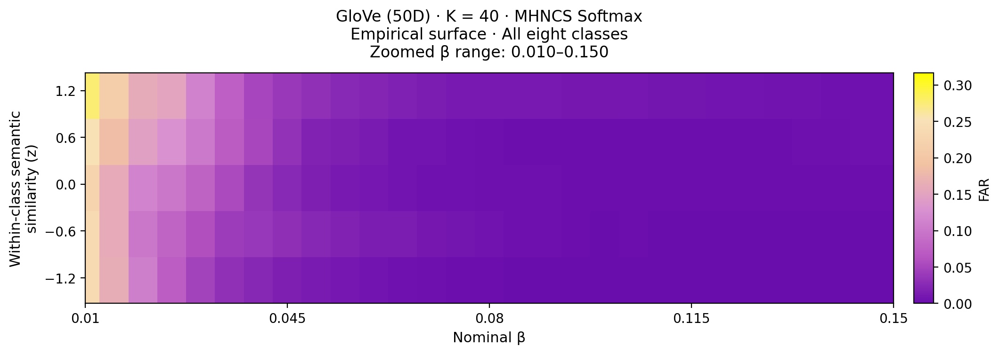

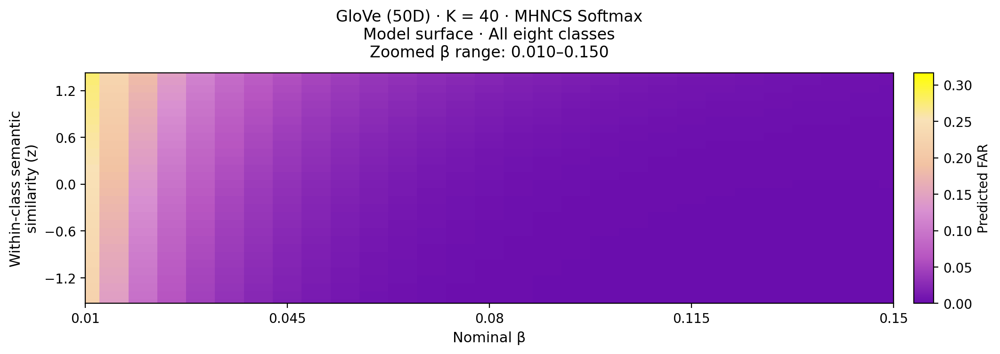

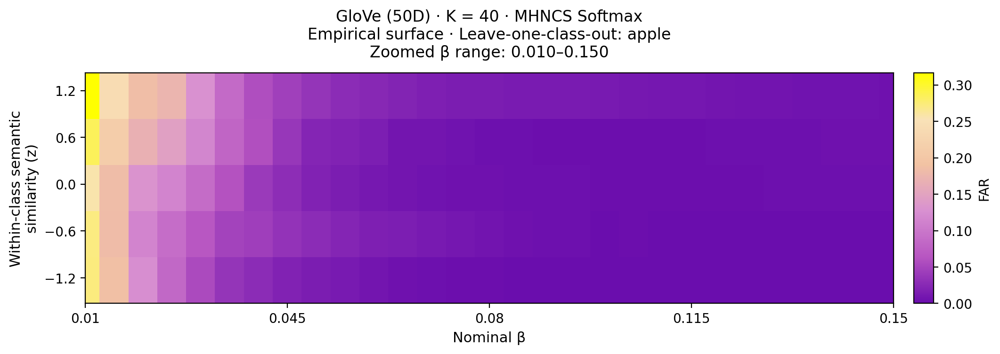

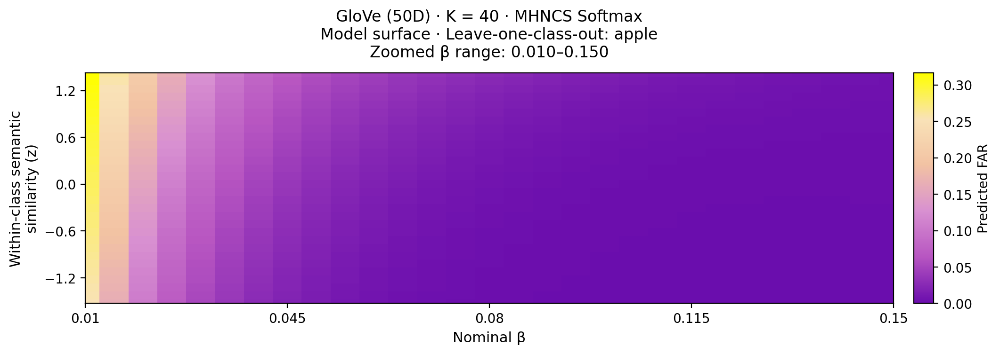

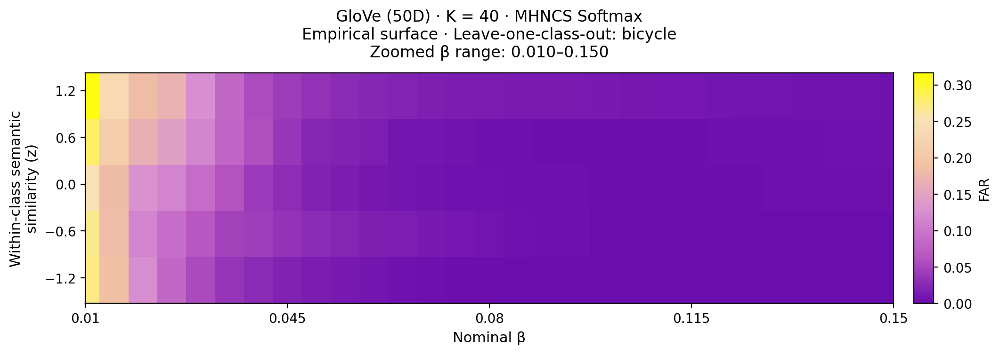

...

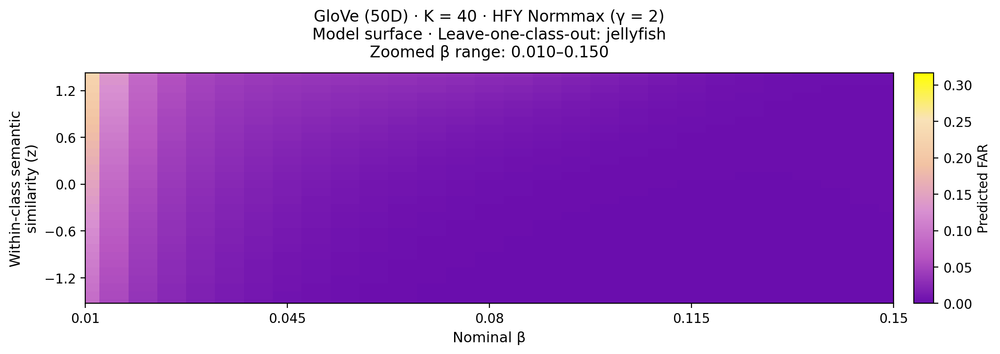

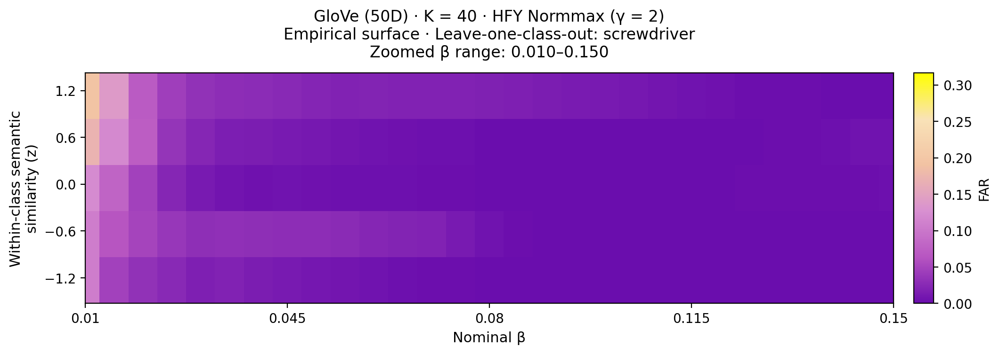

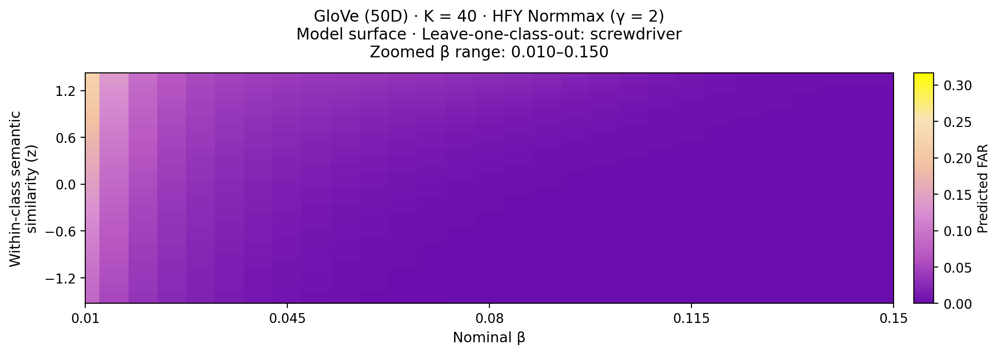

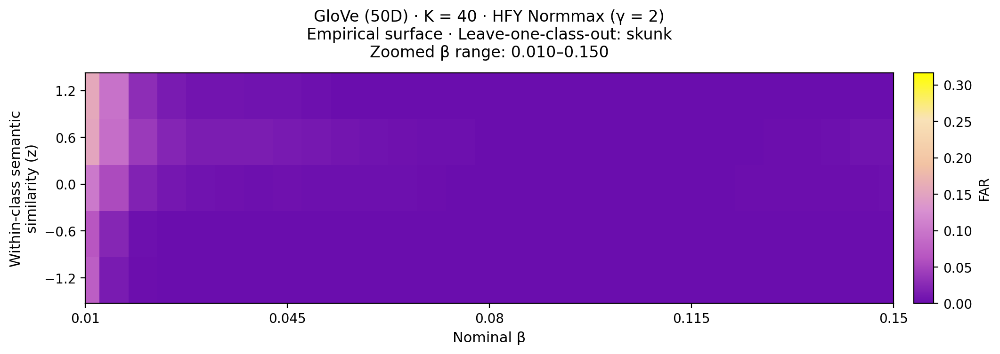

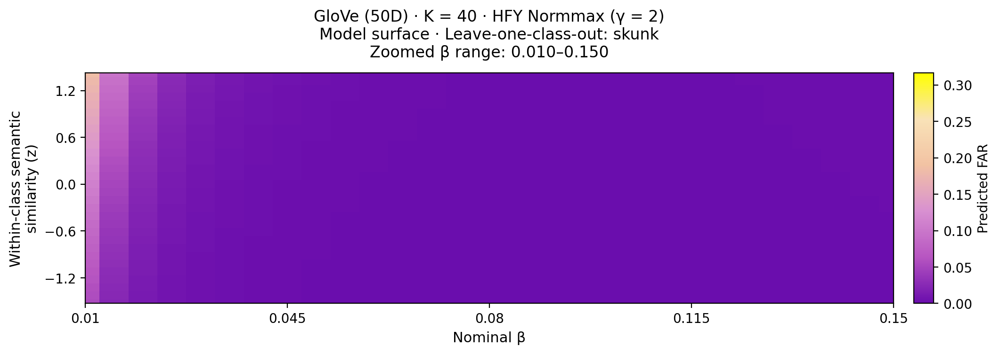

GloVe (50D) K40: 108 figures saved to \\?\C:\Users\jisaa\Documents\ProyectoTesis\EstudioEstatico\ExperimentoEstatico\SalidasRevision\Figuras\glove_k40


In [8]:
if "glove" in RESULTS:
    figs.plot_results(RESULTS["glove"], FIGURES, heatmaps=True, fit_quality=False, oof=False)


**Ajuste y sensibilidad.** Los paneles A/B/C comparan las curvas de las mallas nativas: empírica de cinco bins y modelo de 30 puntos. Las métricas matched5 y OOF se calculan por separado, sobre soporte comparable. El panel B de concordancia gráfica no es el informe estructural `B_report`.

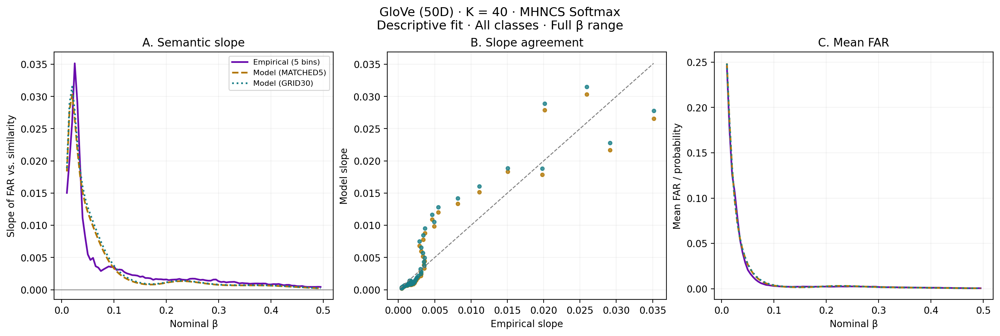

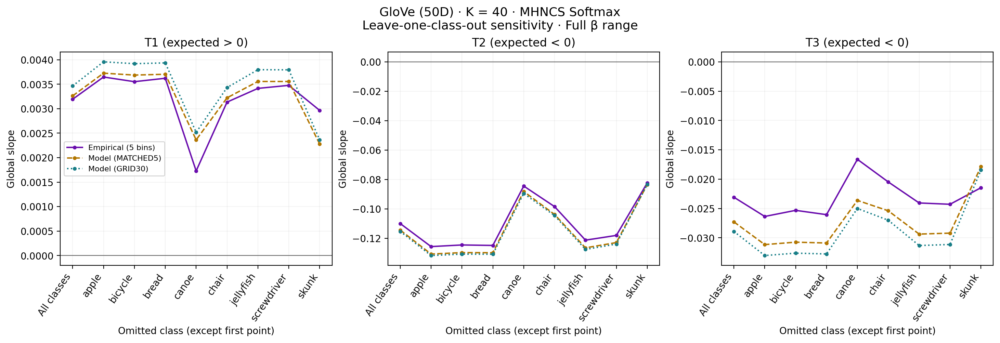

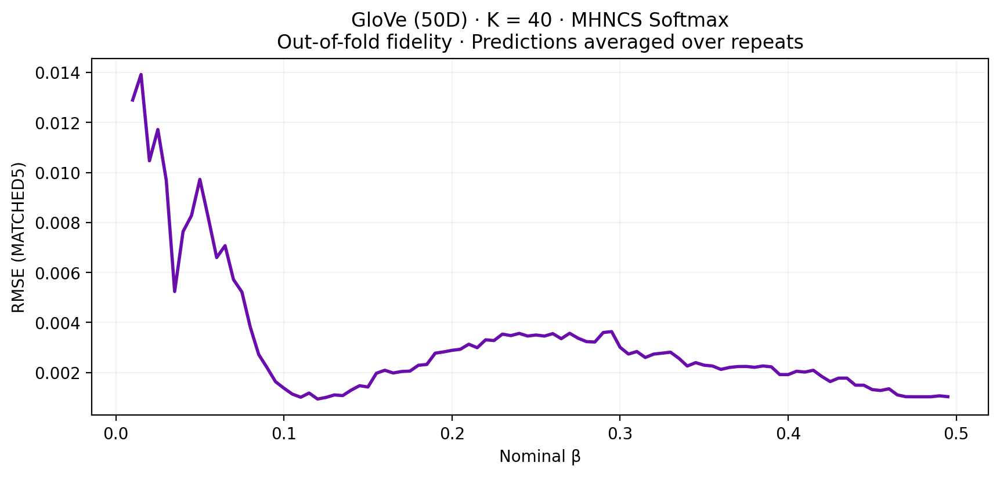

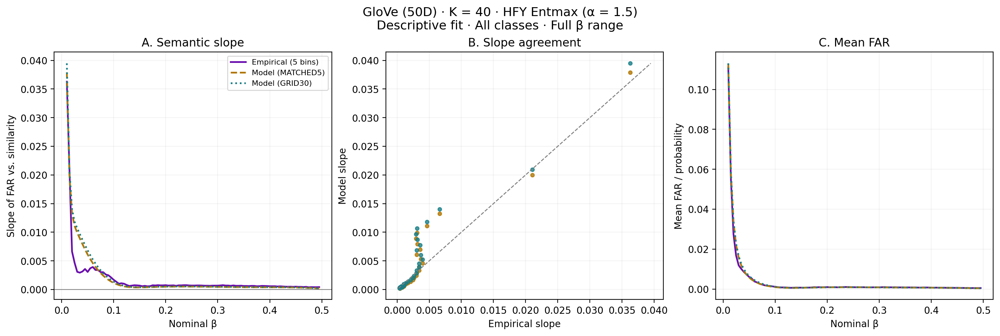

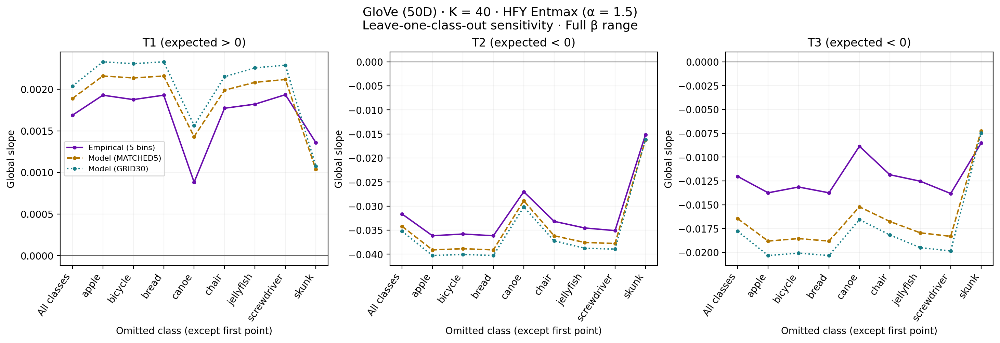

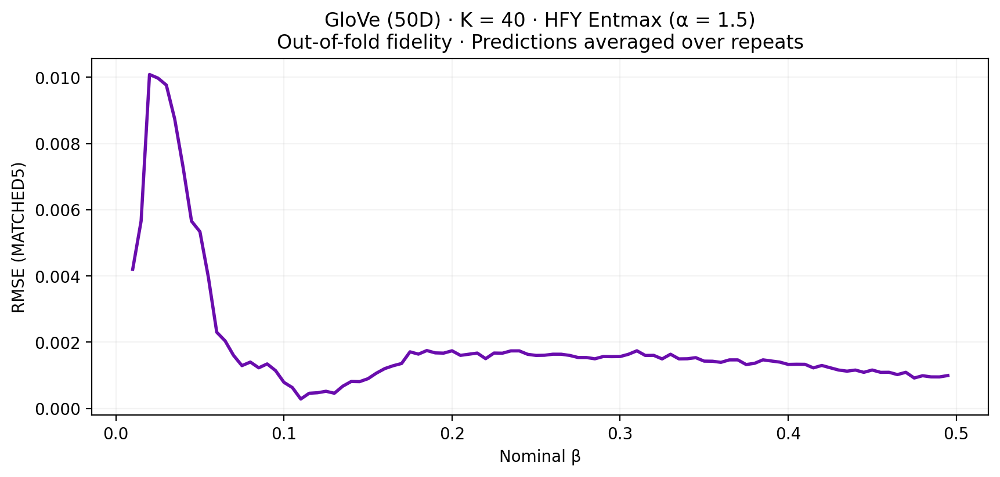

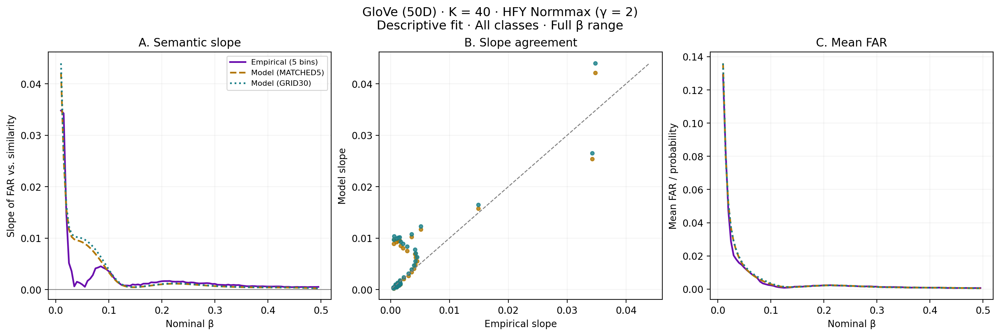

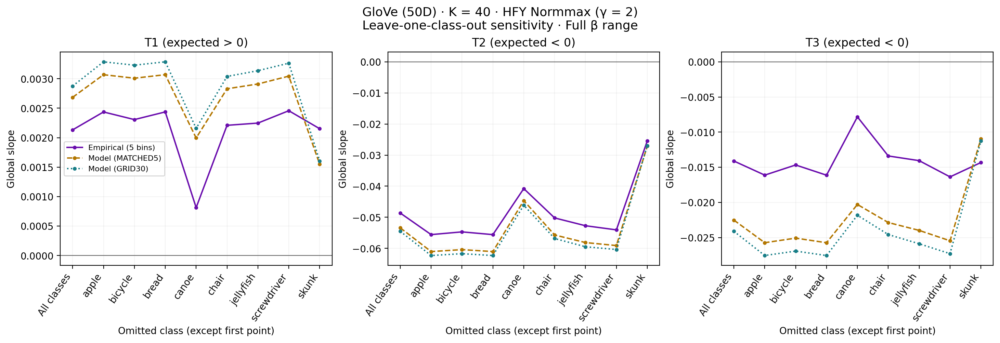

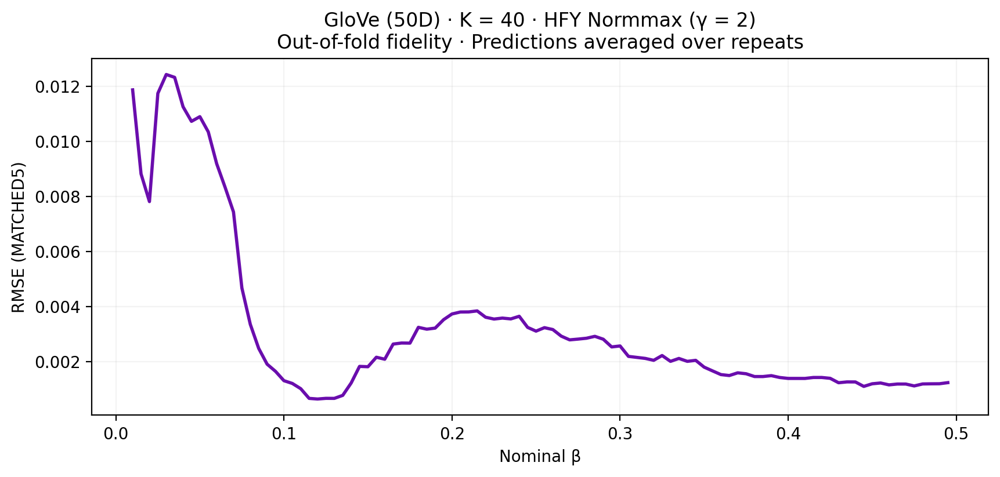

GloVe (50D) K40: 9 figures saved to \\?\C:\Users\jisaa\Documents\ProyectoTesis\EstudioEstatico\ExperimentoEstatico\SalidasRevision\Figuras\glove_k40

GloVe50 · OOF_fidelity


,network,region,RMSE,MAE,bias,max_abs_error,role
0,mhncs_softmax,ALL,0.004109,0.002629,0.000486,0.023453,OOF_REPEAT_AVERAGED_5
1,mhncs_softmax,BETA_LE_0.10,0.007954,0.006101,0.002603,0.023453,OOF_REPEAT_AVERAGED_5
2,mhncs_softmax,BETA_GT_0.10,0.002394,0.001794,-0.000024,0.007261,OOF_REPEAT_AVERAGED_5
3,hfy_entmax_a15,ALL,0.002712,0.001524,0.000216,0.014776,OOF_REPEAT_AVERAGED_5
4,hfy_entmax_a15,BETA_LE_0.10,0.005491,0.003775,0.001350,0.014776,OOF_REPEAT_AVERAGED_5
5,hfy_entmax_a15,BETA_GT_0.10,0.001368,0.000982,-0.000056,0.003491,OOF_REPEAT_AVERAGED_5
6,hfy_normmax_g2,ALL,0.004351,0.002595,0.000528,0.019000,OOF_REPEAT_AVERAGED_5
7,hfy_normmax_g2,BETA_LE_0.10,0.008733,0.006781,0.002638,0.019000,OOF_REPEAT_AVERAGED_5
8,hfy_normmax_g2,BETA_GT_0.10,0.002268,0.001588,0.000020,0.007257,OOF_REPEAT_AVERAGED_5



GloVe50 · sensitivity


,network,fit,omitted_class,omitted_label,empirical_E,M_matched5,M_grid30,stable,RMSE_matched5,MAE_matched5,...,max_abs_error,empirical_T1,empirical_T2,empirical_T3,matched5_T1,matched5_T2,matched5_T3,grid30_T1,grid30_T2,grid30_T3
0,mhncs_softmax,FULL,NaN,NaN,True,True,True,True,0.003955,0.002468,...,0.023013,0.003193,-0.109883,-0.023082,0.003261,-0.114321,-0.027282,0.003465,-0.115203,-0.028915
1,mhncs_softmax,LOCO_0_apple,0.0,apple,True,True,True,True,0.004522,0.002822,...,0.026126,0.003647,-0.125561,-0.026362,0.003726,-0.130635,-0.031158,0.003958,-0.131643,-0.033024
2,mhncs_softmax,LOCO_1_bicycle,1.0,bicycle,True,True,True,True,0.004594,0.002838,...,0.028575,0.003552,-0.124452,-0.025321,0.003687,-0.129649,-0.030744,0.003920,-0.130676,-0.032617
3,mhncs_softmax,LOCO_2_bread,2.0,bread,True,True,True,True,0.004501,0.002813,...,0.027302,0.003622,-0.124778,-0.026052,0.003703,-0.129735,-0.030889,0.003936,-0.130752,-0.032754
4,mhncs_softmax,LOCO_3_canoe,3.0,canoe,True,True,True,True,0.003674,0.001319,...,0.027374,0.001728,-0.084426,-0.016624,0.002363,-0.088096,-0.023623,0.002517,-0.089442,-0.024999
5,mhncs_softmax,LOCO_4_chair,4.0,chair,True,True,True,True,0.004497,0.002785,...,0.032404,0.003135,-0.098405,-0.020480,0.003222,-0.103763,-0.025398,0.003431,-0.104496,-0.027005
6,mhncs_softmax,LOCO_5_jellyfish,5.0,jellyfish,True,True,True,True,0.004728,0.002872,...,0.027738,0.003415,-0.121192,-0.024061,0.003556,-0.126413,-0.029369,0.003796,-0.127497,-0.031316
7,mhncs_softmax,LOCO_6_screwdriver,6.0,screwdriver,True,True,True,True,0.004375,0.002770,...,0.024467,0.003477,-0.117958,-0.024285,0.003555,-0.122831,-0.029202,0.003794,-0.123826,-0.031139
8,mhncs_softmax,LOCO_7_skunk,7.0,skunk,True,True,True,True,0.004446,0.002577,...,0.034058,0.002965,-0.082295,-0.021467,0.002277,-0.083432,-0.017872,0.002364,-0.083281,-0.018465
9,hfy_entmax_a15,FULL,NaN,NaN,True,True,True,True,0.002487,0.001398,...,0.013590,0.001687,-0.031641,-0.012032,0.001889,-0.034208,-0.016463,0.002038,-0.035235,-0.017791



GloVe50 · trend_concentration


,trend,unit,total,signed_total,sum_absolute_contributions,max_absolute_contribution_share,effective_absolute_contributors,net_to_absolute_ratio,expected_direction_mass,opposing_direction_mass,top_unit,top_signed_contribution,reconstruction_absolute_error,role,network
0,T1,WORD,0.003193,0.003193,0.011262,0.108570,26.419351,0.283485,0.007227,0.004035,opossum,0.001223,4.336809e-19,DESCRIPTIVE_ONLY_NOT_SELECTION_OR_LOCO,mhncs_softmax
1,T1,CLASS,0.003193,0.003193,0.003193,0.526399,2.949162,1.000000,0.003193,0.000000,canoe,0.001681,0.000000e+00,DESCRIPTIVE_ONLY_NOT_SELECTION_OR_LOCO,mhncs_softmax
2,T2,WORD,-0.109883,0.109883,0.110053,0.059745,48.811769,0.998457,0.109968,0.000085,opossum,0.006575,1.387779e-17,DESCRIPTIVE_ONLY_NOT_SELECTION_OR_LOCO,mhncs_softmax
3,T2,CLASS,-0.109883,0.109883,0.109883,0.344687,3.596291,1.000000,0.109883,0.000000,skunk,0.037875,0.000000e+00,DESCRIPTIVE_ONLY_NOT_SELECTION_OR_LOCO,mhncs_softmax
4,T3,WORD,-0.023082,0.023082,0.115997,0.095953,29.851944,0.198984,0.069539,0.046458,opossum,0.011130,3.469447e-18,DESCRIPTIVE_ONLY_NOT_SELECTION_OR_LOCO,mhncs_softmax
5,T3,CLASS,-0.023082,0.023082,0.023082,0.369807,4.215446,1.000000,0.023082,0.000000,canoe,0.008536,3.469447e-18,DESCRIPTIVE_ONLY_NOT_SELECTION_OR_LOCO,mhncs_softmax
6,T1,WORD,0.001687,0.001687,0.003686,0.240362,10.371051,0.457842,0.002686,0.000999,opossum,0.000886,2.168404e-19,DESCRIPTIVE_ONLY_NOT_SELECTION_OR_LOCO,hfy_entmax_a15
7,T1,CLASS,0.001687,0.001687,0.001698,0.539462,2.580039,0.993728,0.001693,0.000005,canoe,0.000916,2.168404e-19,DESCRIPTIVE_ONLY_NOT_SELECTION_OR_LOCO,hfy_entmax_a15
8,T2,WORD,-0.031641,0.031641,0.033622,0.155839,18.083824,0.941087,0.032631,0.000990,opossum,0.005240,2.081668e-17,DESCRIPTIVE_ONLY_NOT_SELECTION_OR_LOCO,hfy_entmax_a15
9,T2,CLASS,-0.031641,0.031641,0.031641,0.580003,2.437759,1.000000,0.031641,0.000000,skunk,0.018352,6.938894e-18,DESCRIPTIVE_ONLY_NOT_SELECTION_OR_LOCO,hfy_entmax_a15



GloVe50 · reuse


,stage,path,action,candidate,fits
0,model_selection,\\?\C:\Users\jisaa\Documents\ProyectoTesis\Est...,VERIFIED_REUSE,H_BETA_LINEAR_Z__ridge_1e-04,3825


In [9]:
if "glove" in RESULTS:
    figs.plot_results(RESULTS["glove"], FIGURES, heatmaps=False, fit_quality=True, oof=True)
    exp.display_tables(RESULTS["glove"], names=(
        "OOF_fidelity", "sensitivity", "trend_concentration", "reuse"
    ))

### Word2Vec · K40

Se reutiliza la corrida `3ffd8554b799`: 226 palabras FULL, 192 COMMON, 98 betas, 51 semillas de split y
10 de clasificador. Incluye los conteos CORE3, las 102 escalas HFY, el modelo ganador y los 27 FULL/LOCO.
La verificación siguiente reconstruye predicciones desde coeficientes; no llama a `prepare`, `search` ni `finish` del generador original.


In [10]:
RESULTS["w2v"] = reuse.cargar_w2v_k40(REPO, verificar_coeficientes=True, estructura=ESTRUCTURA)
reuse.mostrar_w2v(RESULTS["w2v"], ("K_selection", "input_audit", "empirical_FULL_LOCO", "decisions"))
display(pd.DataFrame([RESULTS["w2v"].verification]))


W2V K40: geometría, conteos y selección verificados; no se han ajustado modelos ni ejecutado clasificadores.
W2V K40 · K_selection


,dataset,K,criterio,grilla_candidata,K_evaluadas_hasta_seleccion,usa_T1_T2_T3,usa_LOCO
0,w2v,40,FIRST_STRUCTURALLY_ADMISSIBLE,"[20, 30, 40, 50, 60, 70, 80, 90, 100]","[20, 30, 40]",False,False


W2V K40 · input_audit


,network,K,n_words,n_common,n_rows,n_betas,n_split_seeds,n_classifier_seeds,counts_verified,calibration
0,mhncs_softmax,40,226,192,22148,98,51,10,True,Softmax λ=1
1,hfy_entmax_a15,40,226,192,22148,98,51,10,True,TRAIN-only verificada
2,hfy_normmax_g2,40,226,192,22148,98,51,10,True,TRAIN-only verificada


W2V K40 · empirical_FULL_LOCO


,network,omitted_class,T1,T2,T3,ALL3_expected
0,mhncs_softmax,NaN,0.031279,-0.587616,0.024430,False
1,mhncs_softmax,0.0,0.035760,-0.671422,0.027811,False
2,mhncs_softmax,1.0,0.035589,-0.662941,0.029708,False
3,mhncs_softmax,2.0,0.035860,-0.582917,0.026317,False
4,mhncs_softmax,3.0,0.035882,-0.575715,0.026472,False
5,mhncs_softmax,4.0,0.013086,-0.556783,0.004902,False
6,mhncs_softmax,5.0,0.033422,-0.575422,0.041043,False
7,mhncs_softmax,6.0,0.025180,-0.523942,0.008209,False
8,mhncs_softmax,7.0,0.035455,-0.551788,0.030975,False
9,hfy_entmax_a15,NaN,0.013137,-0.429829,-0.028485,True


W2V K40 · decisions


,network,scope,T1_FULL_expected,T1_LOCO_passed,T1_robust,T2_FULL_expected,T2_LOCO_passed,T2_robust,T3_FULL_expected,T3_LOCO_passed,T3_robust,T12_FULL_expected,T12_LOCO_passed,T12_robust,ALL3_FULL_expected,ALL3_LOCO_passed,ALL3_robust
0,mhncs_softmax,empirical,True,8,True,True,8,True,False,0,False,True,8,True,False,0,False
1,mhncs_softmax,matched5,True,8,True,True,8,True,False,2,False,True,8,True,False,2,False
2,mhncs_softmax,grid30,True,8,True,True,8,True,False,3,False,True,8,True,False,3,False
3,hfy_entmax_a15,empirical,True,8,True,True,8,True,True,8,True,True,8,True,True,8,True
4,hfy_entmax_a15,matched5,True,8,True,True,8,True,True,8,True,True,8,True,True,8,True
5,hfy_entmax_a15,grid30,True,8,True,True,8,True,True,8,True,True,8,True,True,8,True
6,hfy_normmax_g2,empirical,True,8,True,True,8,True,True,8,True,True,8,True,True,8,True
7,hfy_normmax_g2,matched5,True,8,True,True,8,True,True,8,True,True,8,True,True,8,True
8,hfy_normmax_g2,grid30,True,8,True,True,8,True,True,8,True,True,8,True,True,8,True


,archivos_export_verificados,diagnosticos_CV,checkpoints_CV_incluidos,checkpoints_CV_no_incluidos,refits_verificados,coeficientes_verificados,nuevos_ajustes,nuevas_clasificaciones
0,676,3825,75,3750,27,True,0,0


**Heatmaps en inglés.** Cada superficie genera una vista del intervalo definido en `FIGURES.beta_range`
para el manuscrito y otra de todo el dominio para los anexos. El mismo intervalo se aplica a GloVe K40,
W2V K40 y W2V K50, incluidos los 24 modelos LOCO de cada configuración. La paleta morado–amarillo
y los valores originales se conservan; la escala de color usa el dominio completo y no cambia con el recorte.
La similitud aumenta hacia arriba. Se muestran por defecto las vistas del manuscrito.


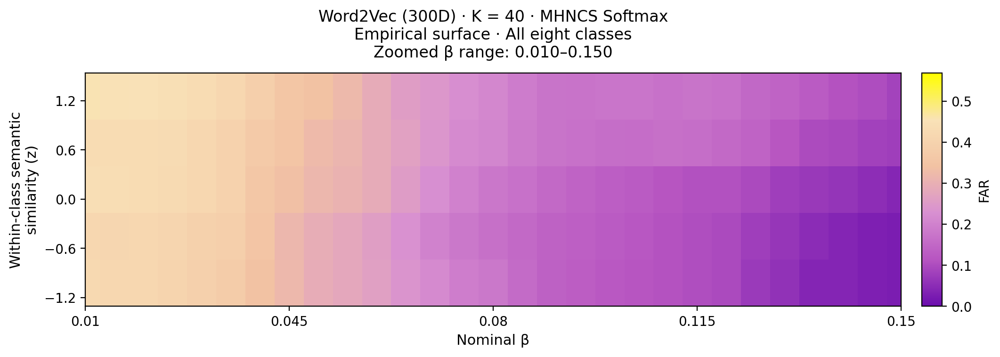

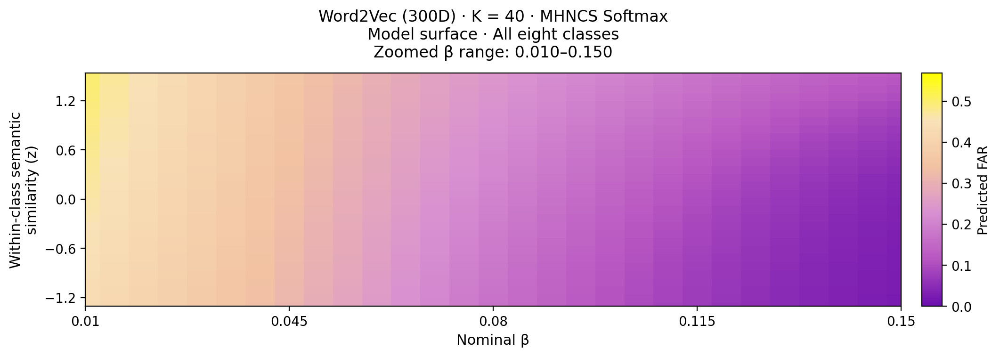

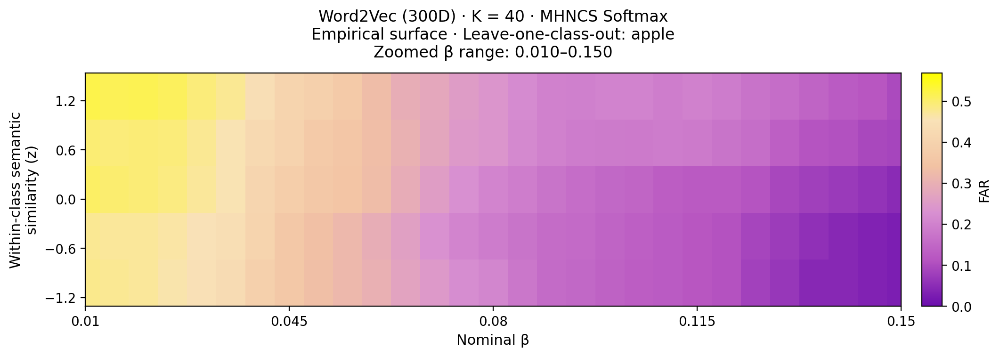

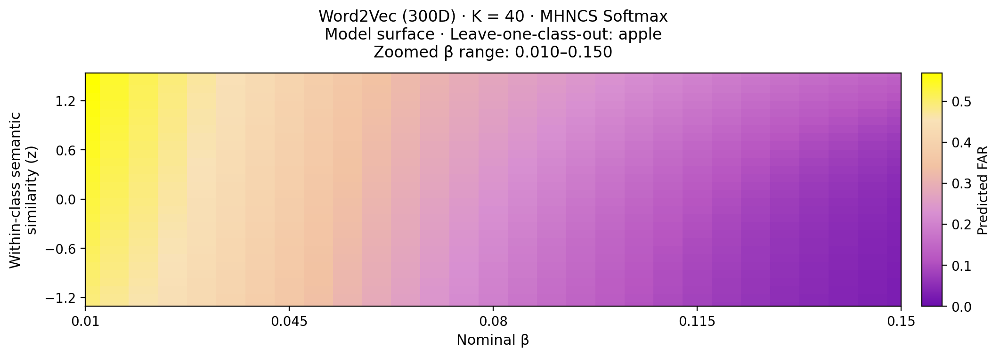

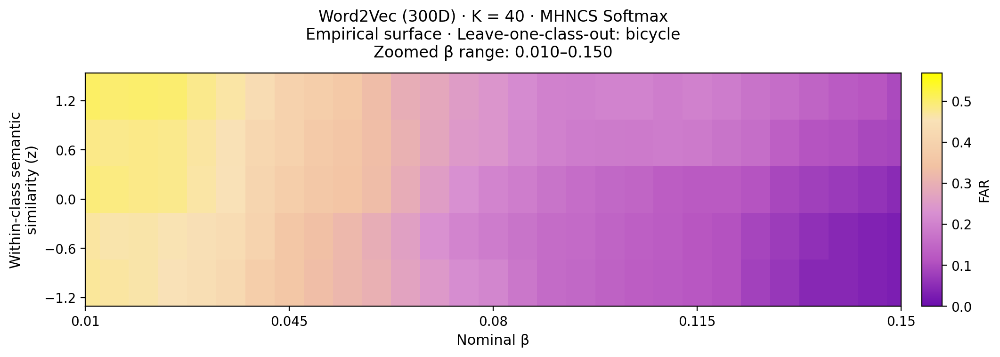

...

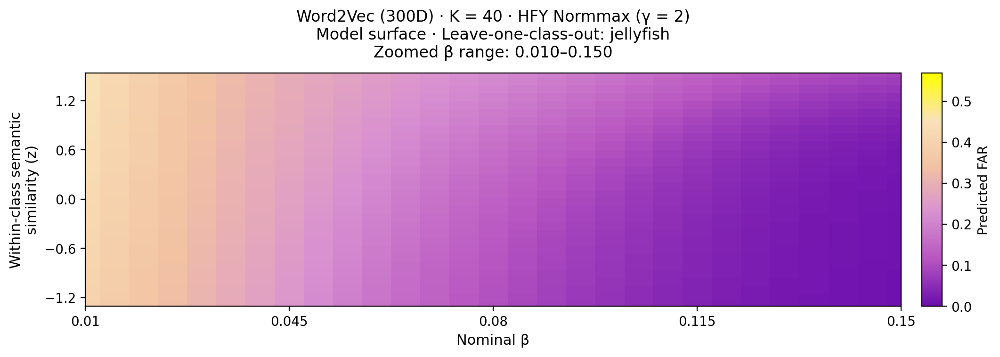

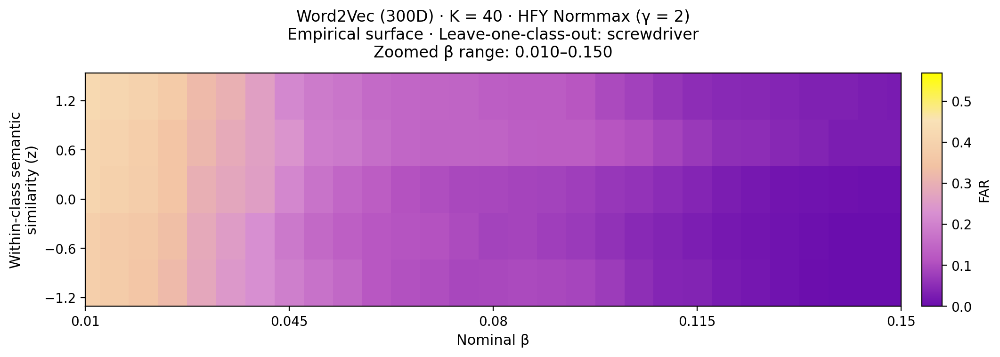

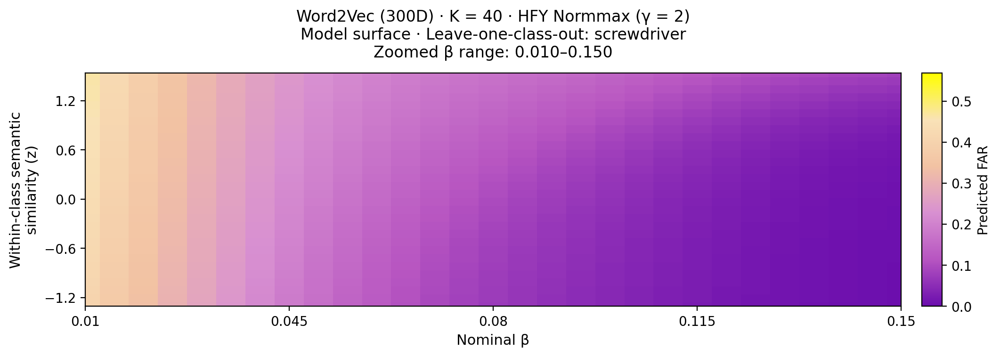

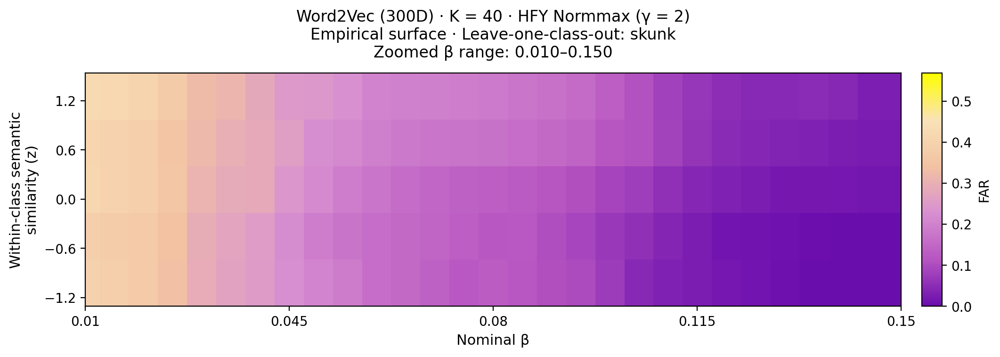

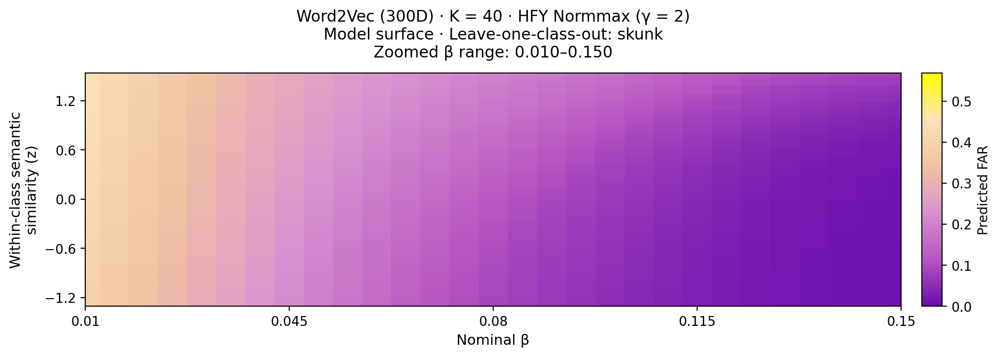

Word2Vec (300D) K40: 108 figures saved to \\?\C:\Users\jisaa\Documents\ProyectoTesis\EstudioEstatico\ExperimentoEstatico\SalidasRevision\Figuras\w2v_k40


,png,png_sha256,pdf,pdf_sha256,figure_text,kind,view,beta_min,beta_max,full_beta_min,...,n_similarity_points,vmin,vmax,surface_sha256,interpolation,smoothing,analysis_beta_range,network,case,surface
0,\\?\C:\Users\jisaa\Documents\ProyectoTesis\Est...,30f22093ad90053b17eea245e5a977f22695cd18fc6882...,\\?\C:\Users\jisaa\Documents\ProyectoTesis\Est...,79b78a66e00e8f00914730ccb82c262764a2b3b5b88f28...,"[Nominal β, 0.01, 0.01, 0.131, 0.131, 0.253, 0...",heatmap,appendix,0.01,0.495,0.01,...,5,0.0,0.567888,d3d486c18c43dc1055e80579e4debf0520511cf59ef681...,False,False,"[0.01, 0.495]",mhncs_softmax,full,empirical
1,\\?\C:\Users\jisaa\Documents\ProyectoTesis\Est...,6bb052f03c5bff49bb4c648a67934a538d80c086fb0080...,\\?\C:\Users\jisaa\Documents\ProyectoTesis\Est...,cfdbe9ec0ec8bf77941eb63bee562bca0e1e86b2b83e38...,"[Nominal β, 0.01, 0.01, 0.045, 0.045, 0.08, 0....",heatmap,manuscript,0.01,0.150,0.01,...,5,0.0,0.567888,d3d486c18c43dc1055e80579e4debf0520511cf59ef681...,False,False,"[0.01, 0.495]",mhncs_softmax,full,empirical
2,\\?\C:\Users\jisaa\Documents\ProyectoTesis\Est...,68856b396025290fbe77c167e46fd01ba7cf8735052215...,\\?\C:\Users\jisaa\Documents\ProyectoTesis\Est...,8bee8a6cfcb3eedb684b299ed99ae04fecfe053a01a888...,"[Nominal β, 0.01, 0.01, 0.131, 0.131, 0.253, 0...",heatmap,appendix,0.01,0.495,0.01,...,30,0.0,0.567888,25dbc1f50c8641cd4f72e58165d6cfa5e7bf8e7ffc79c3...,False,False,"[0.01, 0.495]",mhncs_softmax,full,model
3,\\?\C:\Users\jisaa\Documents\ProyectoTesis\Est...,4e5a23b192a2fba5cc544bab7deb5344260f9c42e9e519...,\\?\C:\Users\jisaa\Documents\ProyectoTesis\Est...,106a161bc21c840a275a39697c28dba5d3f9b45de3d707...,"[Nominal β, 0.01, 0.01, 0.045, 0.045, 0.08, 0....",heatmap,manuscript,0.01,0.150,0.01,...,30,0.0,0.567888,25dbc1f50c8641cd4f72e58165d6cfa5e7bf8e7ffc79c3...,False,False,"[0.01, 0.495]",mhncs_softmax,full,model
4,\\?\C:\Users\jisaa\Documents\ProyectoTesis\Est...,0b3f90ef1d087c4f31a322df6c44f272000cdde4712c18...,\\?\C:\Users\jisaa\Documents\ProyectoTesis\Est...,100914aa612d239c70be435f5a73c896928a842ca36dd7...,"[Nominal β, 0.01, 0.01, 0.131, 0.131, 0.253, 0...",heatmap,appendix,0.01,0.495,0.01,...,5,0.0,0.567888,c6e488502e7eff6d9bde649e535b0e0a308a2de1d5ea49...,False,False,"[0.01, 0.495]",mhncs_softmax,loco_apple,empirical
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
103,\\?\C:\Users\jisaa\Documents\ProyectoTesis\Est...,a169f259a332aeeb01f5ea6f20e6077617b295f799e905...,\\?\C:\Users\jisaa\Documents\ProyectoTesis\Est...,96542e44c274aadda47c48069138a3ffa2043049886a9b...,"[Nominal β, 0.01, 0.01, 0.045, 0.045, 0.08, 0....",heatmap,manuscript,0.01,0.150,0.01,...,30,0.0,0.567888,64c8aae166cd72d2e9c2bf1d676b735a9bf011967fadeb...,False,False,"[0.01, 0.495]",hfy_normmax_g2,loco_screwdriver,model
104,\\?\C:\Users\jisaa\Documents\ProyectoTesis\Est...,91e3d9738b73968171f5ccd16882028b534efaeda9919a...,\\?\C:\Users\jisaa\Documents\ProyectoTesis\Est...,758e76caa088afcd73d332ac52463a2d1ad223922e2cee...,"[Nominal β, 0.01, 0.01, 0.131, 0.131, 0.253, 0...",heatmap,appendix,0.01,0.495,0.01,...,5,0.0,0.567888,cc1aae3ee7acd9f17b7e3ec9dfd1516677761aba98b795...,False,False,"[0.01, 0.495]",hfy_normmax_g2,loco_skunk,empirical
105,\\?\C:\Users\jisaa\Documents\ProyectoTesis\Est...,d87e386c209313e8bfae5862040cb4611258301f630f7c...,\\?\C:\Users\jisaa\Documents\ProyectoTesis\Est...,fb8b0aeb82cd71e9a638264fdb0a80a3f25675e1d80d43...,"[Nominal β, 0.01, 0.01, 0.045, 0.045, 0.08, 0....",heatmap,manuscript,0.01,0.150,0.01,...,5,0.0,0.567888,cc1aae3ee7acd9f17b7e3ec9dfd1516677761aba98b795...,False,False,"[0.01, 0.495]",hfy_normmax_g2,loco_skunk,empirical
106,\\?\C:\Users\jisaa\Documents\ProyectoTesis\Est...,ce5db96d28fd17c9375a4d7f2fb8cd4e46ff0cfa448d36...,\\?\C:\Users\jisaa\Documents\ProyectoTesis\Est...,0f31e7722fe32d3eea7c66d098ffe60d08624d140034df...,"[Nominal β, 0.01, 0.01, 0.131, 0.131, 0.253, 0...",heatmap,appendix,0.01,0.495,0.01,...,30,0.0,0.567888,e9e2b847b39e1ed717b0102cfae19a59fed167c1f93ea6...,False,False,

In [11]:
figs.plot_results(RESULTS["w2v"], FIGURES, heatmaps=True, fit_quality=False, oof=False)


**Ajuste y sensibilidad.** Los paneles A/B/C comparan las curvas de las mallas nativas: empírica de cinco bins y modelo de 30 puntos. Las métricas matched5 y OOF se calculan por separado, sobre soporte comparable. El panel B de concordancia gráfica no es el informe estructural `B_report`.

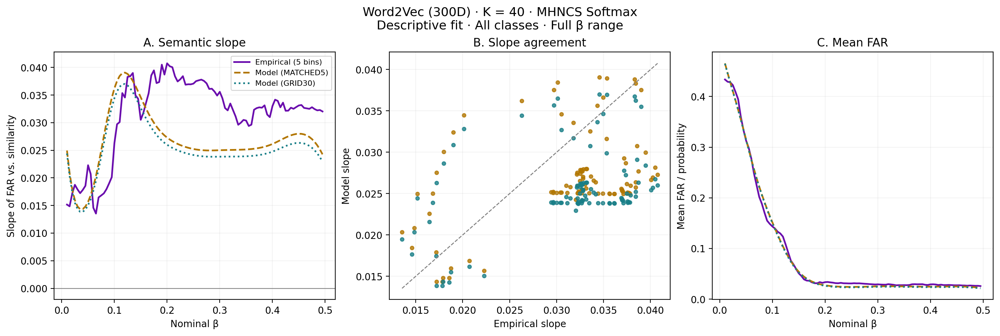

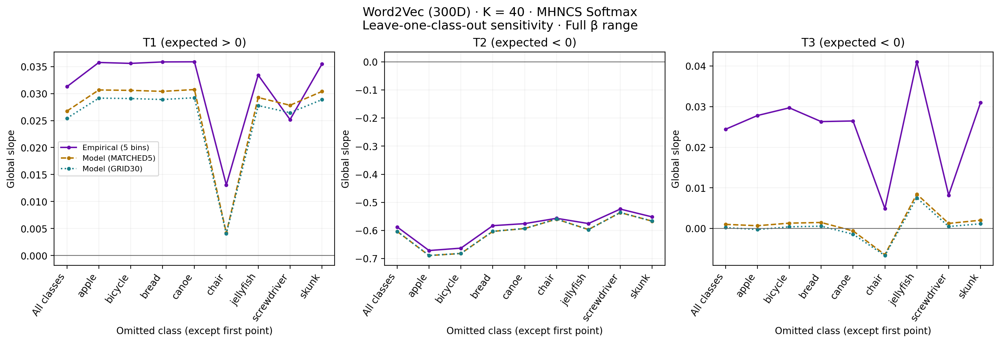

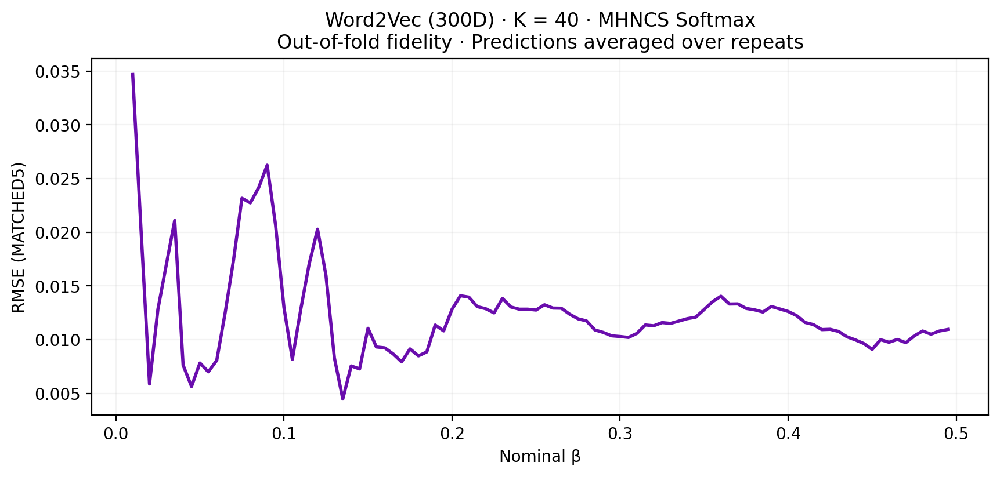

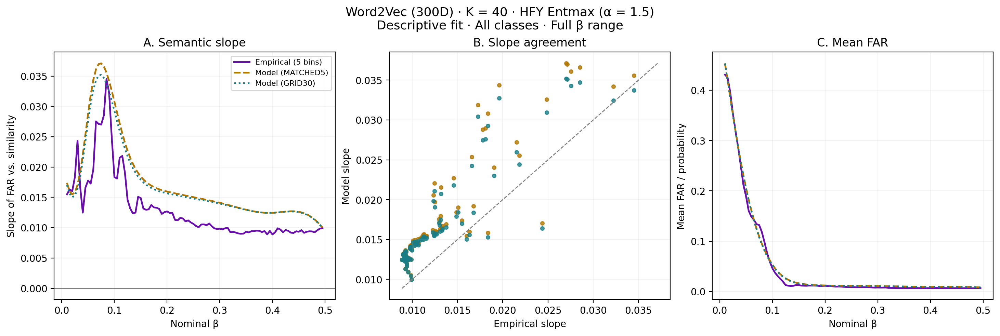

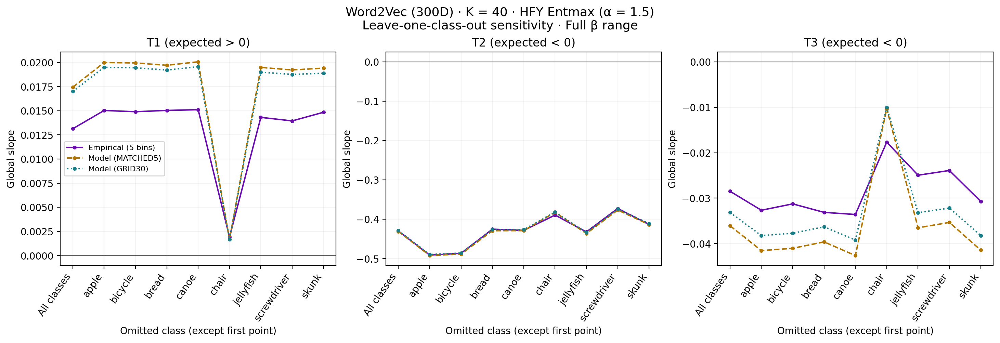

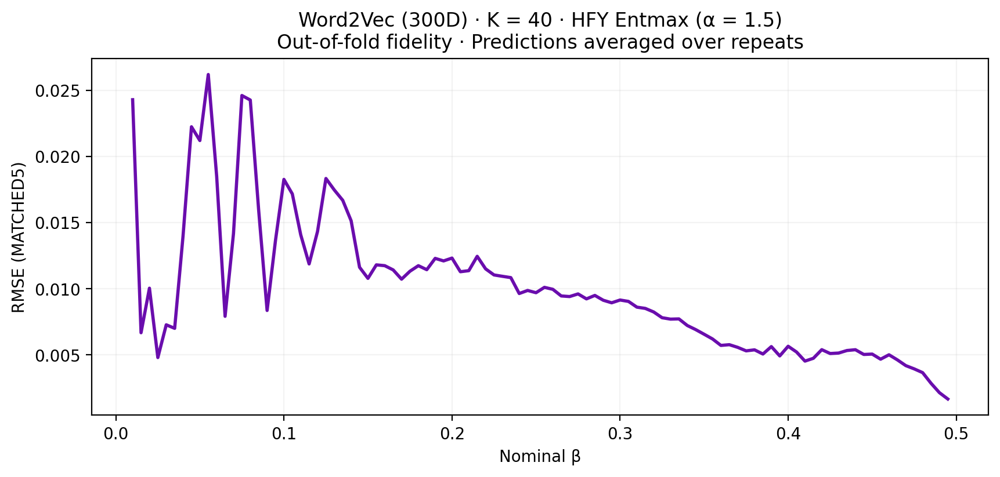

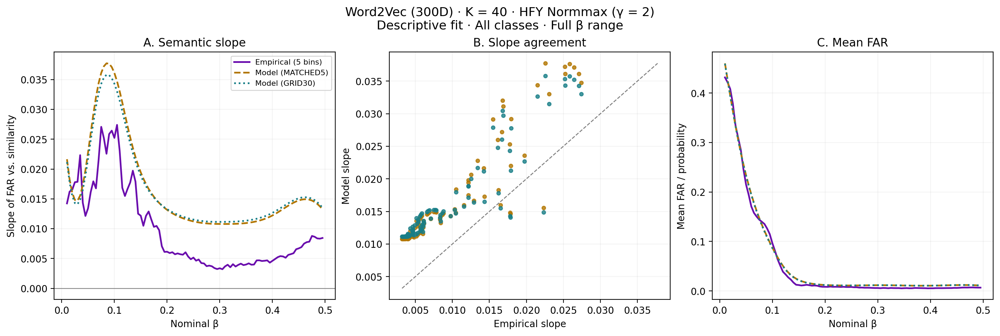

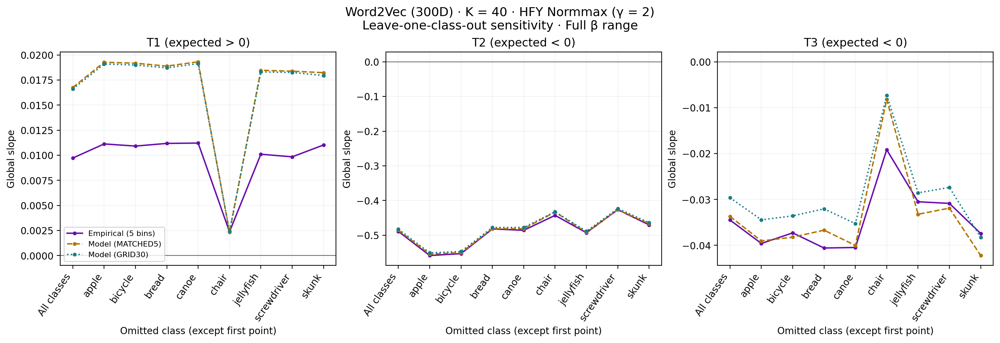

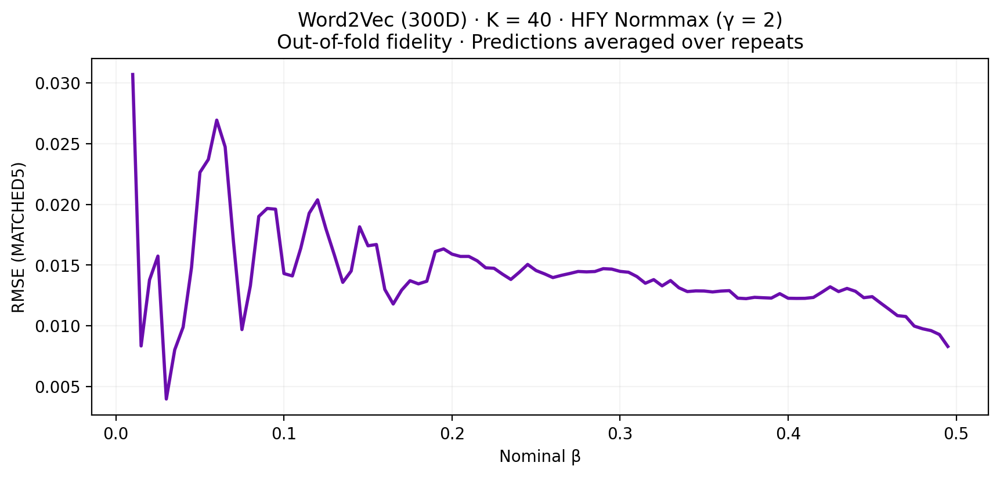

Word2Vec (300D) K40: 9 figures saved to \\?\C:\Users\jisaa\Documents\ProyectoTesis\EstudioEstatico\ExperimentoEstatico\SalidasRevision\Figuras\w2v_k40
W2V K40 · model_ranking


,candidate,family,kind,alpha,n_parameters,description,mean_logloss,sd_logloss,mean_surface_RMSE,sd_surface_RMSE,SE_logloss,SE_surface_RMSE,eligible_logloss,eligible_fidelity,selected
0,H_BETA_LINEAR_Z__ridge_1e-03,H_BETA_LINEAR_Z,hier_beta,1.000000e-03,128,"Spline de beta × similitud lineal, con desviac...",0.128174,0.001266,0.013133,0.000757,0.000566,0.000338,True,True,True
1,H_BETA_LINEAR_Z__ridge_1e-02,H_BETA_LINEAR_Z,hier_beta,1.000000e-02,128,"Spline de beta × similitud lineal, con desviac...",0.128594,0.001160,0.015202,0.000590,0.000519,0.000264,True,False,False
2,H_TENSOR__ridge_1e-02,H_TENSOR,hier_tensor,1.000000e-02,288,Superficie spline bidimensional con desviacion...,0.129055,0.001778,0.014617,0.000755,0.000795,0.000338,False,False,False
3,H_BETA_LINEAR_Z__ridge_1e-04,H_BETA_LINEAR_Z,hier_beta,1.000000e-04,128,"Spline de beta × similitud lineal, con desviac...",0.129440,0.001418,0.012829,0.000760,0.000634,0.000340,False,False,False
4,H_TENSOR__ridge_1e-03,H_TENSOR,hier_tensor,1.000000e-03,288,Superficie spline bidimensional con desviacion...,0.130420,0.002422,0.014380,0.000858,0.001083,0.000384,False,False,False
5,H_BETA_LINEAR_Z__ridge_1e-05,H_BETA_LINEAR_Z,hier_beta,1.000000e-05,128,"Spline de beta × similitud lineal, con desviac...",0.130824,0.001666,0.012611,0.000752,0.000745,0.000336,False,False,False
6,H_BETA_LINEAR_Z__ridge_1e-06,H_BETA_LINEAR_Z,hier_beta,1.000000e-06,128,"Spline de beta × similitud lineal, con desviac...",0.132542,0.001599,0.012481,0.000758,0.000715,0.000339,False,False,False
7,H_TENSOR__ridge_1e-01,H_TENSOR,hier_tensor,1.000000e-01,288,Superficie spline bidimensional con desviacion...,0.134322,0.001146,0.022373,0.000396,0.000512,0.000177,False,False,False
8,H_BETA_LINEAR_Z__ridge_1e-07,H_BETA_LINEAR_Z,hier_beta,1.000000e-07,128,"Spline de beta × similitud lineal, con desviac...",0.135101,0.004275,0.012423,0.000763,0.001912,0.000341,False,False,False
9,H_TENSOR__ridge_1e-04,H_TENSOR,hier_tensor,1.000000e-04,288,Superficie spline bidimensional con desviacion...,0.135251,0.002602,0.014612,0.000812,0.001164,0.000363,False,False,False


W2V K40 · OOF


,network,repeat,OOF_logloss,OOF_surface_RMSE,OOF_brier_fraction,OOF_brier_bernoulli
0,mhncs_softmax,0,0.159847,0.014010,0.006533,0.049217
1,hfy_entmax_a15,0,0.099168,0.011912,0.003567,0.030333
2,hfy_normmax_g2,0,0.122206,0.016103,0.004704,0.035703
3,mhncs_softmax,1,0.163619,0.012455,0.007621,0.050305
4,hfy_entmax_a15,1,0.101900,0.012888,0.004527,0.031293
5,hfy_normmax_g2,1,0.125135,0.016180,0.005769,0.036769
6,mhncs_softmax,2,0.164802,0.012787,0.007353,0.050036
7,hfy_entmax_a15,2,0.098269,0.010157,0.003177,0.029943
8,hfy_normmax_g2,2,0.122591,0.013906,0.004278,0.035277
9,mhncs_softmax,3,0.161431,0.013666,0.006652,0.049336


W2V K40 · fidelity


,network,case,role,region,RMSE,MAE,bias,max_abs_error
0,mhncs_softmax,OOF_r0,OOF_SELECTION_CONDITIONAL,ALL,0.014010,0.011386,-0.000774,0.048375
1,mhncs_softmax,OOF_r0,OOF_SELECTION_CONDITIONAL,BETA_LE_010,0.017857,0.014402,0.006779,0.048375
2,mhncs_softmax,OOF_r0,OOF_SELECTION_CONDITIONAL,BETA_GT_010,0.012915,0.010661,-0.002591,0.029704
3,hfy_entmax_a15,OOF_r0,OOF_SELECTION_CONDITIONAL,ALL,0.011912,0.007615,0.003271,0.042936
4,hfy_entmax_a15,OOF_r0,OOF_SELECTION_CONDITIONAL,BETA_LE_010,0.017003,0.013336,0.001297,0.042936
...,...,...,...,...,...,...,...,...
130,hfy_normmax_g2,LOCO_screwdriver,IN_SAMPLE_MATCHED5,BETA_LE_010,0.019707,0.016009,0.004250,0.044569
131,hfy_normmax_g2,LOCO_screwdriver,IN_SAMPLE_MATCHED5,BETA_GT_010,0.012579,0.007585,0.004922,0.047336
132,hfy_normmax_g2,LOCO_skunk,IN_SAMPLE_MATCHED5,ALL,0.013754,0.010510,0.004581,0.049083
133,hfy_normmax_g2,LOCO_skunk,IN_SAMPLE_MATCHED5,BETA_LE_010,0.015377,0.012988,0.000224,0.035349


W2V K40 · FULL_LOCO


,network,case,omitted_class,stable,empirical_T1,empirical_T2,empirical_T3,empirical_T1_expected,empirical_T2_expected,empirical_T3_expected,...,grid30_T3_expected,grid30_T12_expected,grid30_ALL3_expected,aggregation_only_T1,refit_minus_aggregation_T1,aggregation_only_T2,refit_minus_aggregation_T2,aggregation_only_T3,refit_minus_aggregation_T3,RMSE_refit_vs_aggregation_only
0,mhncs_softmax,FULL,NaN,True,0.031279,-0.587616,0.024430,True,True,False,...,False,True,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,mhncs_softmax,LOCO_apple,0.0,True,0.035760,-0.671422,0.027811,True,True,False,...,True,True,True,0.029136,1.840761e-05,-0.688889,-1.187037e-04,-0.000327,0.000065,0.000169
2,mhncs_softmax,LOCO_bicycle,1.0,True,0.035589,-0.662941,0.029708,True,True,False,...,False,True,False,0.029064,1.507911e-05,-0.681622,-9.148288e-05,0.000333,0.000067,0.000134
3,mhncs_softmax,LOCO_bread,2.0,True,0.035860,-0.582917,0.026317,True,True,False,...,False,True,False,0.028884,1.154533e-05,-0.603266,1.706556e-04,0.000521,0.000036,0.000209
4,mhncs_softmax,LOCO_canoe,3.0,True,0.035882,-0.575715,0.026472,True,True,False,...,True,True,True,0.029215,1.028693e-05,-0.593056,1.277321e-04,-0.001434,0.000019,0.000133
5,mhncs_softmax,LOCO_chair,4.0,True,0.013086,-0.556783,0.004902,True,True,False,...,True,True,True,0.004042,-5.175809e-07,-0.559309,1.013995e-05,-0.006655,-0.000023,0.000114
6,mhncs_softmax,LOCO_jellyfish,5.0,True,0.033422,-0.575422,0.041043,True,True,False,...,False,True,False,0.027796,-1.622744e-05,-0.597039,-9.329832e-05,0.007572,-0.000038,0.000254
7,mhncs_softmax,LOCO_screwdriver,6.0,True,0.025180,-0.523942,0.008209,True,True,False,...,False,True,False,0.026473,-2.385773e-05,-0.536136,-6.635987e-05,0.000585,-0.000109,0.000164
8,mhncs_softmax,LOCO_skunk,7.0,True,0.035455,-0.551788,0.030975,True,True,False,...,False,True,False,0.028871,3.272669e-06,-0.566787,1.592682e-04,0.001110,0.000036,0.000094
9,hfy_entmax_a15,FULL,NaN,True,0.013137,-0.429829,-0.028485,True,True,True,...,True,True,True,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [12]:
figs.plot_results(RESULTS["w2v"], FIGURES, heatmaps=False, fit_quality=True, oof=True)
reuse.mostrar_w2v(RESULTS["w2v"], ("model_ranking", "OOF", "fidelity", "FULL_LOCO"))


## 4. Cierre conjunto

Se resumen únicamente las ramas cargadas en esta sesión. Los signos no deciden la admisibilidad de K40.
Un resumen con sólo W2V está incompleto para el conjunto del estudio, aunque esa rama ya sea verificable.


In [13]:
if RESULTS:
    display(reuse.resumen_conjunto(RESULTS))
    print("Datasets cargados:", ", ".join(RESULTS))
    print("Pendientes:", sorted(set(DATASET_KEYS) - set(RESULTS)))


,dataset,K,network,modelo,tres_signos_modelo,LOCO_tres_signos,T1_modelo,T2_modelo,T3_modelo
0,glove,40,mhncs_softmax,H_BETA_LINEAR_Z__ridge_1e-04,True,8,NaN,NaN,NaN
1,glove,40,hfy_entmax_a15,H_BETA_LINEAR_Z__ridge_1e-04,True,8,NaN,NaN,NaN
2,glove,40,hfy_normmax_g2,H_BETA_LINEAR_Z__ridge_1e-04,True,8,NaN,NaN,NaN
3,w2v,40,mhncs_softmax,H_BETA_LINEAR_Z__ridge_1e-03,NaN,3,True,True,False
4,w2v,40,hfy_entmax_a15,H_BETA_LINEAR_Z__ridge_1e-03,NaN,8,True,True,True
5,w2v,40,hfy_normmax_g2,H_BETA_LINEAR_Z__ridge_1e-03,NaN,8,True,True,True


Datasets cargados: glove, w2v
Pendientes: []


## 5. Informes y reutilización

Las superficies, los conteos y los coeficientes se reutilizan sin optimización.
Todas las figuras de este notebook se regeneran en inglés mediante `figuras_estudio.py`.
No se muestran los PNG históricos en español que permanecen en los archivos fuente.
Las imágenes y PDF están en `SalidasRevision/Figuras/<dataset>_k<K>/`:

- `manuscript_beta_.../`: heatmaps con el intervalo elegido.
- `appendix_full/`: heatmaps completos.
- `diagnostics/`: ajuste, sensibilidad LOCO y OOF, sobre todo el dominio de β.

La selección de K queda en `SalidasRevision/auditoria_grilla_K20_K100`.


In [14]:
for key, result in RESULTS.items():
    print(key, "→", result.output_dir / "report")

print("Figuras PNG/PDF:", FIGURES.output_root)


glove → \\?\C:\Users\jisaa\Documents\ProyectoTesis\EstudioEstatico\ExperimentoEstatico\SalidasRevision\estatico\glove\run_f49b9fac0fd05760fb36\report
w2v → \\?\C:\Users\jisaa\Documents\ProyectoTesis\EstudioEstatico\ExperimentoEstatico\SalidasRevision\archivos\E2_W2V_K40_modelo_3ffd8554b799_resultados\report
Figuras PNG/PDF: \\?\C:\Users\jisaa\Documents\ProyectoTesis\EstudioEstatico\ExperimentoEstatico\SalidasRevision\Figuras


## Apéndice A. Sensibilidad de W2V a K50

Incluye el contraste empírico K40/K50 y el modelo K50 completo, con CV, OOF, FULL/LOCO y figuras.
Todos los archivos necesarios están incluidos y se conectan automáticamente.
`VERIFICAR_MODELO_K50=True` ejecuta la lectura y verificación del anexo, sin entrenar ni ajustar modelos.

K50 está fijada como configuración del anexo y no modifica la selección estructural principal K40.
Los protocolos originales se conservan como procedencia; su antigua selección empírica no se aplica
para elegir la K del estudio principal. El modelo archivado K50 usa Ridge=0.01 y K40 Ridge=0.001:
la comparación de modelos cambia ambas condiciones, por lo que no aísla únicamente el efecto de K.


In [15]:
display(RESULTS["w2v"].tables["sensibilidad_K50"])


,network,T1_K50_minus_K40,T2_K50_minus_K40,T3_K50_minus_K40
0,mhncs_softmax,-0.020968,-0.118183,-0.034390
1,hfy_entmax_a15,-0.009755,-0.034490,0.001757
2,hfy_normmax_g2,-0.005860,-0.023372,0.009397


In [16]:
VERIFICAR_MODELO_K50 = True
SENSIBILIDAD_K50 = {}
if VERIFICAR_MODELO_K50:
    SENSIBILIDAD_K50["w2v"] = reuse.cargar_w2v_k50(REPO, ESTRUCTURA)
    exp.display_tables(SENSIBILIDAD_K50["w2v"], names=(
        "K_selection", "calibration", "empirical_CORE3", "model_ranking", "final_status"
    ))


W2V300 : 3.825 checkpoints CV autenticados; sin repetir ajustes.
W2V300: mhncs_softmax, FULL + 8 LOCO completos.
W2V300: hfy_entmax_a15, FULL + 8 LOCO completos.
W2V300: hfy_normmax_g2, FULL + 8 LOCO completos.

BEGIN_COPY_TABLE::STATIC_RECTOR_FULL
       network  stable  n_words  n_classes  active_parameters  alpha       T1        T2        T3    E  E_5bins  RMSE_in_sample_5bins  gradient_inf
 mhncs_softmax    True      270          8                128   0.01 0.011096 -0.685496 -0.021470 True     True              0.016163  6.898933e-09
hfy_entmax_a15    True      270          8                128   0.01 0.007789 -0.445241 -0.031101 True     True              0.016202  1.081751e-09
hfy_normmax_g2    True      270          8                128   0.01 0.010674 -0.493954 -0.024890 True     True              0.020461  2.404053e-09
END_COPY_TABLE::STATIC_RECTOR_FULL

BEGIN_COPY_TABLE::STATIC_RECTOR_LOCO_SUMMARY
       network  FULL_E  FULL_E_5bins  n_omissions  n_omissions_expected  R_CLA

,dataset,K,rol,K_principal,criterio,seleccion_principal_modificada,ridge_K40,ridge_K50
0,w2v,50,ANEXO_SENSIBILIDAD,40,K50_FIJADA_PARA_EL_ANEXO,False,0.001,0.01



W2V300 · calibration


,K,calibration_uses_errors,calibration_uses_validation,lambda_at_boundary,lambda_value,maximum_recall_delta,n_memories,n_objective_evaluations,network,objective_calibrated,objective_reduction_fraction,objective_reference,seconds,split_seed,train_array_sha,train_words_sha
0,50,False,False,False,0.103383,2.775558e-16,268,12,hfy_entmax_a15,0.008306,0.998984,8.178396,51.502067,0,f769d4bd59a0876e9fda4c97d45f3e41298af14eaf270e...,6a7adf823e2a6fb120ba35d52ca0de69b9cc4373c8d95f...
1,50,False,False,False,0.104134,2.775558e-16,268,11,hfy_entmax_a15,0.010820,0.998690,8.259093,48.095130,1,165880dc0d5243465ae9cf7be2b09e6e83eb2eb3e98e15...,0048bc6eab3371eb91cd84cb72c28817378b108a4b2f31...
2,50,False,False,False,0.102554,4.440892e-16,268,12,hfy_entmax_a15,0.008193,0.998981,8.041968,51.476617,2,bfc94499fa8008e916bc8c1ddb60e74f0d39f50142c85b...,60bdc546fab25edba81ab324c858f142737b645085cd0f...
3,50,False,False,False,0.103491,2.220446e-16,268,12,hfy_entmax_a15,0.010046,0.998755,8.071001,51.538757,3,7b203e816ef3e2f195642dabdecb71b77167fe638ea956...,757bf1ecc6e67f3e111cd6e267608bfecf5da08a56b2e5...
4,50,False,False,False,0.104723,3.330669e-16,268,11,hfy_entmax_a15,0.009744,0.998806,8.157941,48.274531,4,932ec6c37e7274cb24c95e0a8d6e1ee7c13cade58db263...,1c9821d45dff4720526771d5bc40b0a622ac42b4c552b4...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
97,50,False,False,False,0.096684,4.440892e-16,268,13,hfy_normmax_g2,0.020049,0.997907,9.581436,55.144706,46,6e2ef940e722d53c42da5d2c65f3cf7d03e9cc257fda50...,eaa1ab2eff8ecc6a7411fb3d813539331ea14be8c9c839...
98,50,False,False,False,0.095792,2.220446e-16,268,13,hfy_normmax_g2,0.015764,0.998333,9.457171,55.067695,47,97b8c93d652f951de18714b1a7524d9358e3b5b119eee1...,6e99b1ca17cf4d427b8f3bf988cf8176cbdab241070e41...
99,50,False,False,False,0.096150,3.330669e-16,268,13,hfy_normmax_g2,0.015551,0.998410,9.779480,37.244668,48,9950ff75876e714aff3ff1e1d9a966a296d715526769dc...,b4b30bea52d96280f098cf707086cf4c4d3c010e3e9c20...
100,50,False,False,False,0.095419,2.775558e-16,268,13,hfy_normmax_g2,0.015140,0.998410,9.523684,37.038910,49,c870feb636777b4924aaf346777ed71c44421d8feba8b1...,d6f58fdf6a679b012d34812c960d0919c4d1b765ccd293...



W2V300 · empirical_CORE3


,network,K,condition,role,A,counts_valid,n_full_words,n_common_words,n_bins,n_splits,n_betas,n_classifier_seeds,T1,T2,T3,ALL3_expected,R_CLASS,n_class_omissions_expected,B_report
0,mhncs_softmax,50,RAW,REFERENCE,True,True,270,222,5,51,98,10,0.010311,-0.705800,-0.009960,True,True,8,True
1,hfy_entmax_a15,50,RAW,DATASET_TRAIN_SCALE_MATCHED,True,True,270,222,5,51,98,10,0.003382,-0.464319,-0.026728,True,True,8,True
2,hfy_normmax_g2,50,RAW,DATASET_TRAIN_SCALE_MATCHED,True,True,270,222,5,51,98,10,0.003865,-0.512405,-0.025082,True,True,8,True



W2V300 · model_ranking


,candidate,family,kind,alpha,n_parameters,description,mean_logloss,sd_logloss,mean_surface_RMSE,sd_surface_RMSE,SE_logloss,SE_surface_RMSE,eligible_logloss,eligible_fidelity,selected
0,H_BETA_LINEAR_Z__ridge_1e-02,H_BETA_LINEAR_Z,hier_beta,1.000000e-02,128,"Spline de beta × similitud lineal, con desviac...",0.128529,0.002269,0.018043,0.000184,0.001015,0.000082,True,True,True
1,H_TENSOR__ridge_1e-01,H_TENSOR,hier_tensor,1.000000e-01,288,Superficie spline bidimensional con desviacion...,0.133077,0.004156,0.026936,0.000267,0.001858,0.000120,False,False,False
2,S_TENSOR_SHARED__ridge_1e-02,S_TENSOR_SHARED,spline_tensor,1.000000e-02,55,Superficie spline bidimensional compartida + c...,0.134886,0.001184,0.018494,0.001094,0.000530,0.000489,False,False,False
3,S_TENSOR_SHARED__ridge_1e-03,S_TENSOR_SHARED,spline_tensor,1.000000e-03,55,Superficie spline bidimensional compartida + c...,0.135239,0.001305,0.018561,0.002008,0.000584,0.000898,False,False,False
4,H_BETA_LINEAR_Z__ridge_1e-03,H_BETA_LINEAR_Z,hier_beta,1.000000e-03,128,"Spline de beta × similitud lineal, con desviac...",0.136670,0.004311,0.014992,0.000215,0.001928,0.000096,False,False,False
5,H_BETA_LINEAR_Z__ridge_1e-01,H_BETA_LINEAR_Z,hier_beta,1.000000e-01,128,"Spline de beta × similitud lineal, con desviac...",0.137119,0.000520,0.040709,0.000131,0.000233,0.000059,False,False,False
6,S_TENSOR_SHARED__ridge_1e-04,S_TENSOR_SHARED,spline_tensor,1.000000e-04,55,Superficie spline bidimensional compartida + c...,0.137877,0.001298,0.018094,0.001893,0.000581,0.000847,False,False,False
7,H_TENSOR__ridge_1e-02,H_TENSOR,hier_tensor,1.000000e-02,288,Superficie spline bidimensional con desviacion...,0.138215,0.009120,0.018033,0.000757,0.004078,0.000338,False,False,False
8,S_ADDITIVE__ridge_1e-03,S_ADDITIVE,spline_additive,1.000000e-03,20,Clase + spline(beta) + spline(similitud),0.138705,0.001371,0.022119,0.002599,0.000613,0.001162,False,False,False
9,S_ADDITIVE__ridge_1e-02,S_ADDITIVE,spline_additive,1.000000e-02,20,Clase + spline(beta) + spline(similitud),0.138891,0.000680,0.023769,0.001314,0.000304,0.000588,False,False,False



W2V300 · final_status


,network,A,E_empirical,empirical_LOCO_passed,R_EMP,M_matched5,model_LOCO_passed_5,R_MODEL_matched5,M_grid30,model_LOCO_passed_30,R_MODEL_grid30,primary_model_grid,M_primary,R_MODEL_primary,B_report,ALL_FITS_STABLE,CORE3_component,empirical_model5_E_disagreements,model5_grid30_E_disagreements
0,mhncs_softmax,True,True,8,True,True,8,True,True,8,True,grid30,True,True,True,True,True,0,0
1,hfy_entmax_a15,True,True,8,True,True,8,True,True,8,True,grid30,True,True,True,True,True,0,0
2,hfy_normmax_g2,True,True,8,True,True,8,True,True,8,True,grid30,True,True,True,True,True,0,0


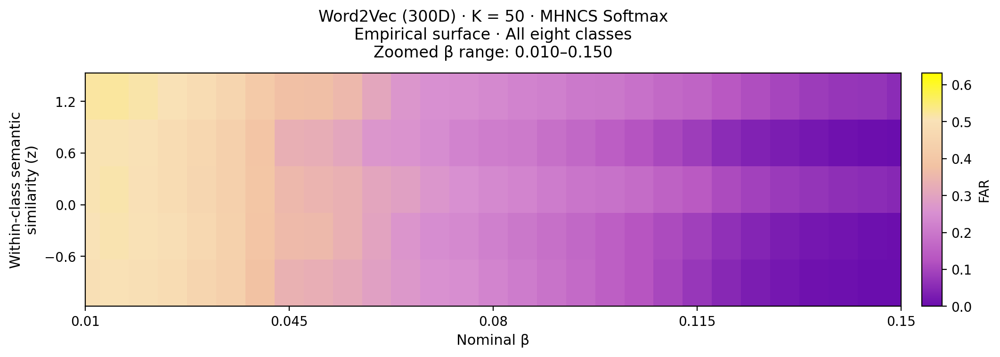

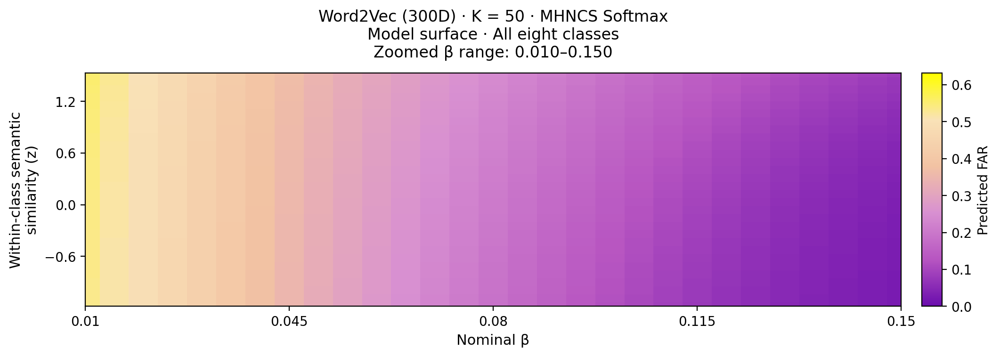

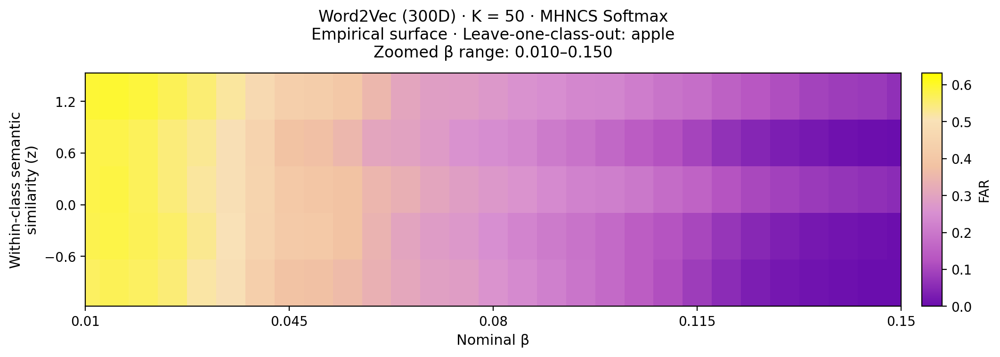

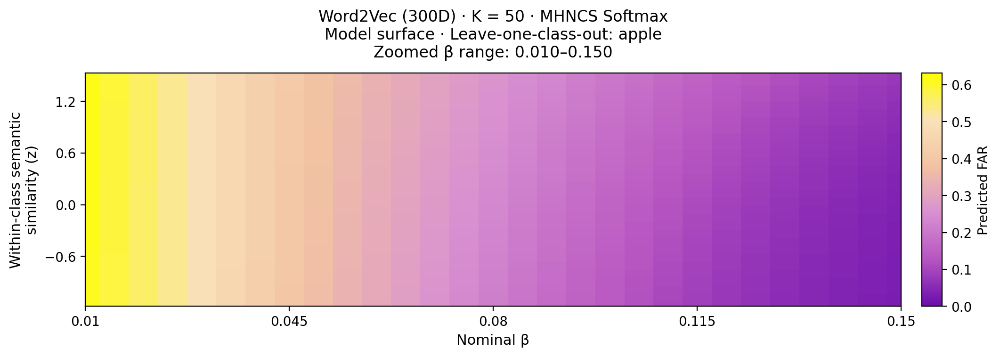

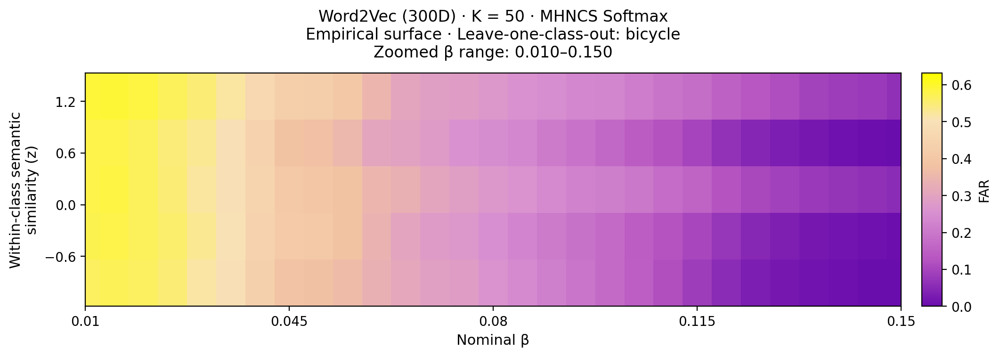

...

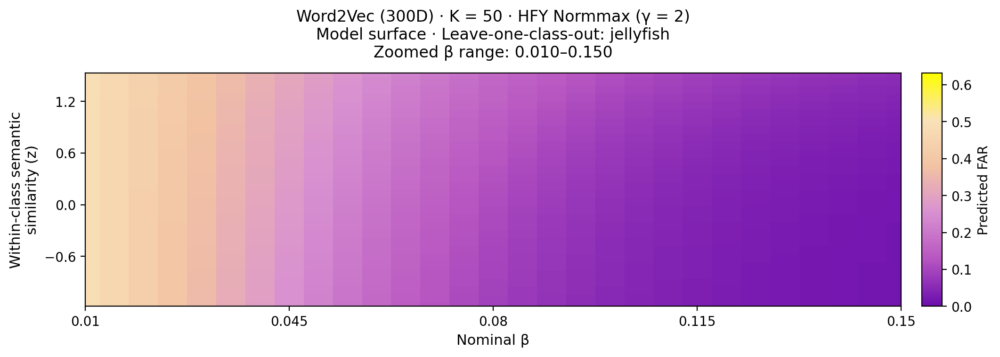

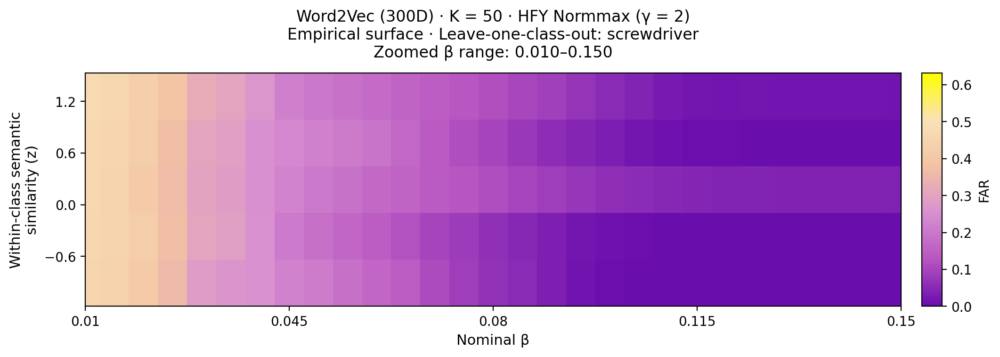

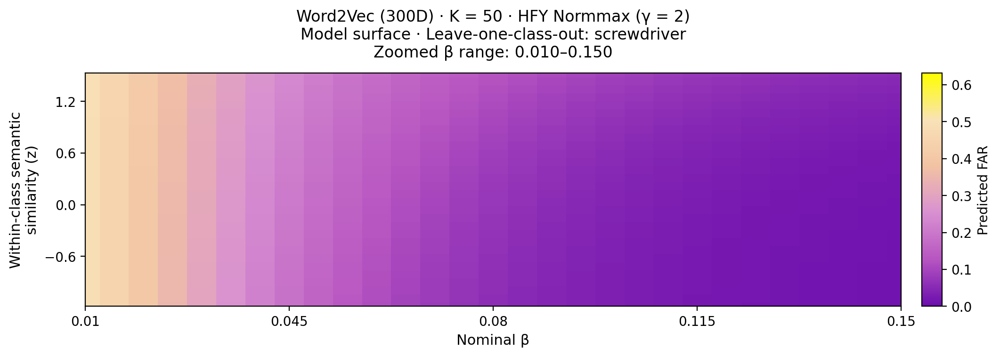

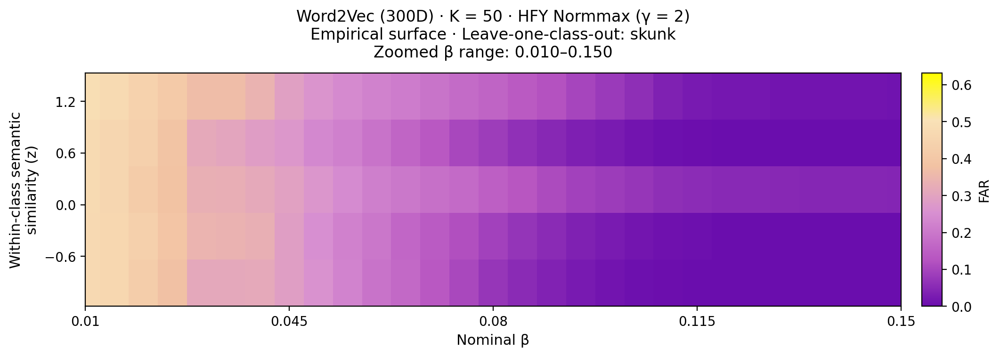

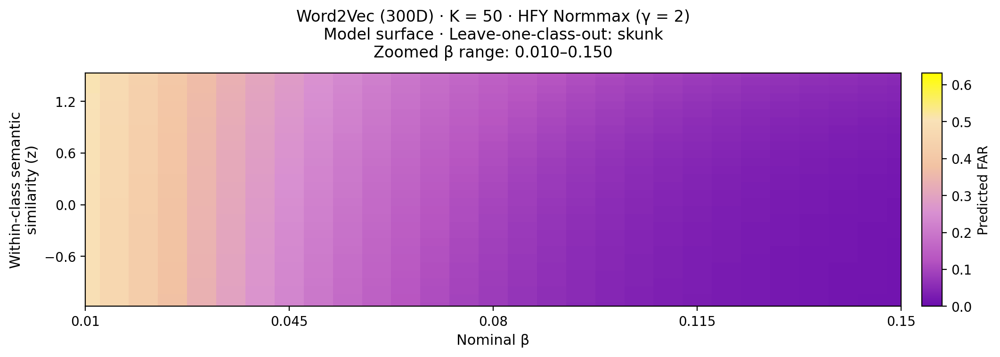

Word2Vec (300D) K50: 108 figures saved to \\?\C:\Users\jisaa\Documents\ProyectoTesis\EstudioEstatico\ExperimentoEstatico\SalidasRevision\Figuras\w2v_k50


In [17]:
if VERIFICAR_MODELO_K50:
    if "w2v" in RESULTS:
        figs.plot_results(SENSIBILIDAD_K50["w2v"], FIGURES, heatmaps=True, fit_quality=False, oof=False)


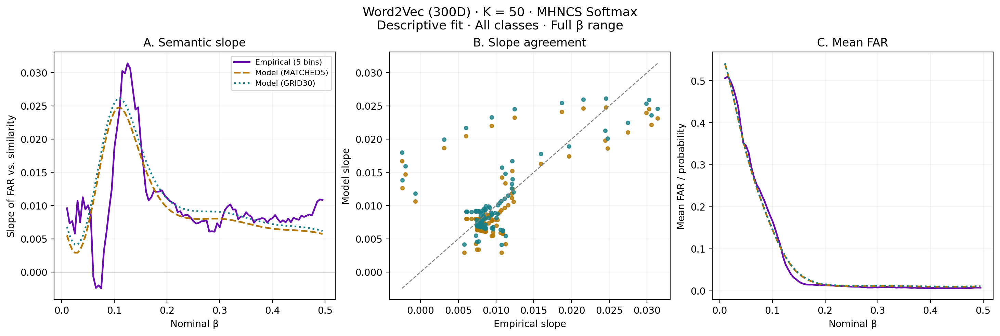

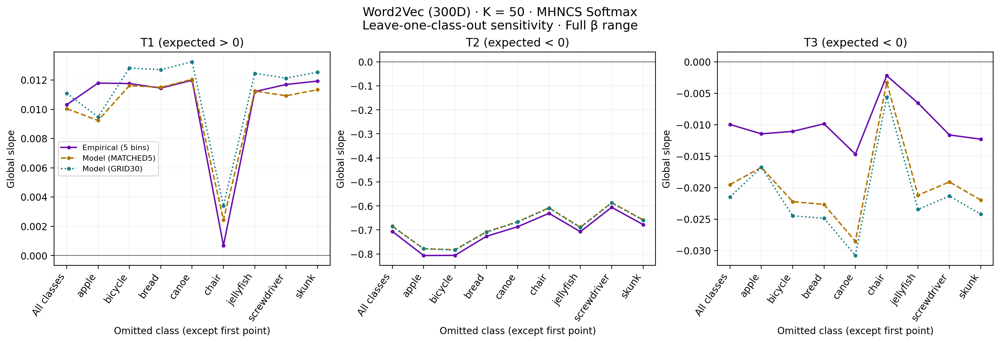

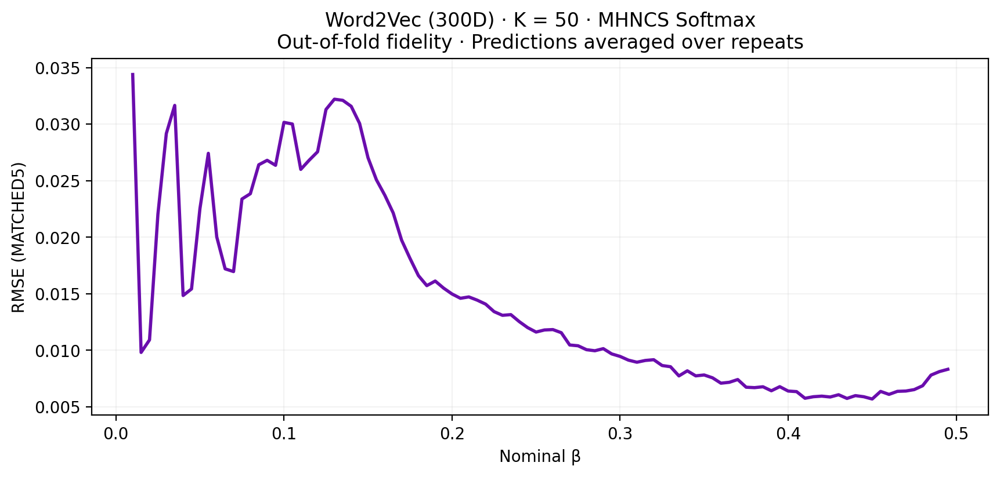

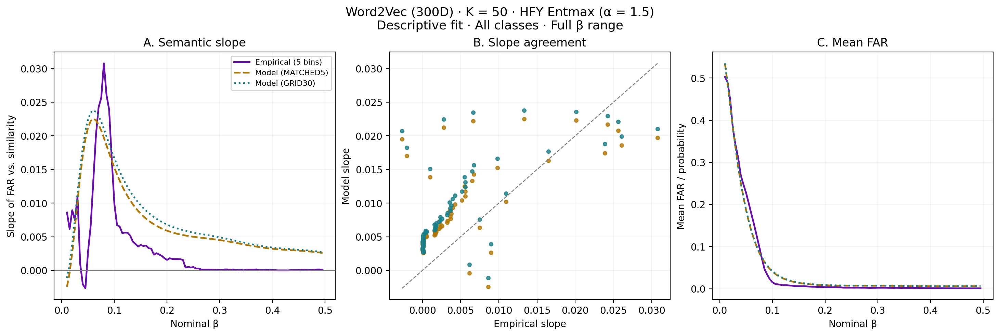

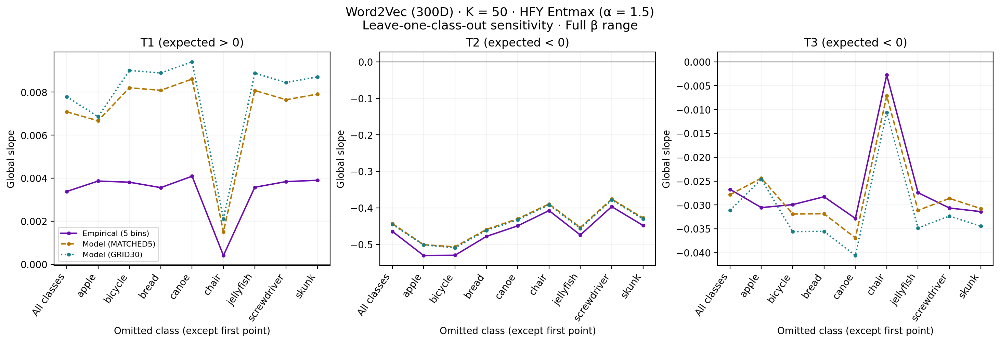

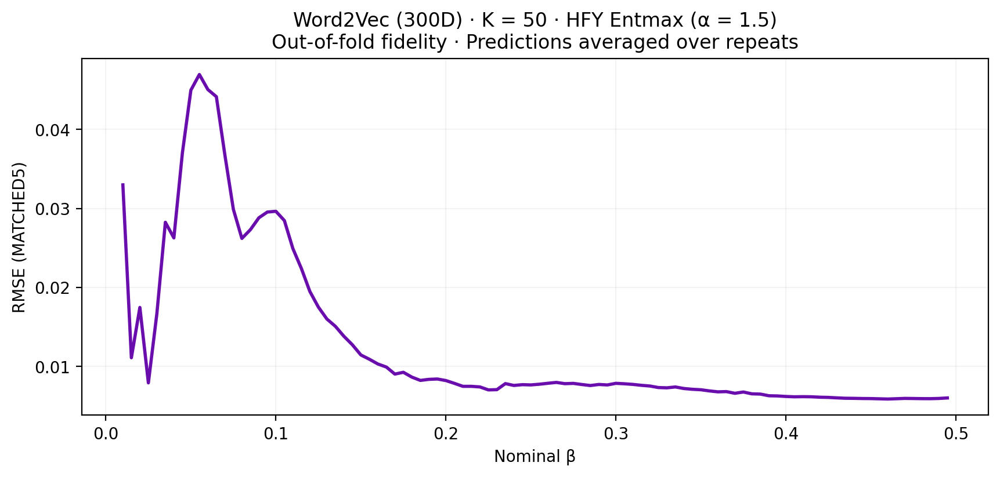

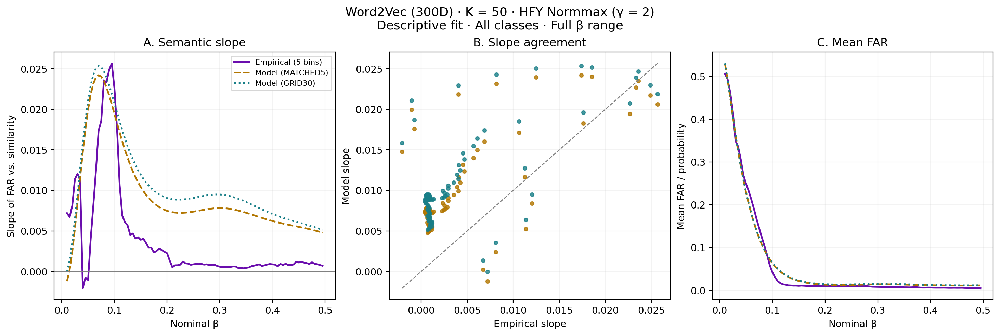

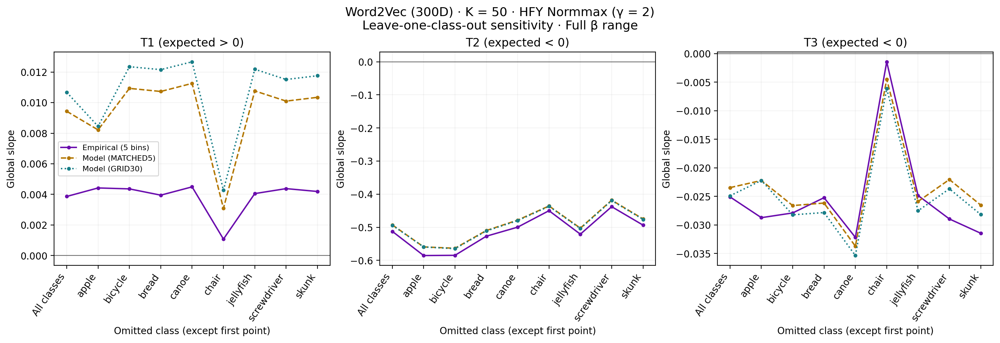

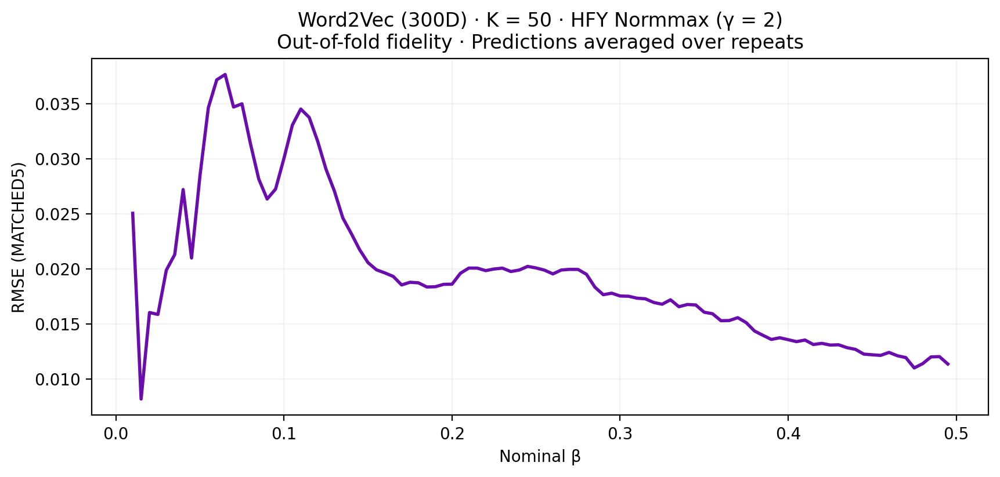

Word2Vec (300D) K50: 9 figures saved to \\?\C:\Users\jisaa\Documents\ProyectoTesis\EstudioEstatico\ExperimentoEstatico\SalidasRevision\Figuras\w2v_k50

W2V300 · OOF_fidelity


,network,region,RMSE,MAE,bias,max_abs_error,role
0,mhncs_softmax,ALL,0.016861,0.012772,0.000509,0.054120,OOF_REPEAT_AVERAGED_5
1,mhncs_softmax,BETA_LE_0.10,0.023589,0.020310,-0.012364,0.048937,OOF_REPEAT_AVERAGED_5
2,mhncs_softmax,BETA_GT_0.10,0.014794,0.010960,0.003604,0.054120,OOF_REPEAT_AVERAGED_5
3,hfy_entmax_a15,ALL,0.016430,0.011419,0.002738,0.073056,OOF_REPEAT_AVERAGED_5
4,hfy_entmax_a15,BETA_LE_0.10,0.031772,0.026217,-0.009833,0.073056,OOF_REPEAT_AVERAGED_5
5,hfy_entmax_a15,BETA_GT_0.10,0.009596,0.007860,0.005761,0.040746,OOF_REPEAT_AVERAGED_5
6,hfy_normmax_g2,ALL,0.020647,0.017548,0.003130,0.064921,OOF_REPEAT_AVERAGED_5
7,hfy_normmax_g2,BETA_LE_0.10,0.027709,0.022850,-0.010614,0.064921,OOF_REPEAT_AVERAGED_5
8,hfy_normmax_g2,BETA_GT_0.10,0.018551,0.016273,0.006436,0.049739,OOF_REPEAT_AVERAGED_5



W2V300 · sensitivity


,network,fit,omitted_class,omitted_label,empirical_E,M_matched5,M_grid30,stable,RMSE_matched5,MAE_matched5,...,max_abs_error,empirical_T1,empirical_T2,empirical_T3,matched5_T1,matched5_T2,matched5_T3,grid30_T1,grid30_T2,grid30_T3
0,mhncs_softmax,FULL,NaN,NaN,True,True,True,True,0.016163,0.012221,...,0.052395,0.010311,-0.705800,-0.009960,0.010041,-0.684327,-0.019496,0.011096,-0.685496,-0.021470
1,mhncs_softmax,LOCO_0_apple,0.0,apple,True,True,True,True,0.018469,0.013944,...,0.057219,0.011791,-0.806486,-0.011441,0.009233,-0.778344,-0.016770,0.009477,-0.778156,-0.016758
2,mhncs_softmax,LOCO_1_bicycle,1.0,bicycle,True,True,True,True,0.018302,0.013819,...,0.059856,0.011757,-0.805686,-0.011051,0.011615,-0.782202,-0.022222,0.012821,-0.783531,-0.024471
3,mhncs_softmax,LOCO_2_bread,2.0,bread,True,True,True,True,0.019348,0.014333,...,0.070824,0.011448,-0.726552,-0.009846,0.011500,-0.708064,-0.022666,0.012706,-0.709432,-0.024866
4,mhncs_softmax,LOCO_3_canoe,3.0,canoe,True,True,True,True,0.016262,0.011382,...,0.058400,0.011983,-0.686552,-0.014671,0.012041,-0.665640,-0.028514,0.013245,-0.667203,-0.030776
5,mhncs_softmax,LOCO_4_chair,4.0,chair,True,True,True,True,0.016836,0.013099,...,0.059927,0.000683,-0.630717,-0.002204,0.002437,-0.607623,-0.003275,0.003401,-0.608978,-0.005620
6,mhncs_softmax,LOCO_5_jellyfish,5.0,jellyfish,True,True,True,True,0.017157,0.012649,...,0.058074,0.011207,-0.707173,-0.006556,0.011245,-0.688626,-0.021181,0.012453,-0.689996,-0.023444
7,mhncs_softmax,LOCO_6_screwdriver,6.0,screwdriver,True,True,True,True,0.014710,0.011309,...,0.046680,0.011695,-0.605643,-0.011615,0.010923,-0.586285,-0.019084,0.012126,-0.587509,-0.021330
8,mhncs_softmax,LOCO_7_skunk,7.0,skunk,True,True,True,True,0.016747,0.012734,...,0.054226,0.011925,-0.677587,-0.012296,0.011335,-0.657738,-0.021951,0.012539,-0.659061,-0.024194
9,hfy_entmax_a15,FULL,NaN,NaN,True,True,True,True,0.016202,0.011351,...,0.070484,0.003382,-0.464319,-0.026728,0.007085,-0.442956,-0.027860,0.007789,-0.445241,-0.031101



W2V300 · trend_concentration


,trend,unit,total,signed_total,sum_absolute_contributions,max_absolute_contribution_share,effective_absolute_contributors,net_to_absolute_ratio,expected_direction_mass,opposing_direction_mass,top_unit,top_signed_contribution,reconstruction_absolute_error,role,network
0,T1,WORD,0.010311,0.010311,0.086242,0.099972,38.197361,0.119559,0.048276,0.037965,seat,0.008622,1.734723e-18,DESCRIPTIVE_ONLY_NOT_SELECTION_OR_LOCO,mhncs_softmax
1,T1,CLASS,0.010311,0.010311,0.010917,0.889716,1.258022,0.944489,0.010614,0.000303,chair,0.009713,1.734723e-18,DESCRIPTIVE_ONLY_NOT_SELECTION_OR_LOCO,mhncs_softmax
2,T2,WORD,-0.705800,0.705800,0.705800,0.031586,116.440392,1.000000,0.705800,0.000000,sawzall,0.022294,1.110223e-16,DESCRIPTIVE_ONLY_NOT_SELECTION_OR_LOCO,mhncs_softmax
3,T2,CLASS,-0.705800,0.705800,0.705800,0.249167,5.480822,1.000000,0.705800,0.000000,screwdriver,0.175862,1.110223e-16,DESCRIPTIVE_ONLY_NOT_SELECTION_OR_LOCO,mhncs_softmax
4,T3,WORD,-0.009960,0.009960,0.776805,0.053009,64.916527,0.012822,0.393383,0.383423,sawzall,0.041178,5.204170e-18,DESCRIPTIVE_ONLY_NOT_SELECTION_OR_LOCO,mhncs_softmax
5,T3,CLASS,-0.009960,0.009960,0.017820,0.450704,3.407362,0.558932,0.013890,0.003930,chair,0.008031,5.204170e-18,DESCRIPTIVE_ONLY_NOT_SELECTION_OR_LOCO,mhncs_softmax
6,T1,WORD,0.003382,0.003382,0.047840,0.079959,48.364190,0.070702,0.025611,0.022229,seat,0.003825,2.602085e-18,DESCRIPTIVE_ONLY_NOT_SELECTION_OR_LOCO,hfy_entmax_a15
7,T1,CLASS,0.003382,0.003382,0.003843,0.787927,1.580310,0.880112,0.003613,0.000230,chair,0.003028,1.734723e-18,DESCRIPTIVE_ONLY_NOT_SELECTION_OR_LOCO,hfy_entmax_a15
8,T2,WORD,-0.464319,0.464319,0.464319,0.041265,98.864970,1.000000,0.464319,0.000000,seat,0.019160,5.551115e-17,DESCRIPTIVE_ONLY_NOT_SELECTION_OR_LOCO,hfy_entmax_a15
9,T2,CLASS,-0.464319,0.464319,0.464319,0.252540,5.365965,1.000000,0.464319,0.000000,screwdriver,0.117259,1.110223e-16,DESCRIPTIVE_ONLY_NOT_SELECTION_OR_LOCO,hfy_entmax_a15



W2V300 · reuse


,stage,dataset,K,network,path,identity,sha256,action,candidate,fits
0,counts,w2v,50.0,mhncs_softmax,\\?\C:\Users\jisaa\Documents\ProyectoTesis\Est...,c78be440f45ae65878aa9b143f9506f8bb4ef3285f3125...,91a06fa395105d9be0efd3699628a1b39ddafaa7527edf...,VERIFIED_REUSE,NaN,NaN
1,counts,w2v,50.0,hfy_entmax_a15,\\?\C:\Users\jisaa\Documents\ProyectoTesis\Est...,0a26cd608c5762537e5af759735129d1303030c54b0c14...,5122e6213441f114b6476a0092a63048df143b6ae8442d...,VERIFIED_REUSE,NaN,NaN
2,counts,w2v,50.0,hfy_normmax_g2,\\?\C:\Users\jisaa\Documents\ProyectoTesis\Est...,214fbb6f042ffb230fa2ef08011a38d2f1def85af67175...,79b4a90116f479b6e5d2601ad693ece4e06f047fe0d635...,VERIFIED_REUSE,NaN,NaN
3,model_selection,NaN,NaN,NaN,\\?\C:\Users\jisaa\Documents\ProyectoTesis\Est...,NaN,NaN,VERIFIED_REUSE,H_BETA_LINEAR_Z__ridge_1e-02,3825.0


In [18]:
if VERIFICAR_MODELO_K50:
    if "w2v" in RESULTS:
        figs.plot_results(SENSIBILIDAD_K50["w2v"], FIGURES, heatmaps=False, fit_quality=True, oof=True)
        exp.display_tables(SENSIBILIDAD_K50["w2v"], names=(
            "OOF_fidelity", "sensitivity", "trend_concentration", "reuse"
        ))


### Cambiar el recorte sin volver a cargar los experimentos

Después de cargar los resultados, puedes cambiar `FIGURES.beta_range` y ejecutar `regenerar_heatmaps()`.
Esto sólo vuelve a dibujar las superficies guardadas. No vuelve a seleccionar K ni a ajustar modelos.
Cada intervalo tiene su propia carpeta; las figuras completas se conservan en `appendix_full`.


In [19]:
# Descomenta estas líneas para regenerar sólo los heatmaps con otro intervalo:
# FIGURES.beta_range = (0.01, 0.12)
# regenerar_heatmaps()


## Apéndice B. Diagnósticos estructurales de GloVe

Se conservan los diagnósticos añadidos al notebook fuente. Son opcionales y necesitan GloVe cargado.
Los dos scripts externos ya se incluyen en `Referencias`; no hay que buscarlos en Downloads.
Para los contrastes de vectores, indica `GLOVE_FILE` con el TXT o PKL de la etapa 1.1.


In [20]:
# Run in the STATIC notebook after RESULTS["glove"] has been loaded.
# No classifier or statistical model is trained by this cell.
from pathlib import Path
from io import BytesIO
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from IPython.display import display, Image


def show_structure_contrast(result, network="mhncs_softmax"):
    ctx = result.context
    full = ctx["full"].copy()
    common = ctx["common"].copy()
    expected = ctx["expected"].copy()
    wb = ctx["counts"][network].copy()
    labels = list(ctx["labels"])
    classes = list(range(len(labels)))
    edges = np.asarray(ctx["edges"], float)
    betas = np.asarray(ctx["betas"], float)
    keys = np.round(betas, 12)
    if len(classes) != 8 or len(edges) != 6:
        raise ValueError("This contrast requires the audited eight-class, five-bin protocol.")
    if not ctx.get("gate", {}).get("A", ctx.get("structure89", {}).get("A", False)):
        raise ValueError("Structural validity has not been verified for this result.")
    if full.word.duplicated().any() or expected.duplicated(["split_seed", "word"]).any():
        raise ValueError("Duplicate geometry records.")
    if set(full.word) != set(expected.word):
        raise ValueError("FULL does not match the validation-word union.")

    stats = full.groupby("true_class").validation_similarity.agg(
        mean="mean", sd=lambda v: v.std(ddof=0)
    )
    if set(stats.index) != set(classes) or not stats.sd.gt(0).all():
        raise ValueError("Invalid within-class standardization.")
    z = (full.validation_similarity - full.true_class.map(stats["mean"])) / full.true_class.map(stats.sd)
    if not np.allclose(z, full.similarity_wc_z, rtol=0, atol=1e-12):
        raise ValueError("Standardized similarities do not reproduce the audited geometry.")
    ranges = full.groupby("true_class").similarity_wc_z.agg(["min", "max"])
    lower, upper = ranges["min"].max(), ranges["max"].min()
    if upper <= lower or not np.allclose(edges, np.linspace(lower, upper, 6), rtol=0, atol=1e-12):
        raise ValueError("Invalid COMMON support.")
    selected = full.loc[full.similarity_wc_z.between(lower-1e-12, upper+1e-12)].copy()
    if set(selected.word) != set(common.word):
        raise ValueError("COMMON word inventory differs.")
    selected["bin"] = np.searchsorted(edges[1:-1], selected.similarity_wc_z, side="right").clip(0, 4)
    coverage = pd.crosstab(selected.true_class, selected["bin"]).reindex(
        index=classes, columns=range(5), fill_value=0
    )
    if not coverage.ge(1).all().all():
        display(coverage.rename(index=dict(enumerate(labels))))
        raise ValueError("Structural gate FAILED: an eight-class balanced surface is not estimable.")

    wb["beta_key"] = wb.beta.round(12)
    if wb.duplicated(["word", "beta_key"]).any() or set(wb.word) != set(full.word):
        raise ValueError("Incomplete or duplicate word-level outcomes.")
    if set(wb.beta_key) != set(keys) or not wb.groupby("word").size().eq(len(keys)).all():
        raise ValueError("Incomplete beta grid.")
    exposure = expected.groupby("word").size() * 10
    if not wb.n_items.eq(wb.word.map(exposure)).all():
        raise ValueError("Outcomes do not contain all ten classifier seeds per split.")
    if not np.isfinite(wb[["n_items", "n_errors"]]).all().all() or not wb.n_errors.between(0, wb.n_items).all():
        raise ValueError("Invalid error counts.")
    lookup = full.set_index("word")
    if not wb.true_class.eq(wb.word.map(lookup.true_class)).all():
        raise ValueError("Outcome classes are not aligned with words.")
    if not np.allclose(wb.validation_similarity, wb.word.map(lookup.validation_similarity), atol=1e-12, rtol=0):
        raise ValueError("Outcome similarities are not aligned with words.")

    # Keep one coordinate system and one bin width across all three panels.
    width = (upper-lower)/5
    full["bin"] = np.floor((full.similarity_wc_z-lower)/width).astype(int)
    full.loc[full.word.isin(selected.word), "bin"] = full.loc[full.word.isin(selected.word), "word"].map(selected.set_index("word")["bin"])
    bins = np.arange(min(0, full["bin"].min()), max(4, full["bin"].max())+1)
    yedges = lower + np.r_[bins, bins[-1]+1]*width
    d = wb.merge(full[["word", "bin"]], on="word", validate="many_to_one")
    d["rate"] = d.n_errors / d.n_items
    dc = d.loc[d.word.isin(selected.word)].copy()

    def pooled(frame):
        q = frame.groupby(["bin", "beta_key"])[["n_errors", "n_items"]].sum()
        return (q.n_errors/q.n_items).unstack().reindex(index=bins, columns=keys)

    unvalidated = pooled(d)
    common_pooled = pooled(dc)
    means = dc.groupby(["true_class", "bin", "beta_key"]).rate.mean()
    cube = np.stack([
        means.loc[c].unstack().reindex(index=range(5), columns=keys).to_numpy()
        for c in classes
    ])
    if not np.isfinite(cube).all():
        raise ValueError("A class/bin/beta cell is missing; do not renormalize over fewer classes.")
    balanced = pd.DataFrame(cube.mean(axis=0), index=range(5), columns=keys).reindex(bins)
    if network in ctx.get("empirical", {}):
        if not np.allclose(balanced.loc[range(5)], ctx["empirical"][network].values, rtol=1e-10, atol=1e-12):
            raise ValueError("Balanced surface does not reproduce the stored static result.")

    out = FIGURES.output_root / "glove_structure_contrast" / network
    out.mkdir(parents=True, exist_ok=True)
    cmap = LinearSegmentedColormap.from_list("thesis", ["#6A0DAD", "#B755C1", "#D890D1", "#F2C2A3", "#F9E2B7", "#FFFF00"])
    cmap.set_bad("#DDDDDD")

    def show(fig, name):
        for ext in ("png", "pdf"):
            fig.savefig(out/(name+"."+ext), dpi=180, bbox_inches="tight", facecolor="white")
        plt.close(fig)
        display(Image(filename=str(out/(name+".png")), width=1100))

    for name, title, table in [
        ("01_full_pooled", "Full support: pooled error rate", unvalidated),
        ("02_common_pooled", "Common support: pooled error rate", common_pooled),
        ("03_common_balanced", "Common support: equal class weights", balanced),
    ]:
        table.to_csv(out/(name+".csv"), index_label="bin")
        plotted = table.copy()
        plotted.index = (yedges[:-1] + yedges[1:]) / 2
        figs.heatmap_views(plotted, FIGURES, folder=out, stem=name,
            title="GloVe · Structural support contrast", subtitle=title,
            color_limits=(0, 1), color_label="Error rate", y_edges=yedges)

    fig, ax = plt.subplots(figsize=(8.5, 4.8), constrained_layout=True)
    im = ax.imshow(coverage.values, cmap=cmap, aspect="auto", vmin=0)
    ax.set_xticks(range(5), [f"{v:.2f}" for v in (edges[:-1]+edges[1:])/2])
    ax.set_yticks(classes, labels)
    for i in classes:
        for j in range(5):
            ax.text(j, i, str(coverage.iloc[i,j]), ha="center", va="center", color="black" if coverage.iloc[i,j] > coverage.values.max()/2 else "white")
    ax.set(title="Verified class coverage in common support", xlabel="Within-class similarity (z)", ylabel="True class")
    fig.colorbar(im, ax=ax, label="Distinct validation words")
    show(fig, "04_common_coverage")
    coverage.to_csv(out/"coverage.csv")
    stats.to_csv(out/"within_class_standardizer.csv")
    summary = dict(dataset=ctx.get("dataset_label"), K=ctx.get("K"), network=network,
        full_words=len(full), common_words=len(selected), min_words_per_class_bin=int(coverage.values.min()),
        empty_class_bin_cells=int((coverage.values==0).sum()), class_weight=1/8,
        common_edges=edges.tolist(), plotted_edges=yedges.tolist(),
        scope="Post-processing contrast on the same valid static geometry and saved predictions; not a K20-versus-K40 causal contrast.",
        source_identity=str(ctx.get("id90", ctx.get("id85", "unknown"))))
    (out/"contrast.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")
    display(pd.DataFrame([summary]).drop(columns=["scope", "source_identity", "common_edges", "plotted_edges"]))
    print("Saved figures and tables:", out)



In [21]:
EJECUTAR_DIAGNOSTICOS_GLOVE = False
GLOVE_FILE = None  # Ruta al TXT/PKL de GloVe de la etapa 1.1, si se necesitan vectores.
if EJECUTAR_DIAGNOSTICOS_GLOVE:
    show_structure_contrast(RESULTS["glove"])


In [22]:
if EJECUTAR_DIAGNOSTICOS_GLOVE:
    script = REPO / "Referencias/E2_Static_Pair_Audit.py"
    exec(compile(script.read_text(encoding="utf-8"), str(script), "exec"), globals())


In [23]:
if EJECUTAR_DIAGNOSTICOS_GLOVE:
    script = REPO / "Referencias/E2_Structural_Closeout.py"
    exec(compile(script.read_text(encoding="utf-8"), str(script), "exec"), globals())


In [34]:
# CELDA 1 — Funciones comunes para las figuras compuestas.
# Copiar esta celda al notebook correspondiente; solo dibuja superficies ya guardadas.
from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.ticker import FuncFormatter, MaxNLocator
from IPython.display import display, Image

_PALETA_PANELES = LinearSegmentedColormap.from_list(
    "thesis_purple_yellow_panels",
    ["#6A0DAD", "#B755C1", "#D890D1", "#F2C2A3", "#F9E2B7", "#FFFF00"],
)
_PALETA_PANELES.set_bad("#DDDDDD")
_REDES_PANELES = ("mhncs_softmax", "hfy_entmax_a15", "hfy_normmax_g2")
_TITULOS_REDES_PANELES = ("Softmax", "Entmax (α = 1.5)", "Normmax (γ = 2)")


def _preparar_superficie_panel(s):
    s = s.copy(deep=True)
    s.index = s.index.astype(float)
    s.columns = s.columns.astype(float)
    s = s.sort_index().sort_index(axis=1)
    if min(s.shape) < 2 or s.index.has_duplicates or s.columns.has_duplicates:
        raise ValueError("La superficie debe tener al menos dos coordenadas distintas por eje.")
    if not np.isfinite(s.index).all() or not np.isfinite(s.columns).all():
        raise ValueError("Coordenadas no finitas.")
    if not np.isfinite(s.to_numpy()).all():
        raise ValueError("La superficie FULL contiene valores no finitos.")
    return s


def _bordes_panel(x):
    x = np.asarray(x, float)
    return np.r_[x[0] - (x[1] - x[0])/2, (x[:-1] + x[1:])/2,
                 x[-1] + (x[-1] - x[-2])/2]


def _escala_paneles(superficies, limites=None):
    minimo = min(float(s.to_numpy().min()) for s in superficies)
    maximo = max(float(s.to_numpy().max()) for s in superficies)
    if limites is None:
        return (minimo, maximo) if minimo < maximo else (0.0, 1.0)
    lo, hi = map(float, limites)
    if not np.isfinite([lo, hi]).all() or not 0 <= lo < hi <= 1:
        raise ValueError("Los límites de color deben cumplir 0 <= mínimo < máximo <= 1.")
    return lo, hi


def guardar_panel_compuesto(filas, titulo, destino, nombre, beta_range=(0.01, 0.15),
                            color_limits=None, panel_inches=2.25, dpi=200,
                            guardar_completa=True, mostrar=True, surface_kind="model", y_edges=None):
    """filas: lista de filas; cada fila contiene tres pares (título, DataFrame).

    El recorte solo modifica xlim. No se interpola, suaviza ni reajusta el modelo.
    La escala de color se calcula en el dominio COMPLETO y se mantiene en ambas vistas.
    """
    if len(filas) not in (1, 3) or any(len(f) != 3 for f in filas):
        raise ValueError("Usa una fila de tres paneles o tres filas de tres paneles.")
    if panel_inches < 1.8 or dpi < 72:
        raise ValueError("Usa panel_inches >= 1.8 y dpi >= 72 para conservar legibilidad.")
    filas = [[(t, _preparar_superficie_panel(s)) for t, s in fila] for fila in filas]
    superficies = [s for fila in filas for _, s in fila]
    referencia = superficies[0]
    for s in superficies[1:]:
        np.testing.assert_allclose(s.index, referencia.index, rtol=0, atol=1e-12)
        np.testing.assert_allclose(s.columns, referencia.columns, rtol=0, atol=1e-12)
    beta = referencia.columns.to_numpy(float)
    z = referencia.index.to_numpy(float)
    if surface_kind not in ("model", "empirical"):
        raise ValueError("surface_kind debe ser model o empirical.")
    if surface_kind == "empirical":
        if y_edges is None:
            raise ValueError("La superficie empírica necesita los bordes originales de sus cinco intervalos.")
        bordes_y = np.asarray(y_edges, float)
        if (len(z) != 5 or bordes_y.shape != (6,) or not np.isfinite(bordes_y).all()
                or not np.all(np.diff(bordes_y) > 0)
                or not np.all((z > bordes_y[:-1]) & (z < bordes_y[1:]))):
            raise ValueError("Bordes empíricos incompatibles con los cinco intervalos guardados.")
        limites_y = (float(bordes_y[0]), float(bordes_y[-1]))
        descripcion_superficie = "Empirical surface"
        etiqueta_color = "Empirical error rate"
    else:
        if len(z) != 30:
            raise ValueError("La superficie del modelo debe ser GRID30.")
        bordes_y = _bordes_panel(z)
        limites_y = (float(z.min()), float(z.max()))
        descripcion_superficie = "Primary fitted surface"
        etiqueta_color = "Predicted error probability"
    completo = (float(beta.min()), float(beta.max()))
    seleccion = completo if beta_range is None else tuple(map(float, beta_range))
    if (len(seleccion) != 2 or not np.isfinite(seleccion).all()
            or seleccion[0] >= seleccion[1]
            or seleccion[0] < completo[0] - 1e-12 or seleccion[1] > completo[1] + 1e-12):
        raise ValueError(f"El intervalo de beta debe quedar dentro de {completo}.")
    seleccion = (max(seleccion[0], completo[0]), min(seleccion[1], completo[1]))
    limites = _escala_paneles(superficies, color_limits)
    norm = Normalize(*limites)
    valores = np.concatenate([s.to_numpy().ravel() for s in superficies])
    debajo, encima = valores.min() < limites[0], valores.max() > limites[1]
    extension = "both" if debajo and encima else "min" if debajo else "max" if encima else "neither"
    vistas = [("selected", seleccion)] if beta_range is not None else [("full", completo)]
    if guardar_completa and beta_range is not None:
        vistas.append(("full", completo))
    destino = Path(destino)
    destino.mkdir(parents=True, exist_ok=True)
    registros = []
    for vista, rango in vistas:
        nfilas = len(filas)
        # Medidas físicas en pulgadas: cada área de datos mide panel_inches × panel_inches.
        izquierda, abajo, arriba = 0.70, 0.65, 1.00
        espacio_x, espacio_y, barra_ancho = 0.38, 0.55, 0.13
        ancho_datos = 3*panel_inches + 2*espacio_x
        alto_datos = nfilas*panel_inches + (nfilas-1)*espacio_y
        ancho = izquierda + ancho_datos + 0.20 + barra_ancho + 0.72
        alto = abajo + alto_datos + arriba
        with plt.rc_context({"font.size": 9, "pdf.fonttype": 42, "font.family": "DejaVu Sans"}):
            fig = plt.figure(figsize=(ancho, alto))
            try:
                ejes = []
                for i, fila in enumerate(filas):
                    for j, (subtitulo, s) in enumerate(fila):
                        x0 = izquierda + j*(panel_inches + espacio_x)
                        y0 = abajo + (nfilas-1-i)*(panel_inches + espacio_y)
                        ax = fig.add_axes([x0/ancho, y0/alto, panel_inches/ancho, panel_inches/alto])
                        im = ax.pcolormesh(_bordes_panel(beta), bordes_y, s.to_numpy(),
                                          cmap=_PALETA_PANELES, norm=norm, shading="flat", rasterized=True)
                        ax.set_xlim(*rango)
                        ax.set_ylim(*limites_y)
                        ax.set_box_aspect(1)
                        ax.set_title(subtitulo, fontsize=10, pad=9)
                        ax.set_xticks(np.linspace(*rango, 3))
                        ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.3f}".rstrip("0").rstrip(".")))
                        ax.yaxis.set_major_locator(MaxNLocator(5))
                        ax.tick_params(labelsize=8, labelleft=(j == 0), labelbottom=(i == nfilas-1))
                        ejes.append(ax)
                cax = fig.add_axes([(izquierda+ancho_datos+0.20)/ancho, abajo/alto,
                                    barra_ancho/ancho, alto_datos/alto])
                cb = fig.colorbar(im, cax=cax, extend=extension)
                cb.set_label(etiqueta_color, fontsize=10, labelpad=10)
                cb.locator = MaxNLocator(5)
                cb.update_ticks()
                cb.ax.tick_params(labelsize=8)
                descripcion = "Full β range" if vista == "full" else "Zoomed β range"
                fig.text((izquierda+ancho_datos/2)/ancho, 1-0.12/alto,
                         f"{titulo}\n{descripcion_superficie} · All eight classes\n"
                         f"{descripcion}: {rango[0]:.3f}–{rango[1]:.3f}",
                         ha="center", va="top", fontsize=12)
                fig.text((izquierda+ancho_datos/2)/ancho, 0.12/alto,
                         "Nominal β", ha="center", fontsize=10)
                fig.text(0.10/ancho, (abajo+alto_datos/2)/alto,
                         "Within-class semantic similarity (z)", rotation=90,
                         ha="center", va="center", fontsize=10)
                fig.canvas.draw()
                desviacion = max(abs(ax.get_window_extent().width/ax.get_window_extent().height-1) for ax in ejes)
                if desviacion > 1e-8:
                    raise RuntimeError("Los paneles no son cuadrados.")
                tramo = "_".join(f"{v:.6g}".replace(".", "p") for v in rango)
                stem = f"{nombre}_{vista}_beta_{tramo}"
                for extension_archivo in ("png", "pdf"):
                    fig.savefig(destino/f"{stem}.{extension_archivo}", dpi=dpi,
                                bbox_inches="tight", facecolor="white")
                registro = {"name": nombre, "view": vista, "beta_range": rango,
                            "full_beta_range": completo, "color_limits": limites,
                            "n_panels": len(superficies), "max_square_deviation": desviacion,
                            "surface_kind": surface_kind, "n_similarity_rows": len(z),
                            "similarity_limits": limites_y, "similarity_edges": bordes_y.tolist(),
                            "source_surface_sha256": [hashlib.sha256(s.to_csv().encode()).hexdigest() for s in superficies],
                            "interpolation": False, "smoothing": False, "model_refitted": False}
                (destino/f"{stem}.json").write_text(json.dumps(registro, indent=2), encoding="utf-8")
                registros.append(registro)
                if mostrar and vista == vistas[0][0]:
                    display(Image(filename=str(destino/f"{stem}.png"), width=1050))
            finally:
                plt.close(fig)
    return registros


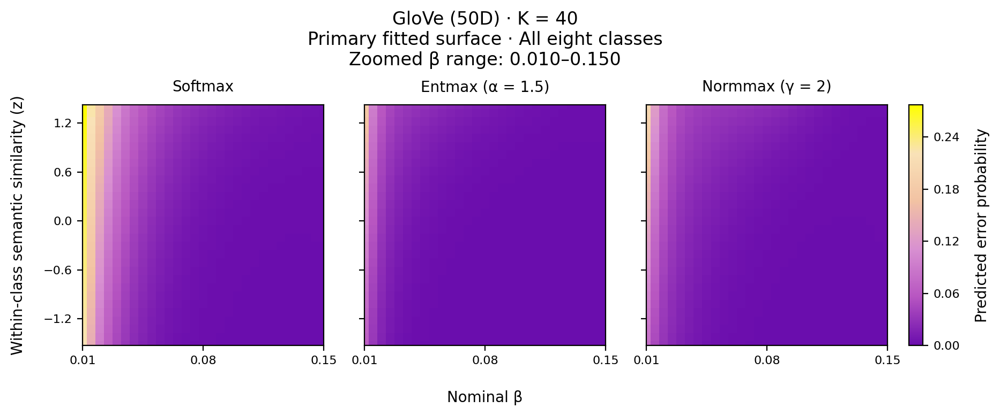

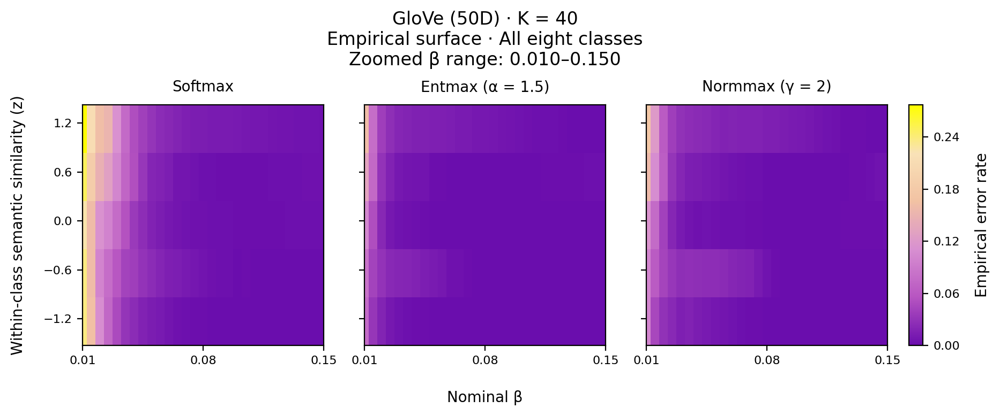

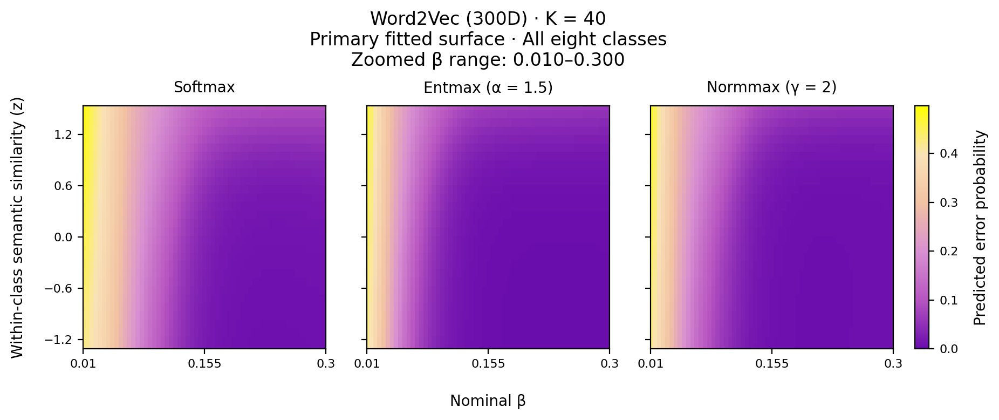

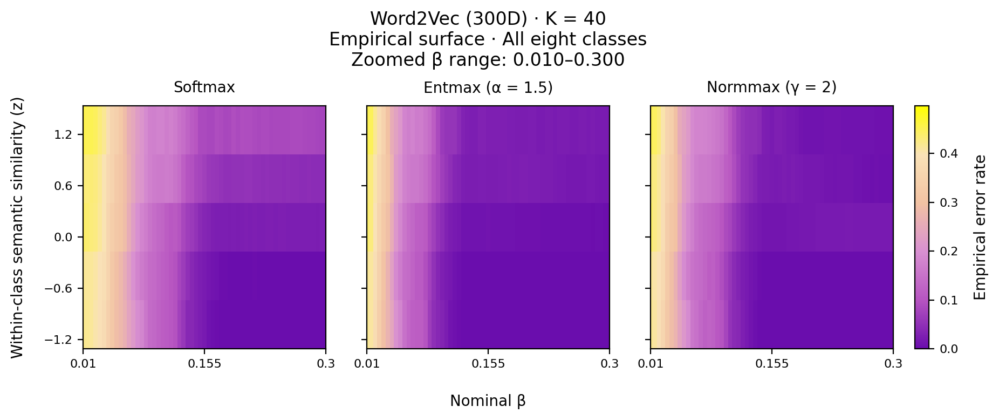

Figuras compuestas: \\?\C:\Users\jisaa\Documents\ProyectoTesis\EstudioEstatico\ExperimentoEstatico\SalidasRevision\Figuras\PanelesCompuestos


In [35]:
# CELDA 2 — Figuras estáticas FULL: modelo y empíricas, tres redes por imagen.
# Ejecutar después de cargar RESULTS["glove"], RESULTS["w2v"] y definir FIGURES.

# EDITABLE: un intervalo por figura; None muestra todo el dominio.
BETAS_ESTATICOS = {"glove": (0.01, 0.15), "w2v": (0.01, 0.3)}  # MODELO
BETAS_EMPIRICOS_ESTATICOS = {"glove": (0.01, 0.15), "w2v": (0.01, 0.3)}
TIPOS_ESTATICOS = ("model", "empirical")  # Para exportar solo empíricas: ("empirical",)

# Una escala por dataset, común a sus tres redes, modelo y superficie empírica.
# None = automática sobre ambas superficies FULL completas, sin depender del recorte.
COLORES_ESTATICOS = {"glove": None, "w2v": None}
TAMANO_PANEL_ESTATICO = 2.25  # pulgadas por lado de CADA heatmap
DPI_ESTATICO = 200
GUARDAR_COMPLETAS_ESTATICO = True

if not isinstance(globals().get("RESULTS"), dict):
    raise RuntimeError("Ejecuta primero la carga de resultados de EstudioEstatico.ipynb.")
faltantes = set(BETAS_ESTATICOS) - set(RESULTS)
if faltantes:
    raise RuntimeError(f"Falta cargar RESULTS para: {sorted(faltantes)}")
if not TIPOS_ESTATICOS or not set(TIPOS_ESTATICOS) <= {"model", "empirical"}:
    raise ValueError("Selecciona model, empirical o ambos.")
import exp2_pipeline_integrated as _exp_paneles

SALIDA_PANELES_ESTATICOS = Path(FIGURES.output_root) / "PanelesCompuestos"
NOMBRES_ESTATICOS = {"glove": "GloVe (50D)", "w2v": "Word2Vec (300D)"}
REGISTRO_PANELES_ESTATICOS = []
for dataset in BETAS_ESTATICOS:
    resultado = RESULTS[dataset]
    contexto = resultado.context
    if int(contexto["K"]) != 40:
        raise ValueError(f"Se esperaba el estudio principal K40 para {dataset}.")
    superficies = {
        "model": [_exp_paneles.verified_model_surface89(contexto, red, omitted=None, resolution=30)
                  for red in _REDES_PANELES],
        "empirical": [contexto["empirical"][red] for red in _REDES_PANELES],
    }
    escala = _escala_paneles(
        [_preparar_superficie_panel(s) for grupo in superficies.values() for s in grupo],
        COLORES_ESTATICOS[dataset],
    )
    for tipo in TIPOS_ESTATICOS:
        intervalo = (BETAS_ESTATICOS if tipo == "model" else BETAS_EMPIRICOS_ESTATICOS)[dataset]
        fila = list(zip(_TITULOS_REDES_PANELES, superficies[tipo]))
        REGISTRO_PANELES_ESTATICOS += guardar_panel_compuesto(
            [fila], titulo=f"{NOMBRES_ESTATICOS[dataset]} · K = {contexto['K']}",
            destino=SALIDA_PANELES_ESTATICOS, nombre=f"{dataset}_k40_{tipo}_FULL",
            beta_range=intervalo, color_limits=escala,
            panel_inches=TAMANO_PANEL_ESTATICO, dpi=DPI_ESTATICO,
            guardar_completa=GUARDAR_COMPLETAS_ESTATICO,
            surface_kind=tipo, y_edges=contexto["edges"] if tipo == "empirical" else None,
        )
print("Figuras compuestas:", SALIDA_PANELES_ESTATICOS)


In [36]:
# CELDA 1 — Funciones para comparaciones FULL frente a una omisión LOCO.
# Copiar esta celda al notebook correspondiente; solo dibuja superficies ya guardadas.
from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.ticker import FuncFormatter, MaxNLocator
from IPython.display import display, Image

_PALETA_LOCO = LinearSegmentedColormap.from_list(
    "thesis_purple_yellow_locos",
    ["#6A0DAD", "#B755C1", "#D890D1", "#F2C2A3", "#F9E2B7", "#FFFF00"],
)
_PALETA_LOCO.set_bad("#DDDDDD")
_REDES_LOCO = ("mhncs_softmax", "hfy_entmax_a15", "hfy_normmax_g2")
_TITULOS_REDES_LOCO = ("Softmax", "Entmax (α = 1.5)", "Normmax (γ = 2)")


def _preparar_superficie_loco(s):
    s = s.copy(deep=True)
    s.index = s.index.astype(float)
    s.columns = s.columns.astype(float)
    s = s.sort_index().sort_index(axis=1)
    if min(s.shape) < 2 or s.index.has_duplicates or s.columns.has_duplicates:
        raise ValueError("La superficie debe tener al menos dos coordenadas distintas por eje.")
    if not np.isfinite(s.index).all() or not np.isfinite(s.columns).all():
        raise ValueError("Coordenadas no finitas.")
    if not np.isfinite(s.to_numpy()).all():
        raise ValueError("La superficie FULL contiene valores no finitos.")
    return s


def _bordes_loco(x):
    x = np.asarray(x, float)
    return np.r_[x[0] - (x[1] - x[0])/2, (x[:-1] + x[1:])/2,
                 x[-1] + (x[-1] - x[-2])/2]


def _escala_loco(superficies, limites=None):
    minimo = min(float(s.to_numpy().min()) for s in superficies)
    maximo = max(float(s.to_numpy().max()) for s in superficies)
    if limites is None:
        return (minimo, maximo) if minimo < maximo else (0.0, 1.0)
    lo, hi = map(float, limites)
    if not np.isfinite([lo, hi]).all() or not 0 <= lo < hi <= 1:
        raise ValueError("Los límites de color deben cumplir 0 <= mínimo < máximo <= 1.")
    return lo, hi


def guardar_comparacion_loco(filas, titulo, destino, nombre, beta_range=None,
                            color_limits=None, panel_inches=2.25, dpi=200,
                            guardar_completa=True, mostrar=True, surface_kind="model", y_edges=None):
    """filas: lista de filas; cada fila contiene tres pares (título, DataFrame).

    El recorte solo modifica xlim. No se interpola, suaviza ni reajusta el modelo.
    La escala de color se calcula en el dominio COMPLETO y se mantiene en ambas vistas.
    """
    if len(filas) != 2 or any(len(f) != 3 for f in filas):
        raise ValueError("Usa dos filas: FULL y una omisión; tres redes por fila.")
    if panel_inches < 1.8 or dpi < 72:
        raise ValueError("Usa panel_inches >= 1.8 y dpi >= 72 para conservar legibilidad.")
    filas = [[(t, _preparar_superficie_loco(s)) for t, s in fila] for fila in filas]
    superficies = [s for fila in filas for _, s in fila]
    referencia = superficies[0]
    for s in superficies[1:]:
        np.testing.assert_allclose(s.index, referencia.index, rtol=0, atol=1e-12)
        np.testing.assert_allclose(s.columns, referencia.columns, rtol=0, atol=1e-12)
    beta = referencia.columns.to_numpy(float)
    z = referencia.index.to_numpy(float)
    if surface_kind not in ("model", "empirical"):
        raise ValueError("surface_kind debe ser model o empirical.")
    if surface_kind == "empirical":
        if y_edges is None:
            raise ValueError("La superficie empírica necesita los bordes originales de sus cinco intervalos.")
        bordes_y = np.asarray(y_edges, float)
        if (len(z) != 5 or bordes_y.shape != (6,) or not np.isfinite(bordes_y).all()
                or not np.all(np.diff(bordes_y) > 0)
                or not np.all((z > bordes_y[:-1]) & (z < bordes_y[1:]))):
            raise ValueError("Bordes empíricos incompatibles con los cinco intervalos guardados.")
        limites_y = (float(bordes_y[0]), float(bordes_y[-1]))
        descripcion_superficie = "Empirical surface (LOCO reaggregation)"
        etiqueta_color = "Empirical error rate"
    else:
        if len(z) != 30:
            raise ValueError("La superficie del modelo debe ser GRID30.")
        bordes_y = _bordes_loco(z)
        limites_y = (float(z.min()), float(z.max()))
        descripcion_superficie = "Primary fitted surface (LOCO refit)"
        etiqueta_color = "Predicted error probability"
    completo = (float(beta.min()), float(beta.max()))
    seleccion = completo if beta_range is None else tuple(map(float, beta_range))
    if (len(seleccion) != 2 or not np.isfinite(seleccion).all()
            or seleccion[0] >= seleccion[1]
            or seleccion[0] < completo[0] - 1e-12 or seleccion[1] > completo[1] + 1e-12):
        raise ValueError(f"El intervalo de beta debe quedar dentro de {completo}.")
    seleccion = (max(seleccion[0], completo[0]), min(seleccion[1], completo[1]))
    limites = _escala_loco(superficies, color_limits)
    norm = Normalize(*limites)
    valores = np.concatenate([s.to_numpy().ravel() for s in superficies])
    debajo, encima = valores.min() < limites[0], valores.max() > limites[1]
    extension = "both" if debajo and encima else "min" if debajo else "max" if encima else "neither"
    vistas = [("selected", seleccion)] if beta_range is not None else [("full", completo)]
    if guardar_completa and beta_range is not None:
        vistas.append(("full", completo))
    destino = Path(destino)
    destino.mkdir(parents=True, exist_ok=True)
    registros = []
    for vista, rango in vistas:
        nfilas = len(filas)
        # Medidas físicas en pulgadas: cada área de datos mide panel_inches × panel_inches.
        izquierda, abajo, arriba = 0.70, 0.65, 1.15
        espacio_x, espacio_y, barra_ancho = 0.38, 0.75, 0.13
        ancho_datos = 3*panel_inches + 2*espacio_x
        alto_datos = nfilas*panel_inches + (nfilas-1)*espacio_y
        ancho = izquierda + ancho_datos + 0.20 + barra_ancho + 0.72
        alto = abajo + alto_datos + arriba
        with plt.rc_context({"font.size": 9, "pdf.fonttype": 42, "font.family": "DejaVu Sans"}):
            fig = plt.figure(figsize=(ancho, alto))
            try:
                ejes = []
                for i, fila in enumerate(filas):
                    for j, (subtitulo, s) in enumerate(fila):
                        x0 = izquierda + j*(panel_inches + espacio_x)
                        y0 = abajo + (nfilas-1-i)*(panel_inches + espacio_y)
                        ax = fig.add_axes([x0/ancho, y0/alto, panel_inches/ancho, panel_inches/alto])
                        im = ax.pcolormesh(_bordes_loco(beta), bordes_y, s.to_numpy(),
                                          cmap=_PALETA_LOCO, norm=norm, shading="flat", rasterized=True)
                        ax.set_xlim(*rango)
                        ax.set_ylim(*limites_y)
                        ax.set_box_aspect(1)
                        ax.set_title(subtitulo, fontsize=9, pad=9)
                        ax.set_xticks(np.linspace(*rango, 3))
                        ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.3f}".rstrip("0").rstrip(".")))
                        ax.yaxis.set_major_locator(MaxNLocator(5))
                        ax.tick_params(labelsize=8, labelleft=(j == 0), labelbottom=(i == nfilas-1))
                        ejes.append(ax)
                cax = fig.add_axes([(izquierda+ancho_datos+0.20)/ancho, abajo/alto,
                                    barra_ancho/ancho, alto_datos/alto])
                cb = fig.colorbar(im, cax=cax, extend=extension)
                cb.set_label(etiqueta_color, fontsize=10, labelpad=10)
                cb.locator = MaxNLocator(5)
                cb.update_ticks()
                cb.ax.tick_params(labelsize=8)
                descripcion = "Full β range" if vista == "full" else "Zoomed β range"
                fig.text((izquierda+ancho_datos/2)/ancho, 1-0.12/alto,
                         f"{titulo}\n{descripcion_superficie} · FULL vs leave-one-class-out\n"
                         f"{descripcion}: {rango[0]:.3f}–{rango[1]:.3f}",
                         ha="center", va="top", fontsize=12)
                fig.text((izquierda+ancho_datos/2)/ancho, 0.12/alto,
                         "Nominal β", ha="center", fontsize=10)
                fig.text(0.10/ancho, (abajo+alto_datos/2)/alto,
                         "Within-class semantic similarity (z)", rotation=90,
                         ha="center", va="center", fontsize=10)
                fig.canvas.draw()
                desviacion = max(abs(ax.get_window_extent().width/ax.get_window_extent().height-1) for ax in ejes)
                if desviacion > 1e-8:
                    raise RuntimeError("Los paneles no son cuadrados.")
                tramo = "_".join(f"{v:.6g}".replace(".", "p") for v in rango)
                stem = f"{nombre}_{vista}_beta_{tramo}"
                for extension_archivo in ("png", "pdf"):
                    fig.savefig(destino/f"{stem}.{extension_archivo}", dpi=dpi,
                                bbox_inches="tight", facecolor="white")
                registro = {"name": nombre, "view": vista, "beta_range": rango,
                            "full_beta_range": completo, "color_limits": limites,
                            "n_panels": len(superficies), "max_square_deviation": desviacion,
                            "surface_kind": surface_kind, "n_similarity_rows": len(z),
                            "similarity_limits": limites_y, "similarity_edges": bordes_y.tolist(),
                            "source_surface_sha256": [hashlib.sha256(s.to_csv().encode()).hexdigest() for s in superficies],
                            "interpolation": False, "smoothing": False, "model_refitted": False,
                            "panel_labels": [t for fila in filas for t, _ in fila],
                            "trends_full_beta_range": [_tendencias_loco(s) for s in superficies]}
                (destino/f"{stem}.json").write_text(json.dumps(registro, indent=2), encoding="utf-8")
                registros.append(registro)
                if mostrar and vista == vistas[0][0]:
                    display(Image(filename=str(destino/f"{stem}.png"), width=1050))
            finally:
                plt.close(fig)
    return registros


def _tendencias_loco(surface):
    """Mismas pendientes globales del proyecto, sobre todo el dominio guardado."""
    z = surface.index.to_numpy(float)
    b = surface.columns.to_numpy(float)
    y = surface.to_numpy(float)
    z = (z-z.mean()) / np.square(z-z.mean()).sum()
    b = (b-b.mean()) / np.square(b-b.mean()).sum()
    slope = z @ y
    t = dict(T1=float(slope.mean()), T2=float((y @ b).mean()), T3=float(slope @ b))
    if np.all(y == y[0:1, :]): t.update(T1=0.0, T3=0.0)
    if np.all(y == y[:, 0:1]): t.update(T2=0.0, T3=0.0)
    return t


def _filas_loco(superficies, etiqueta):
    return [[(f"{titulo}\n{caso}", s) for titulo, s in zip(_TITULOS_REDES_LOCO, grupo)]
            for caso, grupo in zip(("FULL · All eight classes", f"Without {etiqueta} · Seven classes"), superficies)]


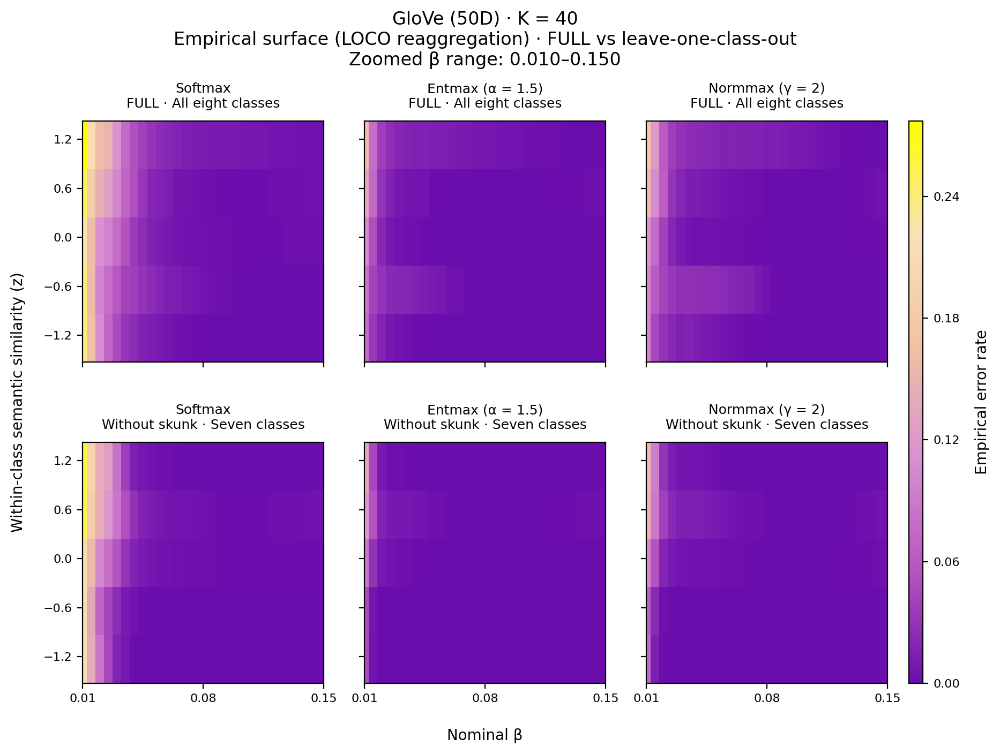

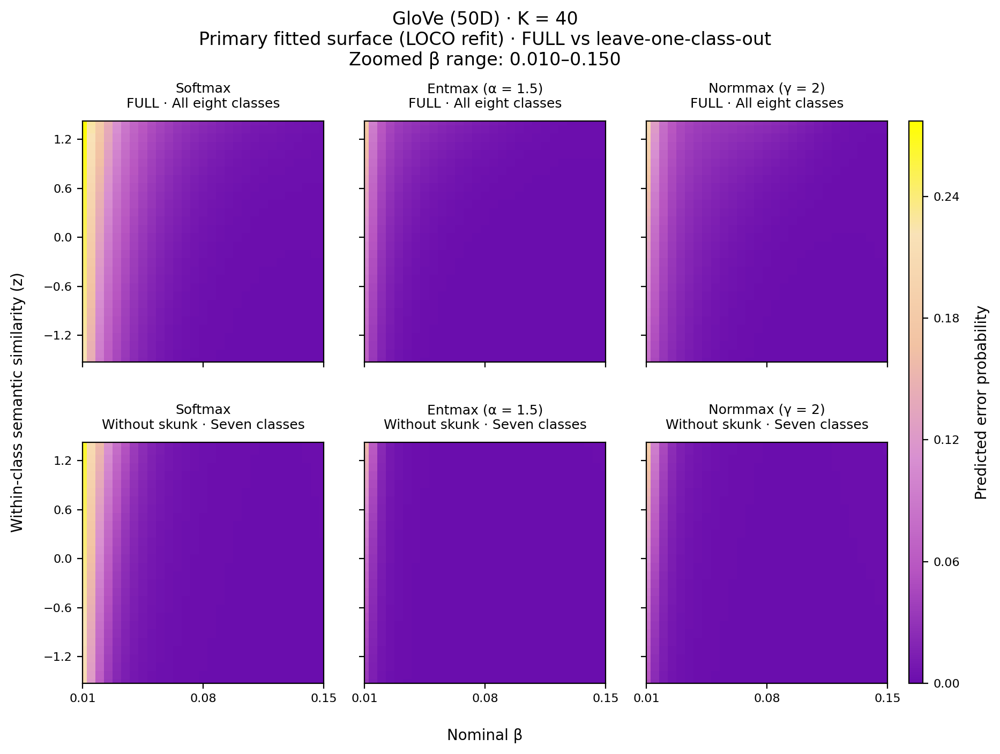

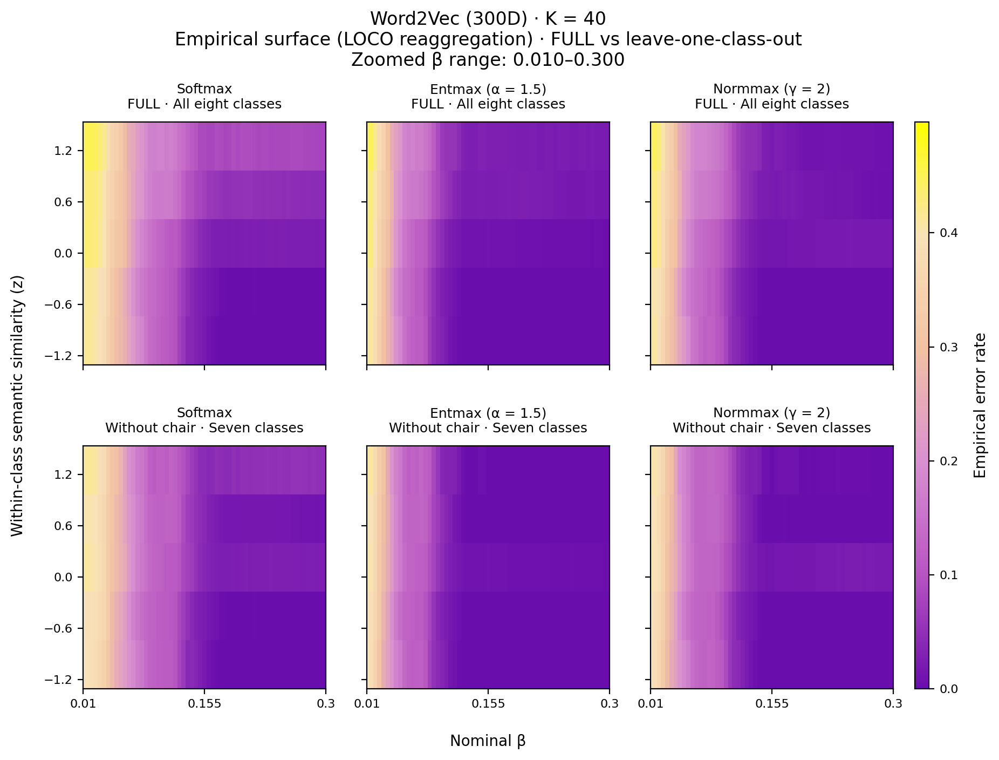

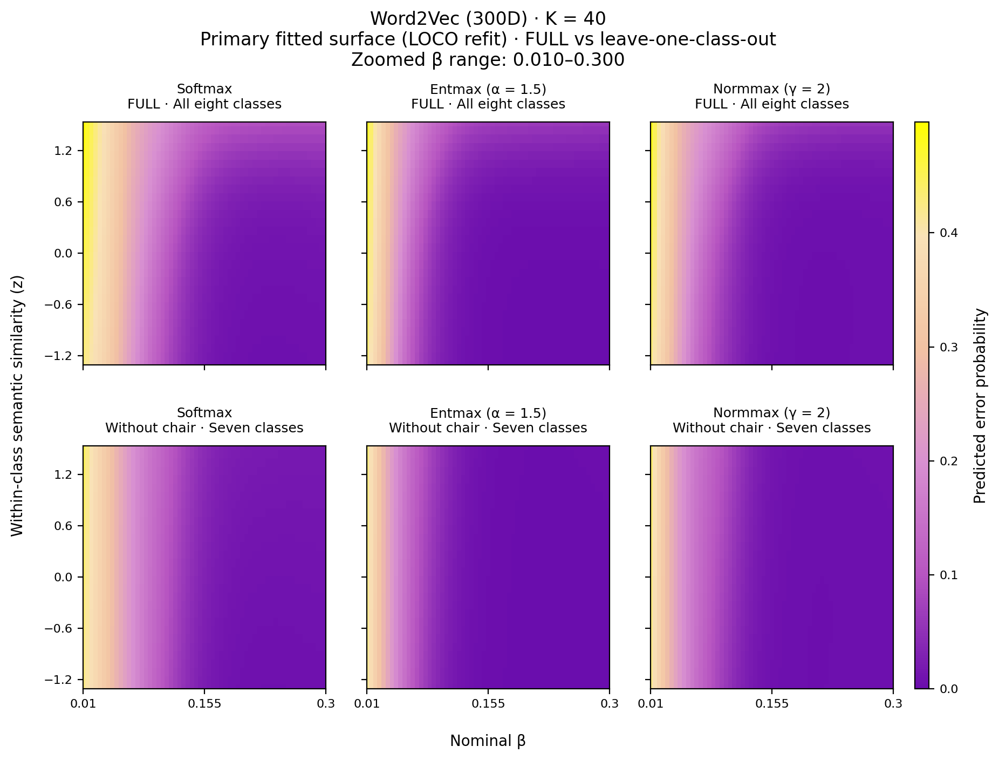

Comparaciones guardadas en: \\?\C:\Users\jisaa\Documents\ProyectoTesis\EstudioEstatico\ExperimentoEstatico\SalidasRevision\Figuras\ComparacionesLOCO


In [38]:
# CELDA 2 — Comparaciones estáticas seleccionadas. Reutiliza RESULTS y FIGURES.
# GloVe/skunk: T2 más próximo a cero en las tres redes, empírico y modelo.
# W2V/chair: T1 mínimo en las tres redes, empírico y modelo.
OMISIONES_LOCO_ESTATICAS = {"glove": "skunk", "w2v": "chair"}
BETAS_LOCO_ESTATICAS = {
    ("glove", "empirical"): (0.01, 0.15), ("glove", "model"): (0.01, 0.15),
    ("w2v", "empirical"): (0.01, 0.3), ("w2v", "model"): (0.01, 0.3),
}  # None = completo. Ejemplo editable: (0.01, 0.15).
TIPOS_LOCO_ESTATICOS = ("empirical", "model")
COLORES_LOCO_ESTATICOS = {"glove": None, "w2v": None}
LADO_LOCO_ESTATICO = 2.25
DPI_LOCO_ESTATICO = 200
GUARDAR_COMPLETAS_LOCO_ESTATICO = True

import exp2_pipeline_integrated as _exp_loco
if not isinstance(globals().get("RESULTS"), dict):
    raise RuntimeError("Primero carga los resultados de EstudioEstatico.ipynb.")
if not set(TIPOS_LOCO_ESTATICOS) <= {"model", "empirical"}:
    raise ValueError("Tipos permitidos: empirical y model.")
REGISTRO_LOCO_ESTATICO = []
for dataset, etiqueta in OMISIONES_LOCO_ESTATICAS.items():
    ctx = RESULTS[dataset].context
    if int(ctx["K"]) != 40:
        raise ValueError("Estas comparaciones corresponden al estudio principal K40.")
    omitida = list(ctx["labels"]).index(etiqueta)
    superficies = {"empirical": [], "model": []}
    for om in (None, omitida):
        modelos, empiricas = [], []
        tag = "FULL" if om is None else f"LOCO_{om}_{ctx['labels'][om]}"
        for red in _REDES_LOCO:
            # Verifica el recibo y sus archivos; no ejecuta ajustes.
            modelos.append(_exp_loco.verified_model_surface89(ctx, red, omitted=om, resolution=30))
            archivo = Path(ctx["out88"]) / "fits" / red / tag / "empirical_5bins.csv"
            if not archivo.is_file():
                raise FileNotFoundError(f"Falta la superficie empírica guardada: {archivo}")
            empiricas.append(_exp_loco.read_surface88(archivo))
        superficies["model"].append(modelos)
        superficies["empirical"].append(empiricas)
    escala = _escala_loco([s for tipo in superficies.values() for fila in tipo for s in fila],
                          COLORES_LOCO_ESTATICOS[dataset])
    for tipo in TIPOS_LOCO_ESTATICOS:
        REGISTRO_LOCO_ESTATICO += guardar_comparacion_loco(
            _filas_loco(superficies[tipo], etiqueta),
            titulo=f"{'GloVe (50D)' if dataset=='glove' else 'Word2Vec (300D)'} · K = 40",
            destino=Path(FIGURES.output_root)/"ComparacionesLOCO",
            nombre=f"{dataset}_k40_{tipo}_FULL_vs_without_{etiqueta}",
            beta_range=BETAS_LOCO_ESTATICAS[dataset, tipo], color_limits=escala,
            panel_inches=LADO_LOCO_ESTATICO, dpi=DPI_LOCO_ESTATICO,
            guardar_completa=GUARDAR_COMPLETAS_LOCO_ESTATICO,
            surface_kind=tipo, y_edges=ctx["edges"] if tipo=="empirical" else None,
        )
print("Comparaciones guardadas en:", Path(FIGURES.output_root)/"ComparacionesLOCO")


In [40]:
# CELDA 1 — Funciones comunes para las figuras compuestas.
# Copiar esta celda al notebook correspondiente; solo dibuja superficies ya guardadas.
from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.ticker import FuncFormatter, MaxNLocator
from IPython.display import display, Image

_PALETA_PANELES = LinearSegmentedColormap.from_list(
    "thesis_purple_yellow_panels",
    ["#6A0DAD", "#B755C1", "#D890D1", "#F2C2A3", "#F9E2B7", "#FFFF00"],
)
_PALETA_PANELES.set_bad("#DDDDDD")
_REDES_PANELES = ("mhncs_softmax", "hfy_entmax_a15", "hfy_normmax_g2")
_TITULOS_REDES_PANELES = ("Softmax", "Entmax (α = 1.5)", "Normmax (γ = 2)")


def _preparar_superficie_panel(s):
    s = s.copy(deep=True)
    s.index = s.index.astype(float)
    s.columns = s.columns.astype(float)
    s = s.sort_index().sort_index(axis=1)
    if min(s.shape) < 2 or s.index.has_duplicates or s.columns.has_duplicates:
        raise ValueError("La superficie debe tener al menos dos coordenadas distintas por eje.")
    if not np.isfinite(s.index).all() or not np.isfinite(s.columns).all():
        raise ValueError("Coordenadas no finitas.")
    if not np.isfinite(s.to_numpy()).all():
        raise ValueError("La superficie FULL contiene valores no finitos.")
    return s


def _bordes_panel(x):
    x = np.asarray(x, float)
    return np.r_[x[0] - (x[1] - x[0])/2, (x[:-1] + x[1:])/2,
                 x[-1] + (x[-1] - x[-2])/2]


def _escala_paneles(superficies, limites=None):
    minimo = min(float(s.to_numpy().min()) for s in superficies)
    maximo = max(float(s.to_numpy().max()) for s in superficies)
    if limites is None:
        return (minimo, maximo) if minimo < maximo else (0.0, 1.0)
    lo, hi = map(float, limites)
    if not np.isfinite([lo, hi]).all() or not 0 <= lo < hi <= 1:
        raise ValueError("Los límites de color deben cumplir 0 <= mínimo < máximo <= 1.")
    return lo, hi


def guardar_panel_compuesto(filas, titulo, destino, nombre, beta_range=(0.01, 0.15),
                            color_limits=None, panel_inches=2.25, dpi=200,
                            guardar_completa=True, mostrar=True, surface_kind="model", y_edges=None):
    """filas: lista de filas; cada fila contiene tres pares (título, DataFrame).

    El recorte solo modifica xlim. No se interpola, suaviza ni reajusta el modelo.
    La escala de color se calcula en el dominio COMPLETO y se mantiene en ambas vistas.
    """
    if len(filas) not in (1, 3) or any(len(f) != 3 for f in filas):
        raise ValueError("Usa una fila de tres paneles o tres filas de tres paneles.")
    if panel_inches < 1.8 or dpi < 72:
        raise ValueError("Usa panel_inches >= 1.8 y dpi >= 72 para conservar legibilidad.")
    filas = [[(t, _preparar_superficie_panel(s)) for t, s in fila] for fila in filas]
    superficies = [s for fila in filas for _, s in fila]
    referencia = superficies[0]
    for s in superficies[1:]:
        np.testing.assert_allclose(s.index, referencia.index, rtol=0, atol=1e-12)
        np.testing.assert_allclose(s.columns, referencia.columns, rtol=0, atol=1e-12)
    beta = referencia.columns.to_numpy(float)
    z = referencia.index.to_numpy(float)
    if surface_kind not in ("model", "empirical"):
        raise ValueError("surface_kind debe ser model o empirical.")
    if surface_kind == "empirical":
        if y_edges is None:
            raise ValueError("La superficie empírica necesita los bordes originales de sus cinco intervalos.")
        bordes_y = np.asarray(y_edges, float)
        if (len(z) != 5 or bordes_y.shape != (6,) or not np.isfinite(bordes_y).all()
                or not np.all(np.diff(bordes_y) > 0)
                or not np.all((z > bordes_y[:-1]) & (z < bordes_y[1:]))):
            raise ValueError("Bordes empíricos incompatibles con los cinco intervalos guardados.")
        limites_y = (float(bordes_y[0]), float(bordes_y[-1]))
        descripcion_superficie = "Empirical surface"
        etiqueta_color = "Empirical error rate"
    else:
        if len(z) != 30:
            raise ValueError("La superficie del modelo debe ser GRID30.")
        bordes_y = _bordes_panel(z)
        limites_y = (float(z.min()), float(z.max()))
        descripcion_superficie = "Primary fitted surface"
        etiqueta_color = "Predicted error probability"
    completo = (float(beta.min()), float(beta.max()))
    seleccion = completo if beta_range is None else tuple(map(float, beta_range))
    if (len(seleccion) != 2 or not np.isfinite(seleccion).all()
            or seleccion[0] >= seleccion[1]
            or seleccion[0] < completo[0] - 1e-12 or seleccion[1] > completo[1] + 1e-12):
        raise ValueError(f"El intervalo de beta debe quedar dentro de {completo}.")
    seleccion = (max(seleccion[0], completo[0]), min(seleccion[1], completo[1]))
    limites = _escala_paneles(superficies, color_limits)
    norm = Normalize(*limites)
    valores = np.concatenate([s.to_numpy().ravel() for s in superficies])
    debajo, encima = valores.min() < limites[0], valores.max() > limites[1]
    extension = "both" if debajo and encima else "min" if debajo else "max" if encima else "neither"
    vistas = [("selected", seleccion)] if beta_range is not None else [("full", completo)]
    if guardar_completa and beta_range is not None:
        vistas.append(("full", completo))
    destino = Path(destino)
    destino.mkdir(parents=True, exist_ok=True)
    registros = []
    for vista, rango in vistas:
        nfilas = len(filas)
        # Medidas físicas en pulgadas: cada área de datos mide panel_inches × panel_inches.
        izquierda, abajo, arriba = 0.70, 0.65, 1.00
        espacio_x, espacio_y, barra_ancho = 0.38, 0.55, 0.13
        ancho_datos = 3*panel_inches + 2*espacio_x
        alto_datos = nfilas*panel_inches + (nfilas-1)*espacio_y
        ancho = izquierda + ancho_datos + 0.20 + barra_ancho + 0.72
        alto = abajo + alto_datos + arriba
        with plt.rc_context({"font.size": 9, "pdf.fonttype": 42, "font.family": "DejaVu Sans"}):
            fig = plt.figure(figsize=(ancho, alto))
            try:
                ejes = []
                for i, fila in enumerate(filas):
                    for j, (subtitulo, s) in enumerate(fila):
                        x0 = izquierda + j*(panel_inches + espacio_x)
                        y0 = abajo + (nfilas-1-i)*(panel_inches + espacio_y)
                        ax = fig.add_axes([x0/ancho, y0/alto, panel_inches/ancho, panel_inches/alto])
                        im = ax.pcolormesh(_bordes_panel(beta), bordes_y, s.to_numpy(),
                                          cmap=_PALETA_PANELES, norm=norm, shading="flat", rasterized=True)
                        ax.set_xlim(*rango)
                        ax.set_ylim(*limites_y)
                        ax.set_box_aspect(1)
                        ax.set_title(subtitulo, fontsize=10, pad=9)
                        ax.set_xticks(np.linspace(*rango, 3))
                        ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.3f}".rstrip("0").rstrip(".")))
                        ax.yaxis.set_major_locator(MaxNLocator(5))
                        ax.tick_params(labelsize=8, labelleft=(j == 0), labelbottom=(i == nfilas-1))
                        ejes.append(ax)
                cax = fig.add_axes([(izquierda+ancho_datos+0.20)/ancho, abajo/alto,
                                    barra_ancho/ancho, alto_datos/alto])
                cb = fig.colorbar(im, cax=cax, extend=extension)
                cb.set_label(etiqueta_color, fontsize=10, labelpad=10)
                cb.locator = MaxNLocator(5)
                cb.update_ticks()
                cb.ax.tick_params(labelsize=8)
                descripcion = "Full β range" if vista == "full" else "Zoomed β range"
                fig.text((izquierda+ancho_datos/2)/ancho, 1-0.12/alto,
                         f"{titulo}\n{descripcion_superficie} · All eight classes\n"
                         f"{descripcion}: {rango[0]:.3f}–{rango[1]:.3f}",
                         ha="center", va="top", fontsize=12)
                fig.text((izquierda+ancho_datos/2)/ancho, 0.12/alto,
                         "Nominal β", ha="center", fontsize=10)
                fig.text(0.10/ancho, (abajo+alto_datos/2)/alto,
                         "Within-class semantic similarity (z)", rotation=90,
                         ha="center", va="center", fontsize=10)
                fig.canvas.draw()
                desviacion = max(abs(ax.get_window_extent().width/ax.get_window_extent().height-1) for ax in ejes)
                if desviacion > 1e-8:
                    raise RuntimeError("Los paneles no son cuadrados.")
                tramo = "_".join(f"{v:.6g}".replace(".", "p") for v in rango)
                stem = f"{nombre}_{vista}_beta_{tramo}"
                for extension_archivo in ("png", "pdf"):
                    fig.savefig(destino/f"{stem}.{extension_archivo}", dpi=dpi,
                                bbox_inches="tight", facecolor="white")
                registro = {"name": nombre, "view": vista, "beta_range": rango,
                            "full_beta_range": completo, "color_limits": limites,
                            "n_panels": len(superficies), "max_square_deviation": desviacion,
                            "surface_kind": surface_kind, "n_similarity_rows": len(z),
                            "similarity_limits": limites_y, "similarity_edges": bordes_y.tolist(),
                            "source_surface_sha256": [hashlib.sha256(s.to_csv().encode()).hexdigest() for s in superficies],
                            "interpolation": False, "smoothing": False, "model_refitted": False}
                (destino/f"{stem}.json").write_text(json.dumps(registro, indent=2), encoding="utf-8")
                registros.append(registro)
                if mostrar and vista == vistas[0][0]:
                    display(Image(filename=str(destino/f"{stem}.png"), width=1050))
            finally:
                plt.close(fig)
    return registros


# CELDA 1 — Funciones para comparaciones FULL frente a una omisión LOCO.
# Copiar esta celda al notebook correspondiente; solo dibuja superficies ya guardadas.
from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.ticker import FuncFormatter, MaxNLocator
from IPython.display import display, Image

_PALETA_LOCO = LinearSegmentedColormap.from_list(
    "thesis_purple_yellow_locos",
    ["#6A0DAD", "#B755C1", "#D890D1", "#F2C2A3", "#F9E2B7", "#FFFF00"],
)
_PALETA_LOCO.set_bad("#DDDDDD")
_REDES_LOCO = ("mhncs_softmax", "hfy_entmax_a15", "hfy_normmax_g2")
_TITULOS_REDES_LOCO = ("Softmax", "Entmax (α = 1.5)", "Normmax (γ = 2)")


def _preparar_superficie_loco(s):
    s = s.copy(deep=True)
    s.index = s.index.astype(float)
    s.columns = s.columns.astype(float)
    s = s.sort_index().sort_index(axis=1)
    if min(s.shape) < 2 or s.index.has_duplicates or s.columns.has_duplicates:
        raise ValueError("La superficie debe tener al menos dos coordenadas distintas por eje.")
    if not np.isfinite(s.index).all() or not np.isfinite(s.columns).all():
        raise ValueError("Coordenadas no finitas.")
    if not np.isfinite(s.to_numpy()).all():
        raise ValueError("La superficie FULL contiene valores no finitos.")
    return s


def _bordes_loco(x):
    x = np.asarray(x, float)
    return np.r_[x[0] - (x[1] - x[0])/2, (x[:-1] + x[1:])/2,
                 x[-1] + (x[-1] - x[-2])/2]


def _escala_loco(superficies, limites=None):
    minimo = min(float(s.to_numpy().min()) for s in superficies)
    maximo = max(float(s.to_numpy().max()) for s in superficies)
    if limites is None:
        return (minimo, maximo) if minimo < maximo else (0.0, 1.0)
    lo, hi = map(float, limites)
    if not np.isfinite([lo, hi]).all() or not 0 <= lo < hi <= 1:
        raise ValueError("Los límites de color deben cumplir 0 <= mínimo < máximo <= 1.")
    return lo, hi


def guardar_comparacion_loco(filas, titulo, destino, nombre, beta_range=None,
                            color_limits=None, panel_inches=2.25, dpi=200,
                            guardar_completa=True, mostrar=True, surface_kind="model", y_edges=None):
    """filas: lista de filas; cada fila contiene tres pares (título, DataFrame).

    El recorte solo modifica xlim. No se interpola, suaviza ni reajusta el modelo.
    La escala de color se calcula en el dominio COMPLETO y se mantiene en ambas vistas.
    """
    if len(filas) != 2 or any(len(f) != 3 for f in filas):
        raise ValueError("Usa dos filas: FULL y una omisión; tres redes por fila.")
    if panel_inches < 1.8 or dpi < 72:
        raise ValueError("Usa panel_inches >= 1.8 y dpi >= 72 para conservar legibilidad.")
    filas = [[(t, _preparar_superficie_loco(s)) for t, s in fila] for fila in filas]
    superficies = [s for fila in filas for _, s in fila]
    referencia = superficies[0]
    for s in superficies[1:]:
        np.testing.assert_allclose(s.index, referencia.index, rtol=0, atol=1e-12)
        np.testing.assert_allclose(s.columns, referencia.columns, rtol=0, atol=1e-12)
    beta = referencia.columns.to_numpy(float)
    z = referencia.index.to_numpy(float)
    if surface_kind not in ("model", "empirical"):
        raise ValueError("surface_kind debe ser model o empirical.")
    if surface_kind == "empirical":
        if y_edges is None:
            raise ValueError("La superficie empírica necesita los bordes originales de sus cinco intervalos.")
        bordes_y = np.asarray(y_edges, float)
        if (len(z) != 5 or bordes_y.shape != (6,) or not np.isfinite(bordes_y).all()
                or not np.all(np.diff(bordes_y) > 0)
                or not np.all((z > bordes_y[:-1]) & (z < bordes_y[1:]))):
            raise ValueError("Bordes empíricos incompatibles con los cinco intervalos guardados.")
        limites_y = (float(bordes_y[0]), float(bordes_y[-1]))
        descripcion_superficie = "Empirical surface (LOCO reaggregation)"
        etiqueta_color = "Empirical error rate"
    else:
        if len(z) != 30:
            raise ValueError("La superficie del modelo debe ser GRID30.")
        bordes_y = _bordes_loco(z)
        limites_y = (float(z.min()), float(z.max()))
        descripcion_superficie = "Primary fitted surface (LOCO refit)"
        etiqueta_color = "Predicted error probability"
    completo = (float(beta.min()), float(beta.max()))
    seleccion = completo if beta_range is None else tuple(map(float, beta_range))
    if (len(seleccion) != 2 or not np.isfinite(seleccion).all()
            or seleccion[0] >= seleccion[1]
            or seleccion[0] < completo[0] - 1e-12 or seleccion[1] > completo[1] + 1e-12):
        raise ValueError(f"El intervalo de beta debe quedar dentro de {completo}.")
    seleccion = (max(seleccion[0], completo[0]), min(seleccion[1], completo[1]))
    limites = _escala_loco(superficies, color_limits)
    norm = Normalize(*limites)
    valores = np.concatenate([s.to_numpy().ravel() for s in superficies])
    debajo, encima = valores.min() < limites[0], valores.max() > limites[1]
    extension = "both" if debajo and encima else "min" if debajo else "max" if encima else "neither"
    vistas = [("selected", seleccion)] if beta_range is not None else [("full", completo)]
    if guardar_completa and beta_range is not None:
        vistas.append(("full", completo))
    destino = Path(destino)
    destino.mkdir(parents=True, exist_ok=True)
    registros = []
    for vista, rango in vistas:
        nfilas = len(filas)
        # Medidas físicas en pulgadas: cada área de datos mide panel_inches × panel_inches.
        izquierda, abajo, arriba = 0.70, 0.65, 1.15
        espacio_x, espacio_y, barra_ancho = 0.38, 0.75, 0.13
        ancho_datos = 3*panel_inches + 2*espacio_x
        alto_datos = nfilas*panel_inches + (nfilas-1)*espacio_y
        ancho = izquierda + ancho_datos + 0.20 + barra_ancho + 0.72
        alto = abajo + alto_datos + arriba
        with plt.rc_context({"font.size": 9, "pdf.fonttype": 42, "font.family": "DejaVu Sans"}):
            fig = plt.figure(figsize=(ancho, alto))
            try:
                ejes = []
                for i, fila in enumerate(filas):
                    for j, (subtitulo, s) in enumerate(fila):
                        x0 = izquierda + j*(panel_inches + espacio_x)
                        y0 = abajo + (nfilas-1-i)*(panel_inches + espacio_y)
                        ax = fig.add_axes([x0/ancho, y0/alto, panel_inches/ancho, panel_inches/alto])
                        im = ax.pcolormesh(_bordes_loco(beta), bordes_y, s.to_numpy(),
                                          cmap=_PALETA_LOCO, norm=norm, shading="flat", rasterized=True)
                        ax.set_xlim(*rango)
                        ax.set_ylim(*limites_y)
                        ax.set_box_aspect(1)
                        ax.set_title(subtitulo, fontsize=9, pad=9)
                        ax.set_xticks(np.linspace(*rango, 3))
                        ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.3f}".rstrip("0").rstrip(".")))
                        ax.yaxis.set_major_locator(MaxNLocator(5))
                        ax.tick_params(labelsize=8, labelleft=(j == 0), labelbottom=(i == nfilas-1))
                        ejes.append(ax)
                cax = fig.add_axes([(izquierda+ancho_datos+0.20)/ancho, abajo/alto,
                                    barra_ancho/ancho, alto_datos/alto])
                cb = fig.colorbar(im, cax=cax, extend=extension)
                cb.set_label(etiqueta_color, fontsize=10, labelpad=10)
                cb.locator = MaxNLocator(5)
                cb.update_ticks()
                cb.ax.tick_params(labelsize=8)
                descripcion = "Full β range" if vista == "full" else "Zoomed β range"
                fig.text((izquierda+ancho_datos/2)/ancho, 1-0.12/alto,
                         f"{titulo}\n{descripcion_superficie} · FULL vs leave-one-class-out\n"
                         f"{descripcion}: {rango[0]:.3f}–{rango[1]:.3f}",
                         ha="center", va="top", fontsize=12)
                fig.text((izquierda+ancho_datos/2)/ancho, 0.12/alto,
                         "Nominal β", ha="center", fontsize=10)
                fig.text(0.10/ancho, (abajo+alto_datos/2)/alto,
                         "Within-class semantic similarity (z)", rotation=90,
                         ha="center", va="center", fontsize=10)
                fig.canvas.draw()
                desviacion = max(abs(ax.get_window_extent().width/ax.get_window_extent().height-1) for ax in ejes)
                if desviacion > 1e-8:
                    raise RuntimeError("Los paneles no son cuadrados.")
                tramo = "_".join(f"{v:.6g}".replace(".", "p") for v in rango)
                stem = f"{nombre}_{vista}_beta_{tramo}"
                for extension_archivo in ("png", "pdf"):
                    fig.savefig(destino/f"{stem}.{extension_archivo}", dpi=dpi,
                                bbox_inches="tight", facecolor="white")
                registro = {"name": nombre, "view": vista, "beta_range": rango,
                            "full_beta_range": completo, "color_limits": limites,
                            "n_panels": len(superficies), "max_square_deviation": desviacion,
                            "surface_kind": surface_kind, "n_similarity_rows": len(z),
                            "similarity_limits": limites_y, "similarity_edges": bordes_y.tolist(),
                            "source_surface_sha256": [hashlib.sha256(s.to_csv().encode()).hexdigest() for s in superficies],
                            "interpolation": False, "smoothing": False, "model_refitted": False,
                            "panel_labels": [t for fila in filas for t, _ in fila],
                            "trends_full_beta_range": [_tendencias_loco(s) for s in superficies]}
                (destino/f"{stem}.json").write_text(json.dumps(registro, indent=2), encoding="utf-8")
                registros.append(registro)
                if mostrar and vista == vistas[0][0]:
                    display(Image(filename=str(destino/f"{stem}.png"), width=1050))
            finally:
                plt.close(fig)
    return registros


def _tendencias_loco(surface):
    """Mismas pendientes globales del proyecto, sobre todo el dominio guardado."""
    z = surface.index.to_numpy(float)
    b = surface.columns.to_numpy(float)
    y = surface.to_numpy(float)
    z = (z-z.mean()) / np.square(z-z.mean()).sum()
    b = (b-b.mean()) / np.square(b-b.mean()).sum()
    slope = z @ y
    t = dict(T1=float(slope.mean()), T2=float((y @ b).mean()), T3=float(slope @ b))
    if np.all(y == y[0:1, :]): t.update(T1=0.0, T3=0.0)
    if np.all(y == y[:, 0:1]): t.update(T2=0.0, T3=0.0)
    return t


def _filas_loco(superficies, etiqueta):
    return [[(f"{titulo}\n{caso}", s) for titulo, s in zip(_TITULOS_REDES_LOCO, grupo)]
            for caso, grupo in zip(("FULL · All eight classes", f"Without {etiqueta} · Seven classes"), superficies)]


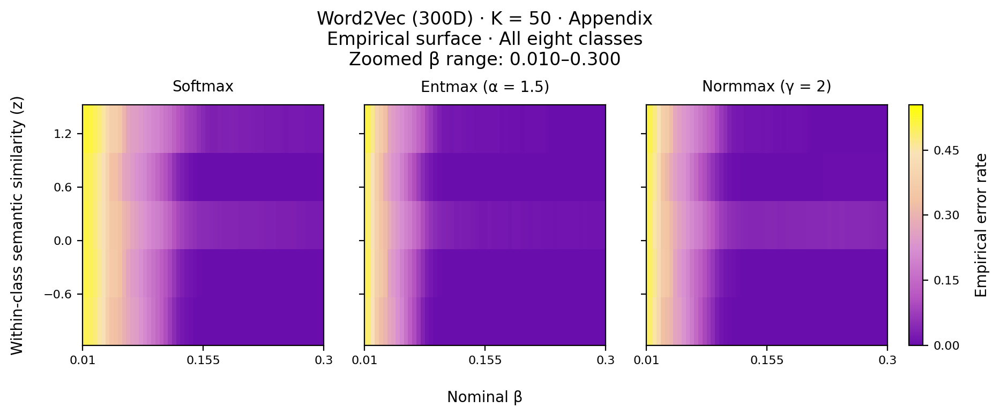

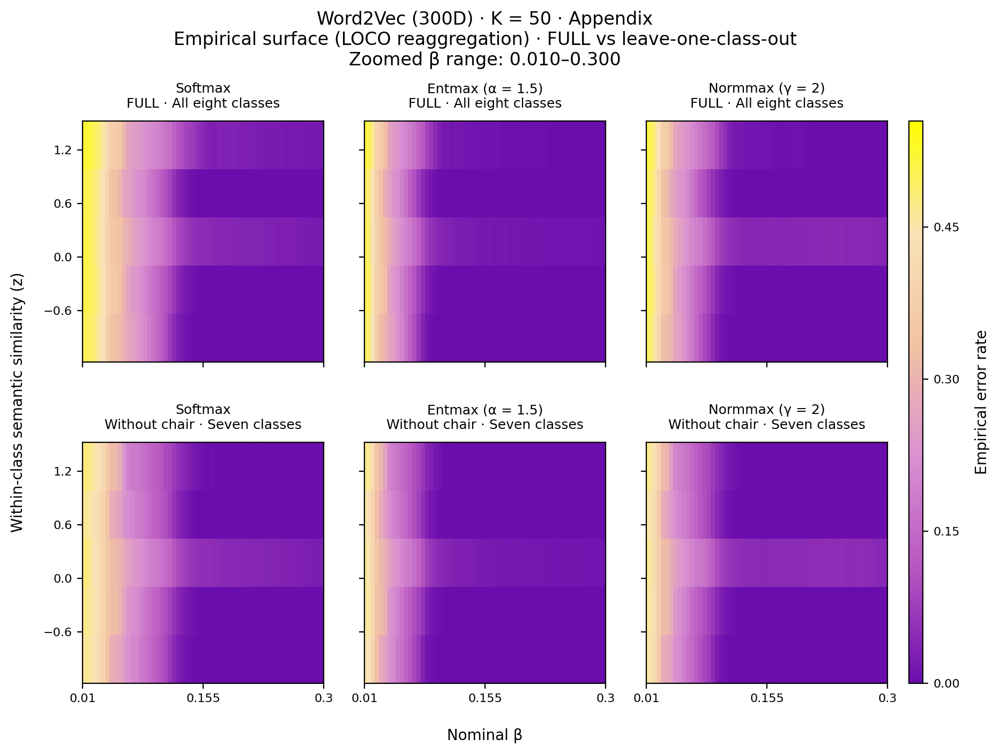

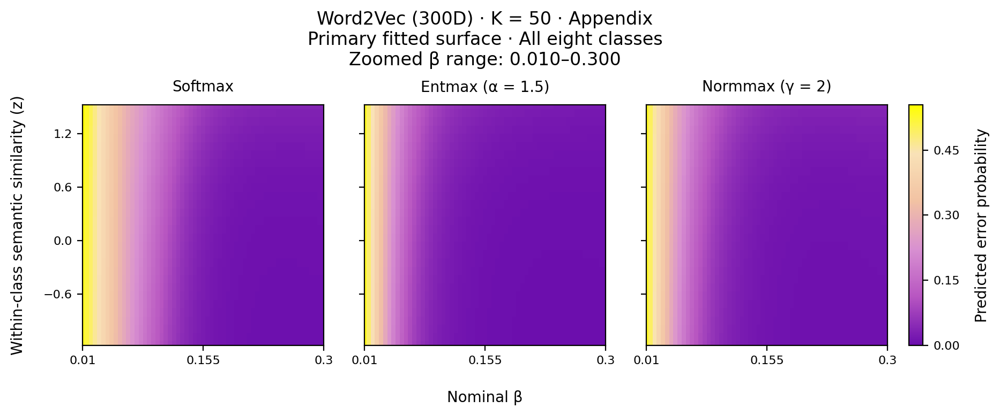

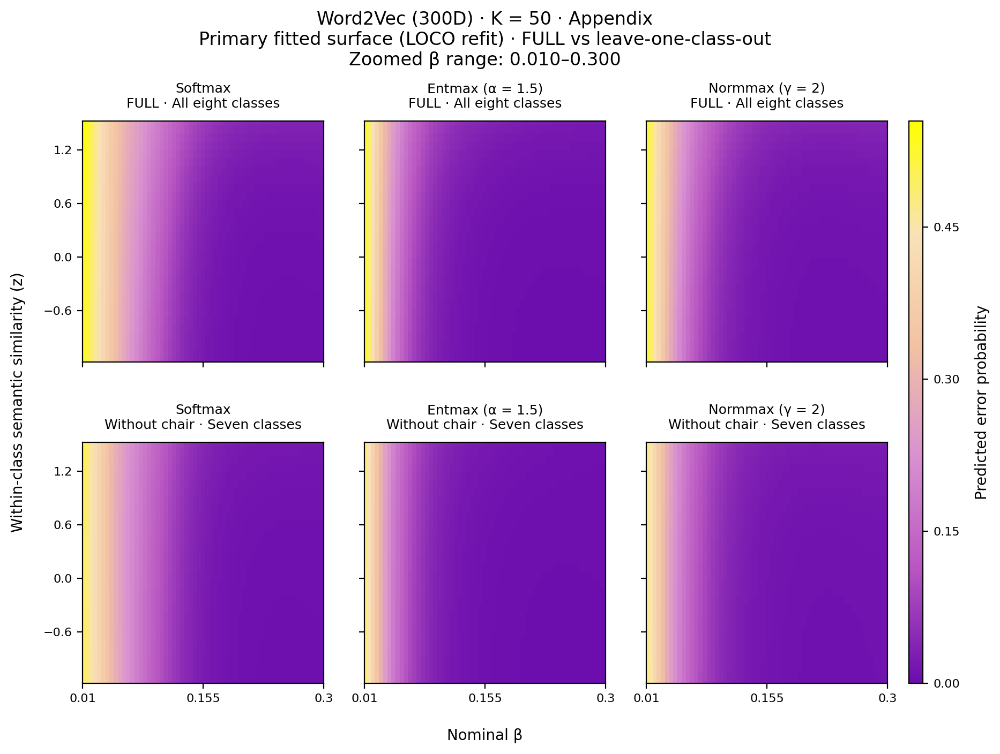

Figuras del anexo W2V K50: \\?\C:\Users\jisaa\Documents\ProyectoTesis\EstudioEstatico\ExperimentoEstatico\SalidasRevision\Figuras\AnexoW2VK50


In [41]:
# CELDA 2 — W2V K50: cuatro figuras compuestas para anexos.
# Ejecutar después de cargar SENSIBILIDAD_K50["w2v"] en el apéndice A del notebook.
BETAS_K50 = {
    "full_empirical": (0.01, 0.3), "full_model": (0.01, 0.3),
    "loco_empirical": (0.01, 0.3), "loco_model": (0.01, 0.3),
}  # None: completo; ejemplos editables: (0.01, 0.15) o (0.05, 0.495).
OMISION_K50 = "chair"  # Misma omisión que en la comparación W2V K40.
COLORES_K50 = None  # Escala común para las cuatro figuras; o (0.0, 1.0).
LADO_PANEL_K50 = 2.25
DPI_K50 = 200
GUARDAR_COMPLETAS_K50 = True

import exp2_pipeline_integrated as _exp_k50
if "w2v" not in globals().get("SENSIBILIDAD_K50", {}):
    raise RuntimeError('Ejecuta antes la celda del apéndice A: SENSIBILIDAD_K50["w2v"] = reuse.cargar_w2v_k50(REPO, ESTRUCTURA).')
RESULTADO_K50 = SENSIBILIDAD_K50["w2v"]
ctx50 = RESULTADO_K50.context
if int(ctx50["K"]) != 50:
    raise ValueError("Se esperaba el resultado W2V K50. No se modifica RESULTS de K40.")
SALIDA_K50 = Path(FIGURES.output_root)/"AnexoW2VK50"
om50 = list(ctx50["labels"]).index(OMISION_K50)
SUPERFICIES_K50 = {"empirical": [], "model": []}
for om in (None, om50):
    grupo_modelo, grupo_empirico = [], []
    tag = "FULL" if om is None else f"LOCO_{om}_{ctx50['labels'][om]}"
    for red in _REDES_PANELES:
        # Lee y autentica los ajustes existentes. No ajusta modelos.
        grupo_modelo.append(_exp_k50.verified_model_surface89(ctx50, red, omitted=om, resolution=30))
        archivo = Path(ctx50["out88"])/"fits"/red/tag/"empirical_5bins.csv"
        if not archivo.is_file():
            raise FileNotFoundError(f"Falta la superficie empírica guardada: {archivo}")
        grupo_empirico.append(_exp_k50.read_surface88(archivo))
    SUPERFICIES_K50["model"].append(grupo_modelo)
    SUPERFICIES_K50["empirical"].append(grupo_empirico)
escala50 = _escala_paneles([s for grupos in SUPERFICIES_K50.values() for grupo in grupos for s in grupo], COLORES_K50)
REGISTRO_FIGURAS_K50 = []
for tipo in ("empirical", "model"):
    REGISTRO_FIGURAS_K50 += guardar_panel_compuesto(
        [list(zip(_TITULOS_REDES_PANELES, SUPERFICIES_K50[tipo][0]))],
        titulo="Word2Vec (300D) · K = 50 · Appendix",
        destino=SALIDA_K50/"PanelesCompuestos", nombre=f"w2v_k50_{tipo}_FULL",
        beta_range=BETAS_K50[f"full_{tipo}"], color_limits=escala50,
        panel_inches=LADO_PANEL_K50, dpi=DPI_K50, guardar_completa=GUARDAR_COMPLETAS_K50,
        surface_kind=tipo, y_edges=ctx50["edges"] if tipo=="empirical" else None,
    )
    REGISTRO_FIGURAS_K50 += guardar_comparacion_loco(
        _filas_loco(SUPERFICIES_K50[tipo], OMISION_K50),
        titulo="Word2Vec (300D) · K = 50 · Appendix",
        destino=SALIDA_K50/"ComparacionesLOCO", nombre=f"w2v_k50_{tipo}_FULL_vs_without_{OMISION_K50}",
        beta_range=BETAS_K50[f"loco_{tipo}"], color_limits=escala50,
        panel_inches=LADO_PANEL_K50, dpi=DPI_K50, guardar_completa=GUARDAR_COMPLETAS_K50,
        surface_kind=tipo, y_edges=ctx50["edges"] if tipo=="empirical" else None,
    )
print("Figuras del anexo W2V K50:", SALIDA_K50)
